In [1]:

# Some basic setup:
# Setup detectron2 logge

import pickle

# import some common libraries
import numpy as np
import json, cv2, random
# import cv2
# import matplotlib.pyplot as plt
# import imutils
from PIL import Image
from PIL import ImageDraw
# from vistats import annotate_brackets
#import seaborn
import itertools
import os
import shutil
import traceback
import sys, os, distutils.core
import torch, detectron2
from detectron2.utils.logger import setup_logger
setup_logger()

# import some common detectron2 utilities
from detectron2 import model_zoo
from detectron2.engine import DefaultPredictor
from detectron2.config import get_cfg
from detectron2.utils.visualizer import Visualizer
from detectron2.data import MetadataCatalog, DatasetCatalog
from detectron2.data.datasets import register_coco_instances
from detectron2.engine import DefaultTrainer
from detectron2.data import build_detection_test_loader, MetadataCatalog
from detectron2.evaluation import COCOEvaluator, inference_on_dataset

/tmp/ipykernel_39/228565739.py:20: DeprecationWarning: The distutils package is deprecated and slated for removal in Python 3.12. Use setuptools or check PEP 632 for potential alternatives
  import sys, os, distutils.core


In [5]:
# rdir = "/mnt/gpu_data/data8/kinoshita_cfos/"
# wsl_pyf = "/mnt/gpu_data/data8/kinoshita_cfos/EM_analysis/" 

rdir = "/home/gpu_data/data8/kinoshita_cfos/"
wsl_pyf = "/home/gpu_data/data8/kinoshita_cfos/EM_analysis/"

In [6]:
from skimage.measure import label, regionprops
from scipy.spatial.distance import cdist
from scipy.ndimage import distance_transform_edt
from collections import defaultdict

def mask_iou(mask1, mask2):
    """
    2 つのバイナリマスク間の IoU（Intersection over Union; 重なり率）を計算する。
    mask1, mask2 : bool 型の 2 次元配列
    """
    intersection = np.logical_and(mask1, mask2).sum()
    union = np.logical_or(mask1, mask2).sum()
    return (intersection / np.sum(mask1)) if union > 0 else 0

def nms_mask_group(indices, pred_masks, scores, threshold=0.2):
    """
    与えられたインデックス群（同一クラス内のインデックス）について、
    スコアが高い順に並べ、マスク同士の IoU が threshold 以上のものを除外（代表１体のみ保持）します。
    
    Parameters:
      indices    : 同一クラス内の候補インスタンスの元のインデックス（numpy.array あるいは list）
      pred_masks : 全インスタンスのマスク配列（shape: (N, H, W)）
      scores     : 全インスタンスのスコア配列（1次元）
      threshold  : IoU のしきい値（例: 0.2）
      
    Returns:
      kept_indices : このグループ内で NMS 処理後に残るインスタンスの元のインデックスのリスト
    """
    if len(indices) == 0:
        return []
    # 候補をスコアの降順でソート（各候補は元のインデックス）
    sorted_indices = sorted(indices, key=lambda i: scores[i], reverse=True)
    kept_indices = []
    
    while sorted_indices:
        curr = sorted_indices.pop(0)
        kept_indices.append(curr)
        remain = []
        for idx in sorted_indices:
            iou = mask_iou(pred_masks[curr], pred_masks[idx])
            # print(iou)
            if iou < threshold:
                remain.append(idx)
            # IoUが threshold 以上なら、重複とみなして除外（代表でない側）
        sorted_indices = remain
    return kept_indices
    

def compute_centroid(mask):
    """
    2次元バイナリマスク画像から最初の連結領域の重心 (row, col) を計算する関数
    """
    labeled_mask = label(mask)
    regions = regionprops(labeled_mask)
    if not regions:
        raise ValueError("マスク画像に有効な領域が見つかりません。")
    return regions[0].centroid  # (row, col)

def extract_vec_indices_by_synapse(synapse_mask, vec_masks):
    """
    vec_masks における各マスク画像の重心座標を計算し、
    その座標が synapse_mask 内 (値が 0 以外) にある場合、その vec マスクのインデックスを返す。

    Parameters:
      synapse_mask : 2次元バイナリマスク (numpy.array)
      vec_masks    : 2次元バイナリマスクのリスト

    Returns:
      synapse マスク内に重心が含まれる vec マスクのインデックスリスト
    """
    indices = []
    centroids =[]
    for idx, vec_mask in enumerate(vec_masks):
        try:
            centroid = compute_centroid(vec_mask)
        except ValueError:
            # マスクに領域がない場合はスキップ
            continue

        # centroidは浮動小数点の (row, col) 座標なので整数に変換
        centroid_int = (int(round(centroid[0])), int(round(centroid[1])))

        # synapseマスク内の centroid の値を確認する
        # 画像外の座標の場合はスキップ
        if not (0 <= centroid_int[0] < synapse_mask.shape[0] and 0 <= centroid_int[1] < synapse_mask.shape[1]):
            continue

        if synapse_mask[centroid_int] > 0:
            indices.append(idx)
            centroids.append(centroid)
    return indices, centroids



def nearest_neighbor_distance(points):
    # 全ての点の組み合わせの距離を計算
    distances = cdist(points, points)
    
    # 自分自身との距離（0）を無視して最小値を取得
    # axis=1で各行の最小値を取得
    nn_distances = np.partition(distances, 1, axis=1)[:, 1]
    
    return nn_distances

def get_candidate_info(synapse_mask, az_masks, distance_threshold):
    """
    シナプスマスクから距離変換を計算し、
    各 az マスク内の最小距離がthreshold以下なら候補として採用する。
    
    Parameters:
      synapse_mask      : 2次元のシナプスバイナリマスク (0 or 1)
      az_masks          : 2次元のazバイナリマスクのリスト
      distance_threshold: 閾値（ピクセル単位）
      
    Returns:
      candidates: リスト
         各候補は辞書形式で { "index": i, "min_distance": d, "mask": az_mask } 
         を格納。
    """
    # distance_transform_edt はゼロとなる場所が特徴となるので、
    # シナプス領域を 1 から 0 に置き換えたものを用いる。
    # つまり、synapse_maskが1の部分が特長となるようにするには、1 - mask を渡す。
    dist_transform = distance_transform_edt(1 - synapse_mask)
    
    candidates = []
    for i, az in enumerate(az_masks):
        # az_mask 内のピクセルそれぞれについてシナプス領域までの距離を抽出
        if np.sum(az) == 0:
            # 有効な領域がなければスキップ
            continue
        min_dist = np.min(dist_transform[az.astype(bool)])
        print(i, min_dist)
        if min_dist <= distance_threshold:
            candidates.append({
                "index": i,
                "min_distance": min_dist,
                "mask": az.astype(bool)  # 重複判定用に bool 型に変更して保持する
            })
    return candidates

def get_candidate_info2(synapse_mask, az_masks, distance_threshold):
    """
    シナプスマスクから距離変換を計算し、
    各 az マスク内の最小距離がthreshold以下なら候補として採用する。
    
    Parameters:
      synapse_mask      : 2次元のシナプスバイナリマスク (0 or 1)
      az_masks          : 2次元のazバイナリマスクのリスト
      distance_threshold: 閾値（ピクセル単位）
      
    Returns:
      candidates: リスト
         各候補は辞書形式で { "index": i, "min_distance": d, "mask": az_mask } 
         を格納。
    """
    # distance_transform_edt はゼロとなる場所が特徴となるので、
    # シナプス領域を 1 から 0 に置き換えたものを用いる。
    # つまり、synapse_maskが1の部分が特長となるようにするには、1 - mask を渡す。
    dist_transform = distance_transform_edt(1 - synapse_mask)
    
    candidates = []
    for i, az in enumerate(az_masks):
        # az_mask 内のピクセルそれぞれについてシナプス領域までの距離を抽出
        if np.sum(az) == 0:
            # 有効な領域がなければスキップ
            continue
        min_dist = np.min(dist_transform[az.astype(bool)])
#         print(i, min_dist)
        if min_dist <= distance_threshold:
            candidates.append(i)
    return candidates

def union_find_init(n):
    """ Union-Find の初期化 """
    return list(range(n))

def union_find_find(parents, i):
    """ 親の検索 """
    if parents[i] != i:
        parents[i] = union_find_find(parents, parents[i])
    return parents[i]

def union_find_union(parents, i, j):
    """ 連結 """
    ri = union_find_find(parents, i)
    rj = union_find_find(parents, j)
    if ri != rj:
        parents[rj] = ri

def group_overlapping_candidates(candidates):
    """
    候補一覧（辞書形式）のうち、マスクの重複（少しでも共通領域があるか）によってグループ化し、
    各グループから代表候補（ここではシナプスまでの最小距離が小さいもの）を返す。
    
    Parameters:
      candidates: リスト{ "index":, "min_distance":, "mask": } の候補
    
    Returns:
      rep_indices: 代表候補の az マスクのインデックスリスト
    """
    n = len(candidates)
    if n == 0:
        return []
    
    parents = union_find_init(n)
    
    # 候補同士のマスクの重複が発生していないか確認
    for i in range(n):
        for j in range(i + 1, n):
            # もし、候補iと候補jで少しでも共通領域( True 同士)があればグループ化
            if np.any(np.logical_and(candidates[i]["mask"], candidates[j]["mask"])):
                union_find_union(parents, i, j)
    
    # グループごとに代表候補を決定
    groups = defaultdict(list)
    for idx in range(n):
        root = union_find_find(parents, idx)
        groups[root].append(candidates[idx])
    
    rep_indices = []
    for group in groups.values():
        # 代表候補として、シナプスまでの距離が最も小さい候補を選ぶ
        rep = min(group, key=lambda x: x["min_distance"])
        rep_indices.append(rep["index"])
    
    return rep_indices

def select_az_candidates(synapse_mask, az_masks, distance_threshold):
    """
    ・synapseマスクとシナプスまでの距離が閾値以下のazマスク画像を候補に抽出する。
    ・候補同士のマスク画像が少しでも重複している場合はグループ化し、代表1枚のみ採用する。
    
    Parameters:
      synapse_mask      : 2次元バイナリマスク (0,1)
      az_masks          : 2次元バイナリマスク画像のリスト
      distance_threshold: 距離の閾値
      
    Returns:
      rep_indices: 条件を満たす代表的な az マスクのインデックスリスト
    """
    # 1. シナプスとの距離が閾値以下の候補を抽出
    candidates = get_candidate_info(synapse_mask, az_masks, distance_threshold)
    # 2. 重複(オーバーラップ)している候補グループから代表を選定
    rep_indices = group_overlapping_candidates(candidates)
    return rep_indices

def calculate_major_axis_length(mask):
    """
    入力: mask - 2次元のバイナリマスク画像（0:背景, 1 or 255:物体）
    出力: 物体の長軸の長さ（pixels）
    
    ※ マスク画像内に複数のオブジェクトが存在する場合は、
       面積が最大のオブジェクトの長軸長を返します。
    """
    # マスクが 255 を物体としている場合、0/1 の二値化
    binary_mask = (mask > 0).astype(np.uint8)

    # ラベル付け
    labeled_mask = label(binary_mask)
    regions = regionprops(labeled_mask)
    
    if len(regions) == 0:
        return 0  # 物体が見つからなかった場合
    # 面積が最大の領域を選択（細長い物体が1つだけの場合は問題ありません）
    target_region = max(regions, key=lambda r: r.area)
    
    return target_region.major_axis_length

def calc_az_vec_dists(az_mask, centroids):
    
    combined_az_mask = np.zeros((az_mask[0].shape[0], az_mask[0].shape[1]), dtype=bool)
    for mask in az_mask:
        combined_az_mask = np.logical_or(combined_az_mask, mask)
        
    distance_map = distance_transform_edt(~combined_az_mask)
    
    # --- 各 vec の重心座標に対して、az マスクまでの距離を計算 ---
    distances = []
    for centroid in centroids:
        # 重心座標は画像座標（row, col）の順になっていると仮定しています。
        # 小数点がある場合は、ここでは最近傍の整数画素 (round で丸める) を利用して距離をサンプリングします
        row = int(round(centroid[0]))
        col = int(round(centroid[1]))
        
        # 画像外にならないようにチェック（オプション）
        row = min(max(row, 0), distance_map.shape[0] - 1)
        col = min(max(col, 0), distance_map.shape[1] - 1)
        
        d = distance_map[row, col]
        distances.append(d)
    return distances

In [7]:
# def run_experiment(val_name, params, run_id):
#     """
#     指定したパラメータで Detectron2 の学習・評価を実行する関数
#     Args:
#       params: 辞書型でハイパーパラメーター（例："SOLVER.BASE_LR", "SOLVER.MAX_ITER" など）
#       run_id: 実験識別用のID（出力フォルダなどに利用）
#     Returns:
#       bbox mAP と評価結果のディクショナリ
#     """
#     cfg = get_cfg()
#     # モデル設定のマージ
#     default_model = "COCO-InstanceSegmentation/mask_rcnn_X_101_32x8d_FPN_3x.yaml"
#     cfg.merge_from_file(model_zoo.get_config_file( params.get("MODEL", default_model)))
    
#     # 学習データセットの指定
#     cfg.DATASETS.TRAIN = (train_name_ori,)
#     cfg.DATASETS.TEST = ()  # 学習中はTestは設定しない
#     cfg.DATALOADER.NUM_WORKERS = 2

#     # モデル重みの初期化（Model Zoo の重みから）
#     cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url( params.get("MODEL", default_model))
    
#     # ハイパーパラメーターの適用
#     cfg.SOLVER.IMS_PER_BATCH = 2
#     cfg.SOLVER.BASE_LR =  float(params.get("SOLVER.BASE_LR", 0.00025))
#     cfg.SOLVER.MAX_ITER = int(params.get("SOLVER.MAX_ITER", 300))
#     cfg.SOLVER.WEIGHT_DECAY = float(params.get("SOLVER.WEIGHT_DECAY", 300))
#     cfg.SOLVER.STEPS = []  # 学習率の減衰は行わない
#     cfg.SOLVER.WARMUP_FACTOR = float(params.get("SOLVER.WARMUP_FACTOR", 300))
#     cfg.SOLVER.WARMUP_ITERS = int(params.get("SOLVER.WARMUP_ITERS", 300))
    
#     cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = int(params.get("MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE", 300))
#     # cfg.MODEL.ANCHOR_GENERATOR.SIZES = (params.get("MODEL.ANCHOR_GENERATOR.SIZES", 300)
#     cfg.MODEL.BACKBONE.FREEZE_AT = int(params.get("MODEL.BACKBONE.FREEZE_AT", 300))
#     cfg.MODEL.RPN.NMS_THRESH = float(params.get("MODEL.RPN.NMS_THRESH", 300))
#     cfg.MODEL.ROI_HEADS.NMS_THRESH_TEST = float(params.get("MODEL.ROI_HEADS.NMS_THRESH_TEST", 300))
    
    
#     cfg.MODEL.ROI_HEADS.NUM_CLASSES = class_num  # 分類するクラス数
    
#     # 出力先ディレクトリの設定（run_idごとに分ける）
#     custom_output_dir = os.path.join(wsl_pyf, "detectron2_trained_model_resize", f"{train_name}_run{run_id}")
#     os.makedirs(custom_output_dir, exist_ok=True)
#     cfg.OUTPUT_DIR = custom_output_dir

#     print(f"--- Run {run_id} start with params: {params} ---")
#     # 学習実行
#     trainer = DefaultTrainer(cfg)
#     trainer.resume_or_load(resume=False)
#     trainer.train()

#     # ----------------------------------------------------------------
#     # 学習済みモデルを用いて評価
#     # ----------------------------------------------------------------
#     # 評価用のデータセット登録（すでに登録済みの場合は名前を変更）
#     val_dataset_name = f"{val_name}_val"
#     try:
#         val_data_dir = os.path.join(wsl_pyf, "coco_dir_test_syn")
#         val_annotation_path = os.path.join(val_data_dir, "annotations.json")
#         register_coco_instances(val_dataset_name, {}, val_annotation_path, val_data_dir)
#     except:
#         traceback.print_exc()

#     # 評価用設定に変更
#     cfg.DATASETS.TEST = (val_dataset_name,)
#     cfg.MODEL.WEIGHTS = os.path.join(custom_output_dir, "model_final.pth")
#     cfg.MODEL.DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
    
#     # 予測器の作成
#     predictor = DefaultPredictor(cfg)
    
#     evaluator = COCOEvaluator(val_dataset_name, cfg, False, output_dir=custom_output_dir)
#     val_loader = build_detection_test_loader(cfg, val_dataset_name)
#     metrics = inference_on_dataset(predictor.model, val_loader, evaluator)
    
#     bbox_map = metrics.get("bbox", None)
#     print(f"--- Run {run_id} finished: bbox mAP = {bbox_map} ---")
#     return bbox_map, metrics


def create_mask_for_image(test_folder, json_file, target_file_name, target_category_id=0):
    """
    JSONファイル（COCO形式）の情報から、指定した画像ファイル名(target_file_name)
    に対応する画像の、target_category_id の全セグメンテーションを統合したマスクを生成します。
    
    Parameters:
      json_file (str): アノテーションJSONのファイルパス
      target_file_name (str): 対象画像のファイル名（例："JPEGImages/Keiko_9401_SD005.jpg"）
      target_category_id (int, optional): 対象のカテゴリID（デフォルトは 0）
      
    Returns:
      mask (PIL.Image): 統合マスク（モード "L", 0: 背景, 1: 塗りつぶし領域）
      img (PIL.Image): 対象画像（存在する場合）
      img_info (dict): 対象画像の情報（サイズ・IDなど）
    """
    # JSONファイルの読み込み
    with open(json_file, "r") as f:
#         print("open {}".format(json_file))
        data = json.load(f)
#     print(target_file_name)
    
   
    
    # 対象画像情報の検索（file_name の一致を条件）
    img_info = None
    for info in data["images"]:
#         print(target_file_name.endswith(info["file_name"]))
#         print(info["file_name"])
        # JSON内の file_name にパスが含まれている場合もあるので、末尾部分でチェック
#         if target_file_name.endswith(info["file_name"]) or info["file_name"] in target_file_name:
        if target_file_name in info["file_name"]:
            img_info = info
            break

    if img_info is None:
        raise ValueError(f"指定の画像ファイル名 {target_file_name} がJSON内に見つかりません。")
        
    # 画像の読み込み
    if os.path.exists(wsl_pyf+"/"+test_folder+"/JPEGImages/"+target_file_name):
        img = Image.open(wsl_pyf+"/"+test_folder+"/JPEGImages/"+target_file_name).convert("RGB")
    else:
        raise ValueError(f"画像ファイル {target_file_name} が存在しません。")
        
    width, height = img_info["width"], img_info["height"]
    
    # 空のマスク画像（モード "L"：グレースケール）を作成（初期値0＝背景）
    mask = Image.new("L", (width, height), 0)
    draw = ImageDraw.Draw(mask)
    
    # 対象画像のimage_idに一致し、かつ対象category_id のアノテーションを集めて統合する
    for ann in data["annotations"]:
        if ann["image_id"] != img_info["id"]:
            continue
        if ann["category_id"] != target_category_id:
            continue
        
        # segmentationはポリゴンの座標リストのリスト（例: [[x1, y1, x2, y2, ...]]）
        for seg in ann["segmentation"]:
            # ImageDraw.polygonは座標リスト形式 [x1, y1, x2, y2, …] を受け取るのでそのままでOK
            draw.polygon(seg, outline=1, fill=1)
            
    mask = np.array(mask)
    
    return mask

def compute_fscore(test_mask, target_mask):
    """
    二値マスクの ndarray (0,1) である test_mask と target_mask の F1スコアを計算する関数。
    
    Parameters:
      test_mask (ndarray): 評価対象のマスク
      target_mask (ndarray): 正解（ゴールドスタンダード）のマスク
      
    Returns:
      float: F1スコア
    """
    # フラット化して各画素の評価を行う
    test_flat = test_mask.flatten()
    target_flat = target_mask.flatten()
    
    # True Positive, False Positive, False Negativeの画素数を計算
    tp = np.sum((test_flat == 1) & (target_flat == 1))
    fn = np.sum((test_flat == 1) & (target_flat == 0))
    fp = np.sum((test_flat == 0) & (target_flat == 1))
    
    # 分母が0の場合のチェック（両方共マスクが全く1でなければ0とする）
    if (2 * tp + fp + fn) == 0:
        return 0.0
    
    # F1 score(=Fscore) の計算
    f1 = (2 * tp) / (2 * tp + fp + fn)
    return f1


def compute_fscore_all(test_mask, target_mask):
    """
    二値マスクの ndarray (0,1) である test_mask と target_mask の F1スコアを計算する関数。
    
    Parameters:
      test_mask (ndarray): 評価対象のマスク
      target_mask (ndarray): 正解（ゴールドスタンダード）のマスク
      
    Returns:
      float: F1スコア
    """
    # フラット化して各画素の評価を行う
    test_flat = test_mask.flatten()
    target_flat = target_mask.flatten()
    
    # True Positive, False Positive, False Negativeの画素数を計算
    tp = np.sum((test_flat == 1) & (target_flat == 1))
    tn = np.sum((test_flat == 0) & (target_flat == 0))
    fn = np.sum((test_flat == 1) & (target_flat == 0))
    fp = np.sum((test_flat == 0) & (target_flat == 1))
    
    # 分母が0の場合のチェック（両方共マスクが全く1でなければ0とする）
    if (2 * tp + fp + fn) == 0:
        return 0.0
    
    # F1 score(=Fscore) の計算
    f1 = (2 * tp) / (2 * tp + fp + fn)
    
    # Sensitivity (再現率, 真陽性率)
    # 定義: TP / (TP + FN)
    denom_sens = (tp + fn)
    sense = tp / denom_sens if denom_sens > 0 else 0.0

    # Specificity (特異度, 真陰性率)
    # 定義: TN / (TN + FP)
    denom_spec = (tn + fp)
    spe = tn / denom_spec if denom_spec > 0 else 0.0
    
    
   
    return f1, sense, spe



def run_experiment2(train_name_ori, val_name, params, run_id, overlap_del, batch_norm, ROI_Norm, area_th, mask_th):
    """
    指定したパラメータで Detectron2 の学習・評価を実行する関数
    Args:
      params: 辞書型でハイパーパラメーター（例："SOLVER.BASE_LR", "SOLVER.MAX_ITER" など）
      run_id: 実験識別用のID（出力フォルダなどに利用）
    Returns:
      bbox mAP と評価結果のディクショナリ
    """
    cfg = get_cfg()
    # モデル設定のマージ
    default_model = "COCO-InstanceSegmentation/mask_rcnn_X_101_32x8d_FPN_3x.yaml"
    
    if not "new_baselines" in params["MODEL"]:
        cfg.merge_from_file(model_zoo.get_config_file( params.get("MODEL", default_model)))
    else:
        cfg.merge_from_file(wsl_pyf + "/detectron2/configs/"+params["MODEL"])
    
    # 学習データセットの指定
    
    m = params["MODEL"]
#     lr = float(params["SOLVER.BASE_LR"])
#     max_iter = int(params["SOLVER.MAX_ITER"])
#     wd  =float(params["SOLVER.WEIGHT_DECAY"])
#     wf= float(params["SOLVER.WARMUP_FACTOR"])
#     wi = int(params["SOLVER.WARMUP_ITERS"])
#     bs = int(params["MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE"])
    # anchor = float(params["MODEL.ANCHOR_GENERATOR.SIZES":anchor,
#     freeze = int(params["MODEL.BACKBONE.FREEZE_AT"])
#     nms_th = float(params["MODEL.RPN.NMS_THRESH"])
#     ////
    
    
    

    
    
    cfg.DATASETS.TRAIN = (train_name_ori,)
    cfg.DATASETS.TEST = ()  # 学習中はTestは設定しない
    cfg.DATALOADER.NUM_WORKERS = 0

    # モデル重みの初期化（Model Zoo の重みから）
    cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url( params.get("MODEL", default_model))
    
    # ハイパーパラメーターの適用
    cfg.SOLVER.IMS_PER_BATCH =  params.get("IMS_PER_BATCH", 1)
    
    
    print("model", params["MODEL"])
#     print("wd", params["SOLVER.WEIGHT_DECAY"])
    if params["SOLVER.BASE_LR"] !=None:
        lr = float(params["SOLVER.BASE_LR"])
        cfg.SOLVER.BASE_LR =  float(params.get("SOLVER.BASE_LR", 0.00025))
#     else:
#         lr = None #params["SOLVER.BASE_LR"]
    
    if params["SOLVER.MAX_ITER"] != None:
        max_iter = int(params["SOLVER.MAX_ITER"])
        cfg.SOLVER.MAX_ITER = int(params.get("SOLVER.MAX_ITER", 300))
#     else:
#         max_iter = None
    
    if params["SOLVER.WEIGHT_DECAY"] != None:
        wd  =float(params["SOLVER.WEIGHT_DECAY"])
        cfg.SOLVER.WEIGHT_DECAY = float(params.get("SOLVER.WEIGHT_DECAY", 300))
#     else:
#         wd = None
        
    if params["SOLVER.WARMUP_FACTOR"] != None:
        wf = float(params["SOLVER.WARMUP_FACTOR"])
        cfg.SOLVER.WARMUP_FACTOR = float(params.get("SOLVER.WARMUP_FACTOR", 300))
#     cfg.SOLVER.STEPS = []  # 学習率の減衰は行わない


    if params["SOLVER.WARMUP_ITERS"] != None:
        wi = float(params["SOLVER.WARMUP_ITERS"])
        cfg.SOLVER.WARMUP_ITERS = int(params.get("SOLVER.WARMUP_ITERS", 300))
        
    
    if params["MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE"] != None:
        bs =int(params["MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE"])
        cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = int(params.get("MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE", 300))
        
    if params["MODEL.ANCHOR_GENERATOR.SIZES"] != None:
        anchor = params["MODEL.ANCHOR_GENERATOR.SIZES"]
        cfg.MODEL.ANCHOR_GENERATOR.SIZES = (params.get("MODEL.ANCHOR_GENERATOR.SIZES", 300))
                                            
    if params["MODEL.BACKBONE.FREEZE_AT"] != None:
        freeze = int(params["MODEL.BACKBONE.FREEZE_AT"])
        cfg.MODEL.BACKBONE.FREEZE_AT = int(params.get("MODEL.BACKBONE.FREEZE_AT", 300))
        
    if params["SOLVER.GAMMA"] != None:
        gamma = float(params["SOLVER.GAMMA"])
        cfg.SOLVER.GAMMA = float(params.get("SOLVER.GAMMA", 300))
        
    if params["SOLVER.STEPS"] != None:
        steps = params["SOLVER.STEPS"]
        cfg.SOLVER.STEPS = (params.get("SOLVER.STEPS", 300))
                                            
    if params["MODEL.RPN.NMS_THRESH"] != None:
        nms_th = float(params["MODEL.RPN.NMS_THRESH"])
        cfg.MODEL.RPN.NMS_THRESH = float(params.get("MODEL.RPN.NMS_THRESH", 300))
                                            
    if params["MODEL.ROI_HEADS.NMS_THRESH_TEST"] != None:
        nms_th_t = float(params["MODEL.ROI_HEADS.NMS_THRESH_TEST"])
        cfg.MODEL.ROI_HEADS.NMS_THRESH_TEST = float(params.get("MODEL.ROI_HEADS.NMS_THRESH_TEST", 300))
    
    #adding
    if params["MODEL.ROI_HEADS.POSITIVE_FRACTION"] != None:
        pos_r = float(params["MODEL.ROI_HEADS.POSITIVE_FRACTION"])
        cfg.MODEL.ROI_HEADS.POSITIVE_FRACTION = float(params.get("MODEL.ROI_HEADS.POSITIVE_FRACTION", 300))
    if params["MODEL.ROI_HEADS.SCORE_THRESH_TEST"] != None:
        score_th_t = float(params["MODEL.ROI_HEADS.SCORE_THRESH_TEST"])
        cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = float(params.get("MODEL.ROI_HEADS.SCORE_THRESH_TEST", 300))
        
    if params["MODEL.RPN.PRE_NMS_TOPK_TRAIN"] != None:
        pre_nms_tr = int(params["MODEL.RPN.PRE_NMS_TOPK_TRAIN"])
        cfg.MODEL.RPN.PRE_NMS_TOPK_TRAIN = int(params.get("MODEL.RPN.PRE_NMS_TOPK_TRAIN", 300))
    if params["MODEL.RPN.POST_NMS_TOPK_TRAIN"] != None:
        post_nms_tr = int(params["MODEL.RPN.POST_NMS_TOPK_TRAIN"])
        cfg.MODEL.RPN.POST_NMS_TOPK_TRAIN = int(params.get("MODEL.RPN.POST_NMS_TOPK_TRAIN", 300))
    if params["MODEL.RPN.PRE_NMS_TOPK_TEST"] != None:
        pre_nms_te = int(params["MODEL.RPN.PRE_NMS_TOPK_TEST"])
        cfg.MODEL.RPN.PRE_NMS_TOPK_TEST = int(params.get("MODEL.RPN.PRE_NMS_TOPK_TEST", 300))
    if params["MODEL.RPN.POST_NMS_TOPK_TEST"] != None:
        post_nms_te = int(params["MODEL.RPN.POST_NMS_TOPK_TEST"])
        cfg.MODEL.RPN.POST_NMS_TOPK_TEST = int(params.get("MODEL.RPN.POST_NMS_TOPK_TEST", 300))
        
    #fixed
    
    cfg.SOLVER.LR_SCHEDULER_NAME = "WarmupCosineLR"
    cfg.MODEL.ANCHOR_GENERATOR.ASPECT_RATIOS     = [[0.33,0.5,1.0,2.0,3.0]]
    cfg.MODEL.RPN.MIN_SIZE                       = 0
    cfg.MODEL.RPN.IOU_THRESHOLDS = [0.2, 0.4]
    cfg.MODEL.RPN.IOU_LABELS     = [0, -1, 1]
    
    cfg.MODEL.ROI_BOX_CASCADE_HEAD.IOU_THRESHOLDS       = [0.4, 0.5, 0.6]
    cfg.MODEL.ROI_BOX_CASCADE_HEAD.BBOX_REG_WEIGHTS     = [
        (10., 10., 5., 5.),
        (20., 20., 10., 10.),
        (30., 30., 15., 15.)
    ]
    cfg.MODEL.ROI_BOX_CASCADE_HEAD.STAGE_WEIGHTS        = [1.0, 0.75, 0.5]
    
    cfg.INPUT.AUG = [
    # 1) ランダムフリップ
    {"type": "RandomFlip",  "horizontal": True, "vertical": True, "prob": 0.5},

    # 2) Color Jitter
    {"type": "RandomBrightness",  "prob": 0.8, "intensity_min": 0.8, "intensity_max": 1.2},
    {"type": "RandomContrast",    "prob": 0.8, "intensity_min": 0.8, "intensity_max": 1.2},
    {"type": "RandomSaturation",  "prob": 0.8, "intensity_min": 0.8, "intensity_max": 1.2},
    {"type": "RandomLighting",    "prob": 0.8, "scale": 0.1},

    # 3) Copy-Paste
    {"type": "CopyPasteAug",      "prob": 0.5, "keep_background": True, "max_paste_instances": 5},

    # 4) MixUp
    {"type": "MixUp",             "prob": 0.5, "alpha": 0.2},
]

    
    if batch_norm != "FrozenBN":
        cfg.MODEL.BACKBONE.FROZEN_BN = "False"
    
    if not "new_baselines/mask_rcnn_regnety_4gf_dds_FPN_400ep_LSJ" in  params["MODEL"]:
        cfg.MODEL.RESNETS.NORM =batch_norm
        cfg.MODEL.FPN.NORM = batch_norm
        cfg.MODEL.ROI_HEADS.NORM = batch_norm
        
    
        
        
        
#     if batch_norm == "GN":
#         if "Misc" in params["MODEL"]:
#             nm_size = int(params["MODEL.GROUP_NORM.NUM_GROUPS"])
            
#             cfg.MODEL.GROUP_NORM.NUM_GROUPS = nm_size
            
#     if not "new_baselines" in params["MODEL"]:
#         cfg.MODEL.ROI_BOX_HEAD.NORM = ROI_Norm
            

#     if "new_baselines" in params["MODEL"]:
#         if params["MODEL.ROI_HEADS.POOLER_SAMPLING_RATIO"]!= None:
#             cfg.MODEL.ROI_HEADS.POOLER_SAMPLING_RATIO = int(params["MODEL.ROI_HEADS.POOLER_SAMPLING_RATIO"])
    

    cfg.MODEL.ROI_HEADS.NUM_CLASSES = class_num  # 分類するクラス数
    print("Gamma", cfg.SOLVER.GAMMA)
    print("steps", cfg.SOLVER.STEPS)
                                            
#train_name = train_name_ori + "/{}/lr{}_maxiter{}_wd{}_wf{}_wi{}_bs{}_freeze{}_nmsth{}_nmstht{}_RESnorm{}_ROInorm{}_GN{}_psr{}".format(m, cfg.SOLVER.BASE_LR, cfg.SOLVER.MAX_ITER, cfg.SOLVER.WEIGHT_DECAY, cfg.SOLVER.WARMUP_FACTOR, cfg.SOLVER.WARMUP_ITERS, cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE, cfg.MODEL.BACKBONE.FREEZE_AT, cfg.MODEL.RPN.NMS_THRESH, cfg.MODEL.ROI_HEADS.NMS_THRESH_TEST, batch_norm, ROI_Norm, cfg.MODEL.GROUP_NORM.NUM_GROUPS, cfg.MODEL.ROI_HEADS.POOLER_SAMPLING_RATIO)


#     train_name = train_name_ori + "/{}/lr{}_maxiter{}_wd{}_wf{}_wi{}_bs{}_freeze{}_nmsth{}_nmstht{}_RESnorm{}_ROInorm{}_GN{}_psr{}".format(m, cfg.SOLVER.BASE_LR, cfg.SOLVER.MAX_ITER, cfg.SOLVER.WEIGHT_DECAY, cfg.SOLVER.WARMUP_FACTOR, cfg.SOLVER.WARMUP_ITERS, cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE, cfg.MODEL.BACKBONE.FREEZE_AT, cfg.MODEL.RPN.NMS_THRESH, cfg.MODEL.ROI_HEADS.NMS_THRESH_TEST, batch_norm, ROI_Norm, cfg.MODEL.RESNETS.NORM, cfg.MODEL.ROI_HEADS.POOLER_SAMPLING_RATIO)
    
    if "Misc" in params["MODEL"]:
#         if params["IMS_PER_BATCH"] == 1:
#             train_name = train_name_ori + "/{}/lr{}_maxiter{}_wd{}_wf{}_wi{}_bs{}_freeze{}_nmsth{}_nmstht{}_RESnorm{}_ROInorm{}".format(m, cfg.SOLVER.BASE_LR, cfg.SOLVER.MAX_ITER, cfg.SOLVER.WEIGHT_DECAY, cfg.SOLVER.WARMUP_FACTOR, cfg.SOLVER.WARMUP_ITERS, cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE, cfg.MODEL.BACKBONE.FREEZE_AT, cfg.MODEL.RPN.NMS_THRESH, cfg.MODEL.ROI_HEADS.NMS_THRESH_TEST, cfg.MODEL.RESNETS.NORM, cfg.MODEL.ROI_BOX_HEAD.NORM)
#         else:
        train_name = train_name_ori + "/{}/lr{}_maxiter{}_wd{}_wf{}_wi{}_imsbs{}_bs{}_freeze{}_gamma{}_steps{}-{}_posr{}_scoreth{}_nmsth{}_nmstht{}_pretr{}_posttr{}_prete{}_postte{}_RESnorm{}_ROInorm{}".format(m, cfg.SOLVER.BASE_LR, cfg.SOLVER.MAX_ITER, cfg.SOLVER.WEIGHT_DECAY, cfg.SOLVER.WARMUP_FACTOR, cfg.SOLVER.WARMUP_ITERS, 
        cfg.SOLVER.IMS_PER_BATCH,  cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE, cfg.MODEL.BACKBONE.FREEZE_AT, cfg.SOLVER.GAMMA, cfg.SOLVER.STEPS[0],cfg.SOLVER.STEPS[1], 
        cfg.MODEL.ROI_HEADS.POSITIVE_FRACTION, cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST, cfg.MODEL.RPN.NMS_THRESH, cfg.MODEL.ROI_HEADS.NMS_THRESH_TEST,
        cfg.MODEL.RPN.PRE_NMS_TOPK_TRAIN,  cfg.MODEL.RPN.POST_NMS_TOPK_TRAIN,cfg.MODEL.RPN.PRE_NMS_TOPK_TEST,  cfg.MODEL.RPN.POST_NMS_TOPK_TEST, 
        cfg.MODEL.RESNETS.NORM, cfg.MODEL.ROI_BOX_HEAD.NORM)
      
    
    if "COCO" in params["MODEL"]:
        train_name = train_name_ori + "/{}/lr{}_maxiter{}_wd{}_wf{}_wi{}_bs{}_freeze{}_nmsth{}_nmstht{}_RESnorm{}_ROInorm{}".format(m, cfg.SOLVER.BASE_LR, cfg.SOLVER.MAX_ITER, cfg.SOLVER.WEIGHT_DECAY, cfg.SOLVER.WARMUP_FACTOR, cfg.SOLVER.WARMUP_ITERS, cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE, cfg.MODEL.BACKBONE.FREEZE_AT, cfg.MODEL.RPN.NMS_THRESH, cfg.MODEL.ROI_HEADS.NMS_THRESH_TEST, cfg.MODEL.RESNETS.NORM, cfg.MODEL.ROI_BOX_HEAD.NORM)
    if "new_baselines" in params["MODEL"]:
        if not "mask_rcnn_regnety_4gf_dds_FPN_400ep_LSJ":
            train_name = train_name_ori + "/{}/lr{}_maxiter{}_wd{}_wf{}_wi{}_bs{}_freeze{}_nmsth{}_nmstht{}_RESnorm{}_psr{}".format(m, cfg.SOLVER.BASE_LR, cfg.SOLVER.MAX_ITER, cfg.SOLVER.WEIGHT_DECAY, cfg.SOLVER.WARMUP_FACTOR, cfg.SOLVER.WARMUP_ITERS, cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE, cfg.MODEL.BACKBONE.FREEZE_AT, cfg.MODEL.RPN.NMS_THRESH, cfg.MODEL.ROI_HEADS.NMS_THRESH_TEST, cfg.MODEL.RESNETS.NORM, cfg.MODEL.ROI_HEADS.POOLER_SAMPLING_RATIO)
        else:
            train_name = train_name_ori + "/{}/lr{}_maxiter{}_wd{}_wf{}_wi{}_bs{}_freeze{}_nmsth{}_nmstht{}_psr{}".format(m, cfg.SOLVER.BASE_LR, cfg.SOLVER.MAX_ITER, cfg.SOLVER.WEIGHT_DECAY, cfg.SOLVER.WARMUP_FACTOR, cfg.SOLVER.WARMUP_ITERS, cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE, cfg.MODEL.BACKBONE.FREEZE_AT, cfg.MODEL.RPN.NMS_THRESH, cfg.MODEL.ROI_HEADS.NMS_THRESH_TEST, cfg.MODEL.ROI_HEADS.POOLER_SAMPLING_RATIO)
     
    
#     train_name = train_name_ori + "/{}/lr{}_maxiter{}_wd{}_wf{}_wi{}_bs{}_freeze{}_nmsth{}_nmstht{}".format(m, cfg.SOLVER.BASE_LR, cfg.SOLVER.MAX_ITER, cfg.SOLVER.WEIGHT_DECAY, cfg.SOLVER.WARMUP_FACTOR, cfg.SOLVER.WARMUP_ITERS, cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE, cfg.MODEL.BACKBONE.FREEZE_AT, cfg.MODEL.RPN.NMS_THRESH, cfg.MODEL.ROI_HEADS.NMS_THRESH_TEST)
#     print(train_name)
                                            
    
    # 出力先ディレクトリの設定（run_idごとに分ける）
    custom_output_dir = os.path.join(wsl_pyf, out_dir_name, f"{train_name}")
    if not os.path.exists(os.path.join(custom_output_dir, "model_final.pth")):                                
        os.makedirs(custom_output_dir, exist_ok=True)
        cfg.OUTPUT_DIR = custom_output_dir

        # === ここから再開ロジック追加 ===
        # 出力ディレクトリ内の model_*.pth（model_final.pth を除く）を列挙
        ckpts = sorted(glob.glob(os.path.join(cfg.OUTPUT_DIR, "model_*.pth")))
        # 最後に置かれたチェックポイントがあれば
        if ckpts:
            # model_final.pth は再開対象外
            ckpts = [p for p in ckpts if not p.endswith("model_final.pth")]
        if ckpts:
            last_ckpt = ckpts[-1]
            print(f"🔄 途中チェックポイントを発見 → {last_ckpt} から再開します")
            cfg.MODEL.WEIGHTS = last_ckpt
            resume_flag = True
        else:
            # 未学習 or 途中モデルなし
            print("▶️ 新規学習を開始します")
            cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(
                params.get("MODEL", default_model)
            )
            resume_flag = False

        print(f"--- Run {train_name} start with params: {params} ---")
        # 学習実行
        trainer = DefaultTrainer(cfg)
    # resume=True なら last_ckpt を、False なら cfg.MODEL.WEIGHTS（初期重み）から
        trainer.resume_or_load(resume=resume_flag)
        trainer.train()
    else:                                        
        cfg.OUTPUT_DIR = custom_output_dir

    # ----------------------------------------------------------------
    # 学習済みモデルを用いて評価
    # ----------------------------------------------------------------
    # 評価用のデータセット登録（すでに登録済みの場合は名前を変更）
    val_dataset_name = f"{val_name}_val"
    try:
        val_data_dir = os.path.join(wsl_pyf, test_folder)
        val_annotation_path = os.path.join(val_data_dir, "annotations.json")
        register_coco_instances(val_dataset_name, {}, val_annotation_path, val_data_dir)
    except:
        traceback.print_exc()



    

    # 評価用設定に変更
    cfg.DATASETS.TEST = (val_dataset_name,)
    cfg.MODEL.WEIGHTS = os.path.join(custom_output_dir, "model_final.pth")
    cfg.MODEL.DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
    #     cfg.MODEL.DEVICE = "cpu"
    
    # 予測器の作成
    predictor = DefaultPredictor(cfg)

    #applied to test datasets
#     threshold =   #remove masks duplicated %
#     area_th = 300
    img_fol_name = test_folder#"coco_dir_test_syn_resize"
    img_fol = wsl_pyf + "/"+img_fol_name+"/JPEGImages/"
                                            
    if overlap_del == True:                           
        save_fol = custom_output_dir + "/"+ img_fol_name +"/"
        os.makedirs(save_fol, exist_ok=True)
    else:
        save_fol = custom_output_dir + "/"+ img_fol_name +"_overlap"+"/"
        os.makedirs(save_fol, exist_ok=True)                                     

    #img保存用
#     save_fol2 =os.path.join(win_pyf, "detectron2_trained_model_pre", f"{train_name}") + "/"+ img_fol_name +"/"
#     os.makedirs(save_fol2, exist_ok=True)
    f_score_li = []
    sense_li = []
    spe_li = []
    
    if not os.path.exists(custom_output_dir + "/"+ img_fol_name + "/fscore.csv") or not os.path.exists(custom_output_dir + "/"+ img_fol_name + "/sense.csv") or not os.path.exists(custom_output_dir + "/"+ img_fol_name + "/spe.csv"):
        
        for n, fname in enumerate(os.listdir(img_fol)):
            # if n>0:
            #     continue
            print(fname)
            im = cv2.imread(img_fol + "/"+fname) #tifffile.imread(imgPath) #
            # print(im.size)
            outputs = predictor(im)

            # outputs["instances"] を CPU に移動
            instances = outputs["instances"].to("cpu")

            # 各インスタンスのマスクとスコア，クラスを取得
            pred_masks = instances.pred_masks.cpu().numpy()  # shape: (N, H, W) ※ bool 型が望ましい
            scores = instances.scores.cpu().numpy()            # shape: (N,)
            pred_classes = instances.pred_classes.cpu().numpy()  # 各インスタンスのクラス（番号）


            if overlap_del ==True:
                # クラスごとにグループ分けして NMS を実施
                final_keep = []
                unique_classes = np.unique(pred_classes)
                for cls in unique_classes:
                    # 現在のクラスに属するインデックス取得
                    cls_indices = np.where(pred_classes == cls)[0]
                    kept = nms_mask_group(cls_indices, pred_masks, scores, mask_th)
                    final_keep.extend(kept)

                # フィルタリング後の Instances を作成
                instances = instances[final_keep]
    
            pred_masks = instances.pred_masks.cpu().numpy()  # shape: (N, H, W) ※ bool 型が望ましい
            pred_classes = instances.pred_classes.cpu().numpy()  

            #limit in presynapse with az
            pair_ind = []
            
            
            syn_ind= np.where(pred_classes == 0)[0]
            az_ind= np.where(pred_classes == 1)[0] 

            syn_masks = np.array(pred_masks[syn_ind])
            az_masks = np.array(pred_masks[az_ind])



            for m, syn_mask in enumerate(syn_masks):
                # if m!=1:
                #     continue

                #find az in a synapse
                syn_az_inds = get_candidate_info2(syn_mask, az_masks, distance_threshold)
                if len(syn_az_inds) != 0:
                    #add presyn with az to list
                    pair_ind.append(syn_ind[m])

                    #add candidate az_ind to list
                    for j in syn_az_inds:
                        pair_ind.append(az_ind[j])

            instances = instances[pair_ind]

            with open(save_fol + "/" + fname.replace(".jpg",".pkl"), 'wb') as f:
                pickle.dump(instances, f)

            # ----- 可視化（検出結果の重複が大きいものは除外済み）-----
            # bounding box の数に合わせた空文字列のリストを作成（ラベルの記述が不要な場合）
            empty_labels = [""] * len(instances)

            # Metadata の取得（学習時のデータセットのメタ情報）
            metadata = MetadataCatalog.get(cfg.DATASETS.TRAIN[0])


            v = Visualizer(im[:, :, ::-1], metadata, scale=0.8)

            # overlay_instances() を呼び出して、bounding box のみ描画（labels は空文字なので何も表示されない）
            v = v.overlay_instances(
                boxes=instances.pred_boxes,
                labels=empty_labels,
                assigned_colors=None  # または None のままでも OK。既定の色が使われる
            )
            # MetadataCatalog.get("mydataset").thing_classes = ["synapse", "az"]
            # v = Visualizer(im[:, :, ::-1], MetadataCatalog.get(cfg.DATASETS.TRAIN[0]), scale=0.8)

            # v = v.draw_instance_predictions(outputs["instances"].to("cpu"))
            # 画像を表示
            result_image = v.get_image()[:, :, ::-1]
            # cv2.imshow("result", result_image)

            # 画像をJPEG形式で保存

            cv2.imwrite(save_fol + "/" + fname, result_image)
    #         cv2.imwrite(save_fol2 + "/" + fname, result_image)

            # # 画像を表示するためのウィンドウを待機する
            # cv2.waitKey(0)
            # cv2.destroyAllWindows()


            #automatic validation
            test_mask = create_mask_for_image(test_folder, val_annotation_path, fname, 0)
            target_mask = np.max(np.array(instances.pred_masks), axis=0)
            f_score, sense, spe = compute_fscore_all(test_mask, target_mask)

    #         print("fscore: ", f_score)
            f_score_li.append(f_score)
            sense_li.append(sense)
            spe_li.append(spe)
            
        print(f_score_li)

        np.savetxt(custom_output_dir + "/"+ img_fol_name + "/fscore.csv", np.array(f_score_li), delimiter=",")
        np.savetxt(custom_output_dir + "/"+ img_fol_name + "/sense.csv", np.array(sense_li), delimiter=",")
        np.savetxt(custom_output_dir + "/"+ img_fol_name + "/spe.csv", np.array(spe_li), delimiter=",")
        

def run_experiment_app(train_name_ori, val_name, params, run_id, overlap_del, batch_norm, ROI_Norm, area_th, mask_th):
    """
    指定したパラメータで Detectron2 の学習・評価を実行する関数
    Args:
      params: 辞書型でハイパーパラメーター（例："SOLVER.BASE_LR", "SOLVER.MAX_ITER" など）
      run_id: 実験識別用のID（出力フォルダなどに利用）
    Returns:
      bbox mAP と評価結果のディクショナリ
    """
    cfg = get_cfg()
    # モデル設定のマージ
    default_model = "COCO-InstanceSegmentation/mask_rcnn_X_101_32x8d_FPN_3x.yaml"
    
    if not "new_baselines" in params["MODEL"]:
        cfg.merge_from_file(model_zoo.get_config_file( params.get("MODEL", default_model)))
    else:
        cfg.merge_from_file(wsl_pyf + "/detectron2/configs/"+params["MODEL"])
    
    # 学習データセットの指定
    
    m = params["MODEL"]
#     lr = float(params["SOLVER.BASE_LR"])
#     max_iter = int(params["SOLVER.MAX_ITER"])
#     wd  =float(params["SOLVER.WEIGHT_DECAY"])
#     wf= float(params["SOLVER.WARMUP_FACTOR"])
#     wi = int(params["SOLVER.WARMUP_ITERS"])
#     bs = int(params["MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE"])
    # anchor = float(params["MODEL.ANCHOR_GENERATOR.SIZES":anchor,
#     freeze = int(params["MODEL.BACKBONE.FREEZE_AT"])
#     nms_th = float(params["MODEL.RPN.NMS_THRESH"])
#     ////
    
    
    

    
    
    cfg.DATASETS.TRAIN = (train_name_ori,)
    cfg.DATASETS.TEST = ()  # 学習中はTestは設定しない
    cfg.DATALOADER.NUM_WORKERS = 0

    # モデル重みの初期化（Model Zoo の重みから）
    cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url( params.get("MODEL", default_model))
    
    # ハイパーパラメーターの適用
    cfg.SOLVER.IMS_PER_BATCH =  params.get("IMS_PER_BATCH", 1)
    
    
    print("model", params["MODEL"])
#     print("wd", params["SOLVER.WEIGHT_DECAY"])
    if params["SOLVER.BASE_LR"] !=None:
        lr = float(params["SOLVER.BASE_LR"])
        cfg.SOLVER.BASE_LR =  float(params.get("SOLVER.BASE_LR", 0.00025))
#     else:
#         lr = None #params["SOLVER.BASE_LR"]
    
    if params["SOLVER.MAX_ITER"] != None:
        max_iter = int(params["SOLVER.MAX_ITER"])
        cfg.SOLVER.MAX_ITER = int(params.get("SOLVER.MAX_ITER", 300))
#     else:
#         max_iter = None
    
    if params["SOLVER.WEIGHT_DECAY"] != None:
        wd  =float(params["SOLVER.WEIGHT_DECAY"])
        cfg.SOLVER.WEIGHT_DECAY = float(params.get("SOLVER.WEIGHT_DECAY", 300))
#     else:
#         wd = None
        
    if params["SOLVER.WARMUP_FACTOR"] != None:
        wf = float(params["SOLVER.WARMUP_FACTOR"])
        cfg.SOLVER.WARMUP_FACTOR = float(params.get("SOLVER.WARMUP_FACTOR", 300))
#     cfg.SOLVER.STEPS = []  # 学習率の減衰は行わない


    if params["SOLVER.WARMUP_ITERS"] != None:
        wi = float(params["SOLVER.WARMUP_ITERS"])
        cfg.SOLVER.WARMUP_ITERS = int(params.get("SOLVER.WARMUP_ITERS", 300))
        
    
    if params["MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE"] != None:
        bs =int(params["MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE"])
        cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = int(params.get("MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE", 300))
        
    if params["MODEL.ANCHOR_GENERATOR.SIZES"] != None:
        anchor = params["MODEL.ANCHOR_GENERATOR.SIZES"]
        cfg.MODEL.ANCHOR_GENERATOR.SIZES = (params.get("MODEL.ANCHOR_GENERATOR.SIZES", 300))
                                            
    if params["MODEL.BACKBONE.FREEZE_AT"] != None:
        freeze = int(params["MODEL.BACKBONE.FREEZE_AT"])
        cfg.MODEL.BACKBONE.FREEZE_AT = int(params.get("MODEL.BACKBONE.FREEZE_AT", 300))
        
    if params["SOLVER.GAMMA"] != None:
        gamma = float(params["SOLVER.GAMMA"])
        cfg.SOLVER.GAMMA = float(params.get("SOLVER.GAMMA", 300))
        
    if params["SOLVER.STEPS"] != None:
        steps = params["SOLVER.STEPS"]
        cfg.SOLVER.STEPS = (params.get("SOLVER.STEPS", 300))
                                            
    if params["MODEL.RPN.NMS_THRESH"] != None:
        nms_th = float(params["MODEL.RPN.NMS_THRESH"])
        cfg.MODEL.RPN.NMS_THRESH = float(params.get("MODEL.RPN.NMS_THRESH", 300))
                                            
    if params["MODEL.ROI_HEADS.NMS_THRESH_TEST"] != None:
        nms_th_t = float(params["MODEL.ROI_HEADS.NMS_THRESH_TEST"])
        cfg.MODEL.ROI_HEADS.NMS_THRESH_TEST = float(params.get("MODEL.ROI_HEADS.NMS_THRESH_TEST", 300))
    
    #adding
    if params["MODEL.ROI_HEADS.POSITIVE_FRACTION"] != None:
        pos_r = float(params["MODEL.ROI_HEADS.POSITIVE_FRACTION"])
        cfg.MODEL.ROI_HEADS.POSITIVE_FRACTION = float(params.get("MODEL.ROI_HEADS.POSITIVE_FRACTION", 300))
    if params["MODEL.ROI_HEADS.SCORE_THRESH_TEST"] != None:
        score_th_t = float(params["MODEL.ROI_HEADS.SCORE_THRESH_TEST"])
        cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = float(params.get("MODEL.ROI_HEADS.SCORE_THRESH_TEST", 300))
        
    if params["MODEL.RPN.PRE_NMS_TOPK_TRAIN"] != None:
        pre_nms_tr = int(params["MODEL.RPN.PRE_NMS_TOPK_TRAIN"])
        cfg.MODEL.RPN.PRE_NMS_TOPK_TRAIN = int(params.get("MODEL.RPN.PRE_NMS_TOPK_TRAIN", 300))
    if params["MODEL.RPN.POST_NMS_TOPK_TRAIN"] != None:
        post_nms_tr = int(params["MODEL.RPN.POST_NMS_TOPK_TRAIN"])
        cfg.MODEL.RPN.POST_NMS_TOPK_TRAIN = int(params.get("MODEL.RPN.POST_NMS_TOPK_TRAIN", 300))
    if params["MODEL.RPN.PRE_NMS_TOPK_TEST"] != None:
        pre_nms_te = int(params["MODEL.RPN.PRE_NMS_TOPK_TEST"])
        cfg.MODEL.RPN.PRE_NMS_TOPK_TEST = int(params.get("MODEL.RPN.PRE_NMS_TOPK_TEST", 300))
    if params["MODEL.RPN.POST_NMS_TOPK_TEST"] != None:
        post_nms_te = int(params["MODEL.RPN.POST_NMS_TOPK_TEST"])
        cfg.MODEL.RPN.POST_NMS_TOPK_TEST = int(params.get("MODEL.RPN.POST_NMS_TOPK_TEST", 300))
        
    #fixed
    
    cfg.SOLVER.LR_SCHEDULER_NAME = "WarmupCosineLR"
    cfg.MODEL.ANCHOR_GENERATOR.ASPECT_RATIOS     = [[0.33,0.5,1.0,1.5,2.0]]
    cfg.MODEL.RPN.MIN_SIZE                       = 0
    cfg.MODEL.RPN.IOU_THRESHOLDS = [0.2, 0.4]
    cfg.MODEL.RPN.IOU_LABELS     = [0, -1, 1]
    
    cfg.MODEL.ROI_BOX_CASCADE_HEAD.IOU_THRESHOLDS       = [0.4, 0.5, 0.6]
    cfg.MODEL.ROI_BOX_CASCADE_HEAD.BBOX_REG_WEIGHTS     = [
        (10., 10., 5., 5.),
        (20., 20., 10., 10.),
        (30., 30., 15., 15.)
    ]
    cfg.MODEL.ROI_BOX_CASCADE_HEAD.STAGE_WEIGHTS        = [1.0, 0.75, 0.5]
    
    cfg.INPUT.AUG = [
    # 1) Multi-scale Resize
    {
      "type": "ResizeShortestEdge",
      "short_edge_length": [480, 600, 720, 800],
      "max_size": 1333,
      "sample_style": "choice"
    },

    # 2) ランダムクロップ: 小物体を画面いっぱいに見せる
    {
      "type": "RandomCrop",
      "crop_type": "relative_range",
      "crop_size": [0.6, 0.6]
    },

    # 3) ランダムフリップ（水平 or 垂直）
    {
      "type": "RandomFlip",
      "horizontal": True,
      "vertical": True,
      "prob": 0.5
    },

    # 4) ランダム回転（小角度で物体の向きを変える）
    {
      "type": "RandomRotation",
      "angle": [-10, 10],
      "expand": False,
      "prob": 0.5
    },

    # 5) Photometric Aug
    {"type": "RandomBrightness",  "prob": 0.8, "intensity_min": 0.6, "intensity_max": 1.4},
    {"type": "RandomContrast",    "prob": 0.8, "intensity_min": 0.6, "intensity_max": 1.4},
    {"type": "RandomSaturation",  "prob": 0.8, "intensity_min": 0.6, "intensity_max": 1.4},
    {"type": "RandomLighting",    "prob": 0.8, "scale": 0.1},

    # 6) ブラーで少しぼかす（小物体の境界を学習させやすく）
    {"type": "GaussianBlur", "prob": 0.5, "sigma_min": 0.1, "sigma_max": 2.0},

    # 7) Copy-Paste（小物体を切り取ってPaste→サンプル数増加）
    {"type": "CopyPasteAug", "prob": 0.5,
     "keep_background": True, "max_paste_instances": 10},

    # 8) MixUp（画像同士を合成して多様性UP）
    {"type": "MixUp", "prob": 0.5, "alpha": 0.3},
]
    cfg.INPUT.AUG.append({
    "type": "PadTransform",      # detectron2.data.transforms.PadTransform
    "size_divisibility": 32,
})

    
    if batch_norm != "FrozenBN":
        cfg.MODEL.BACKBONE.FROZEN_BN = "False"
    
    if not "new_baselines/mask_rcnn_regnety_4gf_dds_FPN_400ep_LSJ" in  params["MODEL"]:
        cfg.MODEL.RESNETS.NORM =batch_norm
        cfg.MODEL.FPN.NORM = batch_norm
        cfg.MODEL.ROI_HEADS.NORM = batch_norm
        
    
        
        
        
#     if batch_norm == "GN":
#         if "Misc" in params["MODEL"]:
#             nm_size = int(params["MODEL.GROUP_NORM.NUM_GROUPS"])
            
#             cfg.MODEL.GROUP_NORM.NUM_GROUPS = nm_size
            
#     if not "new_baselines" in params["MODEL"]:
#         cfg.MODEL.ROI_BOX_HEAD.NORM = ROI_Norm
            

#     if "new_baselines" in params["MODEL"]:
#         if params["MODEL.ROI_HEADS.POOLER_SAMPLING_RATIO"]!= None:
#             cfg.MODEL.ROI_HEADS.POOLER_SAMPLING_RATIO = int(params["MODEL.ROI_HEADS.POOLER_SAMPLING_RATIO"])
    

    cfg.MODEL.ROI_HEADS.NUM_CLASSES = class_num  # 分類するクラス数
    print("Gamma", cfg.SOLVER.GAMMA)
    print("steps", cfg.SOLVER.STEPS)
                                            
#train_name = train_name_ori + "/{}/lr{}_maxiter{}_wd{}_wf{}_wi{}_bs{}_freeze{}_nmsth{}_nmstht{}_RESnorm{}_ROInorm{}_GN{}_psr{}".format(m, cfg.SOLVER.BASE_LR, cfg.SOLVER.MAX_ITER, cfg.SOLVER.WEIGHT_DECAY, cfg.SOLVER.WARMUP_FACTOR, cfg.SOLVER.WARMUP_ITERS, cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE, cfg.MODEL.BACKBONE.FREEZE_AT, cfg.MODEL.RPN.NMS_THRESH, cfg.MODEL.ROI_HEADS.NMS_THRESH_TEST, batch_norm, ROI_Norm, cfg.MODEL.GROUP_NORM.NUM_GROUPS, cfg.MODEL.ROI_HEADS.POOLER_SAMPLING_RATIO)


#     train_name = train_name_ori + "/{}/lr{}_maxiter{}_wd{}_wf{}_wi{}_bs{}_freeze{}_nmsth{}_nmstht{}_RESnorm{}_ROInorm{}_GN{}_psr{}".format(m, cfg.SOLVER.BASE_LR, cfg.SOLVER.MAX_ITER, cfg.SOLVER.WEIGHT_DECAY, cfg.SOLVER.WARMUP_FACTOR, cfg.SOLVER.WARMUP_ITERS, cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE, cfg.MODEL.BACKBONE.FREEZE_AT, cfg.MODEL.RPN.NMS_THRESH, cfg.MODEL.ROI_HEADS.NMS_THRESH_TEST, batch_norm, ROI_Norm, cfg.MODEL.RESNETS.NORM, cfg.MODEL.ROI_HEADS.POOLER_SAMPLING_RATIO)
    
    if "Misc" in params["MODEL"]:
#         if params["IMS_PER_BATCH"] == 1:
#             train_name = train_name_ori + "/{}/lr{}_maxiter{}_wd{}_wf{}_wi{}_bs{}_freeze{}_nmsth{}_nmstht{}_RESnorm{}_ROInorm{}".format(m, cfg.SOLVER.BASE_LR, cfg.SOLVER.MAX_ITER, cfg.SOLVER.WEIGHT_DECAY, cfg.SOLVER.WARMUP_FACTOR, cfg.SOLVER.WARMUP_ITERS, cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE, cfg.MODEL.BACKBONE.FREEZE_AT, cfg.MODEL.RPN.NMS_THRESH, cfg.MODEL.ROI_HEADS.NMS_THRESH_TEST, cfg.MODEL.RESNETS.NORM, cfg.MODEL.ROI_BOX_HEAD.NORM)
#         else:
        train_name = train_name_ori + "/{}/lr{}_maxiter{}_wd{}_wf{}_wi{}_imsbs{}_bs{}_freeze{}_gamma{}_steps{}-{}_posr{}_scoreth{}_nmsth{}_nmstht{}_pretr{}_posttr{}_prete{}_postte{}_RESnorm{}_ROInorm{}".format(m, cfg.SOLVER.BASE_LR, cfg.SOLVER.MAX_ITER, cfg.SOLVER.WEIGHT_DECAY, cfg.SOLVER.WARMUP_FACTOR, cfg.SOLVER.WARMUP_ITERS, 
        cfg.SOLVER.IMS_PER_BATCH,  cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE, cfg.MODEL.BACKBONE.FREEZE_AT, cfg.SOLVER.GAMMA, cfg.SOLVER.STEPS[0],cfg.SOLVER.STEPS[1], 
        cfg.MODEL.ROI_HEADS.POSITIVE_FRACTION, cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST, cfg.MODEL.RPN.NMS_THRESH, cfg.MODEL.ROI_HEADS.NMS_THRESH_TEST,
        cfg.MODEL.RPN.PRE_NMS_TOPK_TRAIN,  cfg.MODEL.RPN.POST_NMS_TOPK_TRAIN,cfg.MODEL.RPN.PRE_NMS_TOPK_TEST,  cfg.MODEL.RPN.POST_NMS_TOPK_TEST, 
        cfg.MODEL.RESNETS.NORM, cfg.MODEL.ROI_BOX_HEAD.NORM)
      
    
    if "COCO" in params["MODEL"]:
        train_name = train_name_ori + "/{}/lr{}_maxiter{}_wd{}_wf{}_wi{}_bs{}_freeze{}_nmsth{}_nmstht{}_RESnorm{}_ROInorm{}".format(m, cfg.SOLVER.BASE_LR, cfg.SOLVER.MAX_ITER, cfg.SOLVER.WEIGHT_DECAY, cfg.SOLVER.WARMUP_FACTOR, cfg.SOLVER.WARMUP_ITERS, cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE, cfg.MODEL.BACKBONE.FREEZE_AT, cfg.MODEL.RPN.NMS_THRESH, cfg.MODEL.ROI_HEADS.NMS_THRESH_TEST, cfg.MODEL.RESNETS.NORM, cfg.MODEL.ROI_BOX_HEAD.NORM)
    if "new_baselines" in params["MODEL"]:
        if not "mask_rcnn_regnety_4gf_dds_FPN_400ep_LSJ":
            train_name = train_name_ori + "/{}/lr{}_maxiter{}_wd{}_wf{}_wi{}_bs{}_freeze{}_nmsth{}_nmstht{}_RESnorm{}_psr{}".format(m, cfg.SOLVER.BASE_LR, cfg.SOLVER.MAX_ITER, cfg.SOLVER.WEIGHT_DECAY, cfg.SOLVER.WARMUP_FACTOR, cfg.SOLVER.WARMUP_ITERS, cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE, cfg.MODEL.BACKBONE.FREEZE_AT, cfg.MODEL.RPN.NMS_THRESH, cfg.MODEL.ROI_HEADS.NMS_THRESH_TEST, cfg.MODEL.RESNETS.NORM, cfg.MODEL.ROI_HEADS.POOLER_SAMPLING_RATIO)
        else:
            train_name = train_name_ori + "/{}/lr{}_maxiter{}_wd{}_wf{}_wi{}_bs{}_freeze{}_nmsth{}_nmstht{}_psr{}".format(m, cfg.SOLVER.BASE_LR, cfg.SOLVER.MAX_ITER, cfg.SOLVER.WEIGHT_DECAY, cfg.SOLVER.WARMUP_FACTOR, cfg.SOLVER.WARMUP_ITERS, cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE, cfg.MODEL.BACKBONE.FREEZE_AT, cfg.MODEL.RPN.NMS_THRESH, cfg.MODEL.ROI_HEADS.NMS_THRESH_TEST, cfg.MODEL.ROI_HEADS.POOLER_SAMPLING_RATIO)
     
    
#     train_name = train_name_ori + "/{}/lr{}_maxiter{}_wd{}_wf{}_wi{}_bs{}_freeze{}_nmsth{}_nmstht{}".format(m, cfg.SOLVER.BASE_LR, cfg.SOLVER.MAX_ITER, cfg.SOLVER.WEIGHT_DECAY, cfg.SOLVER.WARMUP_FACTOR, cfg.SOLVER.WARMUP_ITERS, cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE, cfg.MODEL.BACKBONE.FREEZE_AT, cfg.MODEL.RPN.NMS_THRESH, cfg.MODEL.ROI_HEADS.NMS_THRESH_TEST)
#     print(train_name)
                                            
    
    # 出力先ディレクトリの設定（run_idごとに分ける）
    custom_output_dir = os.path.join(wsl_pyf, out_dir_name, f"{train_name}")
    if not os.path.exists(os.path.join(custom_output_dir, "model_final.pth")):                                
        os.makedirs(custom_output_dir, exist_ok=True)
        cfg.OUTPUT_DIR = custom_output_dir

        # === ここから再開ロジック追加 ===
        # 出力ディレクトリ内の model_*.pth（model_final.pth を除く）を列挙
        ckpts = sorted(glob.glob(os.path.join(cfg.OUTPUT_DIR, "model_*.pth")))
        # 最後に置かれたチェックポイントがあれば
        if ckpts:
            # model_final.pth は再開対象外
            ckpts = [p for p in ckpts if not p.endswith("model_final.pth")]
        if ckpts:
            last_ckpt = ckpts[-1]
            print(f"🔄 途中チェックポイントを発見 → {last_ckpt} から再開します")
            cfg.MODEL.WEIGHTS = last_ckpt
            resume_flag = True
        else:
            # 未学習 or 途中モデルなし
            print("▶️ 新規学習を開始します")
            cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(
                params.get("MODEL", default_model)
            )
            resume_flag = False

        print(f"--- Run {train_name} start with params: {params} ---")
        # 学習実行
        trainer = DefaultTrainer(cfg)
    # resume=True なら last_ckpt を、False なら cfg.MODEL.WEIGHTS（初期重み）から
        trainer.resume_or_load(resume=resume_flag)
        trainer.train()
    else:                                        
        cfg.OUTPUT_DIR = custom_output_dir

    # ----------------------------------------------------------------
    # 学習済みモデルを用いて評価
    # ----------------------------------------------------------------
    # 評価用のデータセット登録（すでに登録済みの場合は名前を変更）
    val_dataset_name = f"{val_name}_val"
    try:
        val_data_dir = os.path.join(wsl_pyf, test_folder)
        val_annotation_path = os.path.join(val_data_dir, "annotations.json")
        register_coco_instances(val_dataset_name, {}, val_annotation_path, val_data_dir)
    except:
        traceback.print_exc()



    

    # 評価用設定に変更
    cfg.DATASETS.TEST = (val_dataset_name,)
    cfg.MODEL.WEIGHTS = os.path.join(custom_output_dir, "model_final.pth")
    cfg.MODEL.DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
    #     cfg.MODEL.DEVICE = "cpu"
    
    # 予測器の作成
    predictor = DefaultPredictor(cfg)

    #applied to test datasets
#     threshold =   #remove masks duplicated %
#     area_th = 300
    img_fol_name = test_folder#"coco_dir_test_syn_resize"
    img_fol = wsl_pyf + "/"+img_fol_name+"/JPEGImages/"
                                            
    if overlap_del == True:                           
        save_fol = custom_output_dir + "/"+ img_fol_name +"/"
        os.makedirs(save_fol, exist_ok=True)
    else:
        save_fol = custom_output_dir + "/"+ img_fol_name +"_overlap"+"/"
        os.makedirs(save_fol, exist_ok=True)                                     

    #img保存用
#     save_fol2 =os.path.join(win_pyf, "detectron2_trained_model_pre", f"{train_name}") + "/"+ img_fol_name +"/"
#     os.makedirs(save_fol2, exist_ok=True)
#     f_score_li = []
#     sense_li = []
#     spe_li = []
    
#     if not os.path.exists(custom_output_dir + "/"+ img_fol_name + "/fscore.csv") or not os.path.exists(custom_output_dir + "/"+ img_fol_name + "/sense.csv") or not os.path.exists(custom_output_dir + "/"+ img_fol_name + "/spe.csv"):
        
    for n, fname in enumerate(os.listdir(img_fol)):
        # if n>0:
        #     continue
        print(fname)
        im = cv2.imread(img_fol + "/"+fname) #tifffile.imread(imgPath) #
        # print(im.size)
        outputs = predictor(im)

        # outputs["instances"] を CPU に移動
        instances = outputs["instances"].to("cpu")
#         print(instances)

        try:
            # 各インスタンスのマスクとスコア，クラスを取得
            pred_masks = instances.pred_masks.cpu().numpy()  # shape: (N, H, W) ※ bool 型が望ましい
            scores = instances.scores.cpu().numpy()            # shape: (N,)
            pred_classes = instances.pred_classes.cpu().numpy()  # 各インスタンスのクラス（番号）


            if overlap_del ==True:
                # クラスごとにグループ分けして NMS を実施
                final_keep = []
                unique_classes = np.unique(pred_classes)
                for cls in unique_classes:
                    # 現在のクラスに属するインデックス取得
                    cls_indices = np.where(pred_classes == cls)[0]
                    kept = nms_mask_group(cls_indices, pred_masks, scores, mask_th)
                    final_keep.extend(kept)

                # フィルタリング後の Instances を作成
                instances = instances[final_keep]
    
            pred_masks = instances.pred_masks.cpu().numpy()  # shape: (N, H, W) ※ bool 型が望ましい
            pred_classes = instances.pred_classes.cpu().numpy()  

            #limit in presynapse with az
            pair_ind = []
            
            
            syn_ind= np.where(pred_classes == 0)[0]
            az_ind= np.where(pred_classes == 1)[0] 

            syn_masks = np.array(pred_masks[syn_ind])
            az_masks = np.array(pred_masks[az_ind])



            for m, syn_mask in enumerate(syn_masks):
                # if m!=1:
                #     continue

                #find az in a synapse
                syn_az_inds = get_candidate_info2(syn_mask, az_masks, distance_threshold)
                if len(syn_az_inds) != 0:
                    #add presyn with az to list
                    pair_ind.append(syn_ind[m])

                    #add candidate az_ind to list
                    for j in syn_az_inds:
                        pair_ind.append(az_ind[j])

            instances = instances[pair_ind]

            with open(save_fol + "/" + fname.replace(".jpg",".pkl"), 'wb') as f:
                pickle.dump(instances, f)

            # ----- 可視化（検出結果の重複が大きいものは除外済み）-----
            # bounding box の数に合わせた空文字列のリストを作成（ラベルの記述が不要な場合）
            empty_labels = [""] * len(instances)

            # Metadata の取得（学習時のデータセットのメタ情報）
            metadata = MetadataCatalog.get(cfg.DATASETS.TRAIN[0])


            v = Visualizer(im[:, :, ::-1], metadata, scale=0.8)

            # overlay_instances() を呼び出して、bounding box のみ描画（labels は空文字なので何も表示されない）
            v = v.overlay_instances(
                boxes=instances.pred_boxes,
                labels=empty_labels,
                assigned_colors=None  # または None のままでも OK。既定の色が使われる
            )
            # MetadataCatalog.get("mydataset").thing_classes = ["synapse", "az"]
            # v = Visualizer(im[:, :, ::-1], MetadataCatalog.get(cfg.DATASETS.TRAIN[0]), scale=0.8)

            # v = v.draw_instance_predictions(outputs["instances"].to("cpu"))
            # 画像を表示
            result_image = v.get_image()[:, :, ::-1]
            # cv2.imshow("result", result_image)

            # 画像をJPEG形式で保存

            cv2.imwrite(save_fol + "/" + fname, result_image)
        except:
            traceback.print_exc()

    #for calculating scores
    img_fol_name = test_folder2#"coco_dir_test_syn_resize"
    img_fol = wsl_pyf + "/"+img_fol_name+"/JPEGImages/"
                                            
    if overlap_del == True:                           
        save_fol = custom_output_dir + "/"+ img_fol_name +"/"
        os.makedirs(save_fol, exist_ok=True)
    else:
        save_fol = custom_output_dir + "/"+ img_fol_name +"_overlap"+"/"
        os.makedirs(save_fol, exist_ok=True)                                     

    #img保存用
#     save_fol2 =os.path.join(win_pyf, "detectron2_trained_model_pre", f"{train_name}") + "/"+ img_fol_name +"/"
#     os.makedirs(save_fol2, exist_ok=True)
    f_score_li = []
    sense_li = []
    spe_li = []
    name_li = []
    
    if not os.path.exists(custom_output_dir + "/"+ img_fol_name + "/fscore.csv") or not os.path.exists(custom_output_dir + "/"+ img_fol_name + "/sense.csv") or not os.path.exists(custom_output_dir + "/"+ img_fol_name + "/spe.csv"):
        
        for n, fname in enumerate(os.listdir(img_fol)):
            # if n>0:
            #     continue
            print(fname)
            im = cv2.imread(img_fol + "/"+fname) #tifffile.imread(imgPath) #
            # print(im.size)
            outputs = predictor(im)

            # outputs["instances"] を CPU に移動
            instances = outputs["instances"].to("cpu")

            # 各インスタンスのマスクとスコア，クラスを取得
            pred_masks = instances.pred_masks.cpu().numpy()  # shape: (N, H, W) ※ bool 型が望ましい
            scores = instances.scores.cpu().numpy()            # shape: (N,)
            pred_classes = instances.pred_classes.cpu().numpy()  # 各インスタンスのクラス（番号）


            if overlap_del ==True:
                # クラスごとにグループ分けして NMS を実施
                final_keep = []
                unique_classes = np.unique(pred_classes)
                for cls in unique_classes:
                    # 現在のクラスに属するインデックス取得
                    cls_indices = np.where(pred_classes == cls)[0]
                    kept = nms_mask_group(cls_indices, pred_masks, scores, mask_th)
                    final_keep.extend(kept)

                # フィルタリング後の Instances を作成
                instances = instances[final_keep]
            
            pred_masks = instances.pred_masks.cpu().numpy()  # shape: (N, H, W) ※ bool 型が望ましい
            pred_classes = instances.pred_classes.cpu().numpy()  

            #limit in presynapse with az
            pair_ind = []
            
            
            syn_ind= np.where(pred_classes == 0)[0]
            az_ind= np.where(pred_classes == 1)[0] 

            syn_masks = np.array(pred_masks[syn_ind])
            az_masks = np.array(pred_masks[az_ind])



            for m, syn_mask in enumerate(syn_masks):
                # if m!=1:
                #     continue

                #find az in a synapse
                syn_az_inds = get_candidate_info2(syn_mask, az_masks, distance_threshold)
                if len(syn_az_inds) != 0:
                    #add presyn with az to list
                    pair_ind.append(syn_ind[m])

                    #add candidate az_ind to list
                    for j in syn_az_inds:
                        pair_ind.append(az_ind[j])

            instances = instances[pair_ind]

            with open(save_fol + "/" + fname.replace(".jpg",".pkl"), 'wb') as f:
                pickle.dump(instances, f)

            # ----- 可視化（検出結果の重複が大きいものは除外済み）-----
            # bounding box の数に合わせた空文字列のリストを作成（ラベルの記述が不要な場合）
            empty_labels = [""] * len(instances)

            # Metadata の取得（学習時のデータセットのメタ情報）
            metadata = MetadataCatalog.get(cfg.DATASETS.TRAIN[0])


            v = Visualizer(im[:, :, ::-1], metadata, scale=0.8)

            # overlay_instances() を呼び出して、bounding box のみ描画（labels は空文字なので何も表示されない）
            v = v.overlay_instances(
                boxes=instances.pred_boxes,
                labels=empty_labels,
                assigned_colors=None  # または None のままでも OK。既定の色が使われる
            )
            # MetadataCatalog.get("mydataset").thing_classes = ["synapse", "az"]
            # v = Visualizer(im[:, :, ::-1], MetadataCatalog.get(cfg.DATASETS.TRAIN[0]), scale=0.8)

            # v = v.draw_instance_predictions(outputs["instances"].to("cpu"))
            # 画像を表示
            result_image = v.get_image()[:, :, ::-1]
            # cv2.imshow("result", result_image)

            # 画像をJPEG形式で保存

            cv2.imwrite(save_fol + "/" + fname, result_image)
    #         cv2.imwrite(save_fol2 + "/" + fname, result_image)

            # # 画像を表示するためのウィンドウを待機する
            # cv2.waitKey(0)
            # cv2.destroyAllWindows()

            val_annotation_path = wsl_pyf+ "/"+ test_folder2 + "/"+ "annotations.json"
            #automatic validation
            test_mask = create_mask_for_image(test_folder2, val_annotation_path, fname, 0)
            target_mask = np.max(np.array(instances.pred_masks), axis=0)
            f_score, sense, spe = compute_fscore_all(test_mask, target_mask)

    #         print("fscore: ", f_score)
            f_score_li.append(f_score)
            sense_li.append(sense)
            spe_li.append(spe)
            name_li.append(fname)
            
#         print(f_score_li)

        np.savetxt(custom_output_dir + "/"+ img_fol_name + "/fscore.csv", np.array(f_score_li), delimiter=",")
        np.savetxt(custom_output_dir + "/"+ img_fol_name + "/sense.csv", np.array(sense_li), delimiter=",")
        np.savetxt(custom_output_dir + "/"+ img_fol_name + "/spe.csv", np.array(spe_li), delimiter=",")
        with open(custom_output_dir + "/"+ img_fol_name + "/order.txt", "w", encoding = "utf-8") as f:
            f.writelines(name + "\n" for name in name_li)
    
 # マスク描画用関数の例
def overlay_mask(mask, color, alpha_val=0.2):
    """
    mask: 2次元のバイナリ(0/1またはbool)の numpy 配列
    color: [R, G, B]（0-1の値）
    alpha_val: マスク領域の透明度
    """
    # RGBA画像用の配列を生成。初期値は 0（完全透明）
    colored_mask = np.zeros((*mask.shape, 4), dtype=np.float32)
    for c in range(3):
        # mask が True の位置に対して色を設定
        colored_mask[..., c] = mask * color[c]
    # アルファチャネルも mask 部分のみ alpha_val を設定。mask であれば alpha_val、そうでなければ 0
    colored_mask[..., 3] = mask * alpha_val
    return colored_mask
    

def median_normalize(img: Image.Image) -> np.ndarray:
    """
    PIL.Image を受け取って、中央値引き＆MAD(Median Absolute Deviation)で割る
    ロバストノーマライズを行い、float32 の NumPy 配列を返す。
    """
    # NumPy array に（0..255 の uint8 → float32）
    arr = np.asarray(img).astype(np.float32)

    # チャンネル数判定
#     if arr.ndim == 3:
#         # H×W×C の場合は各チャンネルごとに median/MAD を計算
#         # keepdims=True にすると後のブロードキャストが楽
#         median = np.median(arr, axis=(0, 1), keepdims=True)         # shape = (1,1,C)
#         mad    = np.median(np.abs(arr - median), axis=(0, 1), keepdims=True)
#     else:
        # グレースケール画像
    median = np.median(arr)
    
    mad    = np.median(np.abs(arr - median))

    # MAD が 0 になるチャンネルは 1 に置き換え（ゼロ除算防止）
#     mad[mad == 0] = 1.0
    
    if mad ==0 :
        mad =1.0

    # ノーマライズ
    arr_norm = (arr - median) / mad

    return arr_norm
    

In [5]:
#resize annotation data and JPEG images  train data
rx = 1/2
train_folder = "coco_dir_train_syn0"
resize_fol =train_folder + "_resize2"
annotation_file = os.path.join(wsl_pyf, train_folder, "annotations.json")
image_directory = os.path.join(wsl_pyf, train_folder)

os.makedirs(wsl_pyf + "/"+resize_fol, exist_ok=True)
os.makedirs(wsl_pyf + "/"+resize_fol + "/JPEGImages", exist_ok=True)

#resize images
print("num images", len(os.listdir(image_directory +"/JPEGImages")))
for n, f in enumerate(os.listdir(image_directory +"/JPEGImages")):
    
    img = Image.open(image_directory +"/JPEGImages/" +f)
    
#     plt.imshow(img)
#     plt.show()
    
    new_size = (int(img.size[0] *rx), int(img.size[1] *rx))
    
    # リサイズ
    img = img.resize(new_size)
#     plt.imshow(img)
#     plt.show()
    
    img.save(wsl_pyf + "/"+resize_fol + "/JPEGImages/" +f)
    
    
# #modify annotations.json


# JSON読み込み
with open(annotation_file, "r") as f:
    data = json.load(f)

# 各画像の "height" と "width" を10分の1に変換（数値はint）
for image in data.get("images", []):
    if "height" in image:
        image["height"] = int(image["height"] *rx)
    if "width" in image:
        image["width"] = int(image["width"] *rx)

# 各アノテーションの "segmentation", "bbox", "area" の値の変換
for ann in data.get("annotations", []):
    # "segmentation" はリストのリストになっていると仮定
    seg = ann.get("segmentation", [])
    new_segmentation = []
    for seg_elem in seg:
        # 各数値を10分の1のfloatにする
        new_segmentation.append([float(val) *rx for val in seg_elem])
    ann["segmentation"] = new_segmentation

    # "bbox" の各値も10分の1のfloatにする
    bbox = ann.get("bbox", [])
    ann["bbox"] = [float(x) *rx for x in bbox]

    # "area" の値は100分の1のfloatにする
    if "area" in ann:
        ann["area"] = float(ann["area"]) *rx*rx

# 変換後のデータを新しいJSONファイルに保存
with open(wsl_pyf + "/"+resize_fol + "/annotations.json", "w") as f:
    json.dump(data, f, indent=2)

# print(f"変換が完了しました。新しいファイルは {output_file} に保存されました。")

num images 64


In [ ]:
16896

In [6]:
#resize annotation data and JPEG images  test data
rx = 1/2
train_folder = "coco_dir_test_syn0"
resize_fol =train_folder + "_resize2"
annotation_file = os.path.join(wsl_pyf, train_folder, "annotations.json")
image_directory = os.path.join(wsl_pyf, train_folder)

os.makedirs(wsl_pyf + "/"+resize_fol, exist_ok=True)
os.makedirs(wsl_pyf + "/"+resize_fol + "/JPEGImages", exist_ok=True)

#resize images
for n, f in enumerate(os.listdir(image_directory +"/JPEGImages")):
    
    img = Image.open(image_directory +"/JPEGImages/" +f)
    
#     plt.imshow(img)
#     plt.show()
    
    new_size = (int(img.size[0] *rx), int(img.size[1] *rx))
    
    # リサイズ
    img = img.resize(new_size)
#     plt.imshow(img)
#     plt.show()
    
    img.save(wsl_pyf + "/"+resize_fol + "/JPEGImages/" +f)
    
    
# #modify annotations.json


# JSON読み込み
with open(annotation_file, "r") as f:
    data = json.load(f)

# 各画像の "height" と "width" を10分の1に変換（数値はint）
for image in data.get("images", []):
    if "height" in image:
        image["height"] = int(image["height"] *rx)
    if "width" in image:
        image["width"] = int(image["width"] *rx)

# 各アノテーションの "segmentation", "bbox", "area" の値の変換
for ann in data.get("annotations", []):
    # "segmentation" はリストのリストになっていると仮定
    seg = ann.get("segmentation", [])
    new_segmentation = []
    for seg_elem in seg:
        # 各数値を10分の1のfloatにする
        new_segmentation.append([float(val) *rx for val in seg_elem])
    ann["segmentation"] = new_segmentation

    # "bbox" の各値も10分の1のfloatにする
    bbox = ann.get("bbox", [])
    ann["bbox"] = [float(x) *rx for x in bbox]

    # "area" の値は100分の1のfloatにする
    if "area" in ann:
        ann["area"] = float(ann["area"]) *rx*rx

# 変換後のデータを新しいJSONファイルに保存
with open(wsl_pyf + "/"+resize_fol + "/annotations.json", "w") as f:
    json.dump(data, f, indent=2)

# # print(f"変換が完了しました。新しいファイルは {output_file} に保存されました。")

In [7]:
#train fol normalization
train_folder = "coco_dir_train_syn0_resize2"
norm_fol =train_folder + "_norm"
annotation_file = os.path.join(wsl_pyf, train_folder, "annotations.json")
image_directory = os.path.join(wsl_pyf, train_folder)

# os.makedirs(wsl_pyf + "/"+norm_fol, exist_ok=True)
os.makedirs(wsl_pyf + "/"+norm_fol + "/JPEGImages", exist_ok=True)

#resize images
for n, f in enumerate(os.listdir(image_directory +"/JPEGImages")):
#     if n > 0:
#         continue
    img = Image.open(image_directory +"/JPEGImages/" +f)
    
#     plt.imshow(img)
#     plt.show()
    
    #median normalize
    img = median_normalize(img)
    # img_norm は float32 の NumPy array。画素値の中央値が 0, MAD が 1 になるよう正規化済み。

    # 必要なら再び PIL.Image に戻す（可視化等用）
    # ただし値域が負になっているので [0,1]→[0,255] の再スケーリングが必要
    minv, maxv = img.min(), img.max()
    img = Image.fromarray(
        ((img - minv) / (maxv - minv) * 255).astype(np.uint8)
)
#     plt.imshow(img)
#     plt.show()
    
    img.save(wsl_pyf + "/"+norm_fol + "/JPEGImages/" +f)
    
    
shutil.copy(annotation_file, wsl_pyf + "/"+norm_fol + "/annotations.json")

'/home/gpu_data/data8/kinoshita_cfos/EM_analysis//coco_dir_train_syn0_resize2_norm/annotations.json'

In [8]:
#test fol normalization
train_folder = "coco_dir_test_syn0_resize2"
norm_fol =train_folder + "_norm"
annotation_file = os.path.join(wsl_pyf, train_folder, "annotations.json")
image_directory = os.path.join(wsl_pyf, train_folder)

# os.makedirs(wsl_pyf + "/"+norm_fol, exist_ok=True)
os.makedirs(wsl_pyf + "/"+norm_fol + "/JPEGImages", exist_ok=True)

#resize images
for n, f in enumerate(os.listdir(image_directory +"/JPEGImages")):
#     if n > 0:
#         continue
    img = Image.open(image_directory +"/JPEGImages/" +f)
    
#     plt.imshow(img)
#     plt.show()
    
    #median normalize
    img = median_normalize(img)
    # img_norm は float32 の NumPy array。画素値の中央値が 0, MAD が 1 になるよう正規化済み。

    # 必要なら再び PIL.Image に戻す（可視化等用）
    # ただし値域が負になっているので [0,1]→[0,255] の再スケーリングが必要
    minv, maxv = img.min(), img.max()
    img = Image.fromarray(
        ((img - minv) / (maxv - minv) * 255).astype(np.uint8)
)
#     plt.imshow(img)
#     plt.show()
    
    img.save(wsl_pyf + "/"+norm_fol + "/JPEGImages/" +f)
    
    
shutil.copy(annotation_file, wsl_pyf + "/"+norm_fol + "/annotations.json")

'/home/gpu_data/data8/kinoshita_cfos/EM_analysis//coco_dir_test_syn0_resize2_norm/annotations.json'

In [15]:
#apply trained model to all images

import glob
# hyper parameter tuning  
from PIL import ImageDraw
# hyper parameter tuning  
# train_name_ori = "vecall_augc_iters6_resize"  # 登録時の名前
# val_name = "vec_val12"
# train_folder = "coco_dir_train_vecall_augc_iters6_resize"
# test_folder = "coco_dir_test_vecall_resize"

train_name_ori = "syn0_resize2_norm"  # 登録時の名前
val_name = "all_img_resize_norm"
train_folder = "coco_dir_train_syn0_resize2_norm"
test_folder = "coco_dir_all_img2_resize2_norm"
test_folder2 = "coco_dir_test_syn0_resize2_norm"



out_dir_name = "detectron2_trained_model_lr_maxiters_batch_app3"
annotation_file = os.path.join(wsl_pyf, train_folder, "annotations.json")
image_directory = os.path.join(wsl_pyf, train_folder)

overlap_del = True
area_th = 1200*100000 #4*300
mask_th = 0.01  #remove -%overlap mask
distance_threshold = 5  #az-presyn disance thresh

try:
    register_coco_instances(train_name_ori, {}, annotation_file, image_directory)
except:
    traceback.print_exc()

# 使用するモデル設定ファイル（Detectron2 model zoo のファイル名）
# model_config = "mask_rcnn_X_101_32x8d_FPN_3x.yaml"

# クラス数（背景除く）
class_num = 2

# cfg.DATALOADER.NUM_WORKERS = 2
# cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url("COCO-InstanceSegmentation/"+ model)  # Let training initialize from model zoo
# cfg.SOLVER.IMS_PER_BATCH = 2
# cfg.SOLVER.BASE_LR = 0.00025  # pick a good LR
# cfg.SOLVER.MAX_ITER = 300    # 300 iterations seems good enough for this toy dataset; you will need to train longer for a practical dataset
# cfg.SOLVER.STEPS = []        # do not decay learning rate
# cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = 256   # faster, and good enough for this toy dataset (default: 512)
# cfg.MODEL.ROI_HEADS.NUM_CLASSES = class_num  # 
# lr0.0008_maxiter30000_wd0.0001_wf0.001_wi1500_imsbs1_bs64_freeze2_gamma0.3_steps21000.0-27000.0_posr0.6_scoreth0.05_nmsth0.8_nmstht0.8_pretr6000_posttr3000_prete6000_postte3000_RESnormFrozenBN_ROInormGN
# cfg.MODEL.ROI_HEADS.NUM_CLASSES = class_num  # 
BASE_LR = [0.0024] #[0.0001, 0.0004, 0.0008, 0.0016, 0.0024, 0.0032] #10**(np.arange(-4, -3, 0.2).astype(float)) #[0.0008,  0.0005, 0.0015]#[0.00025] #10**(np.arange(-8, -2, 1).astype(float))  # 学習率
MAX_ITER = [70000]#np.arange(10000, 55000,5000) #[200] #np.arange(200, 1001, 200)                # 学習の反復回数
WEIGHT_DECAY =[None]# 10**(np.arange(-5, -2, 2).astype(float))#[None]#..1..0..*.*..  (np.arange(-5, -2, 1).astype(float))# [0] #10**(np.arange(-5, -2, 1).astype(float))
WARMUP_FACTOR =[None]#1010**(np.arange(-3, -0.9, 1.5).astype(float))#[None]#10**(np.arange(-3, -0.9, 1.0).astype(float))#[0] #10**(np.arange(-3, -0.9, 1.0).astype(float))
WARMUP_ITERS =[None]#[int(i/20) for i in MAX_ITER]#10 np.arange(500, 10001, 3000)#[0]#np.arange(500, 3001, 1000)

IMS_batch = [1]
BATCH_SIZE_PER_IMAGE =[64]#2**(np.arange(2, 10, 4).astype(floa   t))  # [4] #2**(np.arange(2, 10, 4).astype(float))    # 1画像あたりのサンプル数（例：このレンジでは実際には [64] のみになります）
ANCHOR_GENERATOR = [[8, 16, 32, 64, 128, 256, 512,1024]]#  [[32, 64, 128, 256, 512]] #2**(np.arange(2, 10, 2))
FREEZE_AT = [None]# np.arange(0, 5, 2)
Gamma = [0.3]
Steps = [None]#[ (0.7*i, 0.9*i) for i in MAX_ITER]

ROI_POSITIVE = [0.8]
ROI_SCORE_THRESH = [0.1] #0.1
NMS_THRESH =[0.9] #0.5 #0.9  #nparange(0.3, 0.91, 0.3)#[0]#np.arange(0.6, 0.91, 0.15)
NMS_THRESH_TEST = [0.5] #0.3  #0.7

# ROI_POSITIVE = [0.6]
# ROI_SCORE_THRESH = [0.05] #np.arange(0.1, 1.0, 0.2)
# NMS_THRESH = [0.8] #np.arange(0.1, 1.0, 0.2)#[0]#np.arange(0.6, 0.91, 0.15)
# NMS_THRESH_TEST =  [0.8] #np.arange(0.1, 1.0, 0.2)#[0]#np.arange(0.05, 0.66, 0.15)
Model_names =["Misc/cascade_mask_rcnn_X_152_32x8d_FPN_IN5k_gn_dconv.yaml"]
# ["COCO-InstanceSegmentation/mask_rcnn_X_101_32x8d_FPN_3x.yaml", "Misc/cascade_mask_rcnn_X_152_32x8d_FPN_IN5k_gn_dconv.yaml", "new_baselines/mask_rcnn_R_101_FPN_400ep_LSJ.yaml", "new_baselines/mask_rcnn_regnety_4gf_dds_FPN_400ep_LSJ.yaml"]

PRE_TRAIN = [6000]
POST_TRAIN = [3000]
PRE_TEST = [6000]
POST_TEST = [3000]


batch_norm = "FrozenBN" #, "GN"]
norm_size = [32]
ROI_Norm = "GN"

PS_Ratios =[None]#np.arange(0, 8, 1)
# Model_names = ["COCO-InstanceSegmentation/mask_rcnn_X_101_32x8d_FPN_3x.yaml"]

# 各要素の組み合わせからパラメーター辞書のリストを作成

if batch_norm == "GN" or ROI_Norm == "GN":
    
    param_grid = [
        {   "MODEL":m,
            "SOLVER.BASE_LR": lr,
            "SOLVER.MAX_ITER": max_iter,
            "SOLVER.WEIGHT_DECAY":wd,
            "SOLVER.WARMUP_FACTOR":wf,
            "SOLVER.WARMUP_ITERS": int(max_iter/20) ,#wi,
         
            "IMS_PER_BATCH":ims_bs,
            "MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE": bs,
            "MODEL.ANCHOR_GENERATOR.SIZES":anchor,
            "MODEL.BACKBONE.FREEZE_AT":freeze,
            "SOLVER.GAMMA":g,
            "SOLVER.STEPS": (0.7*max_iter, 0.9*max_iter),#step,

            "MODEL.ROI_HEADS.POSITIVE_FRACTION":posr,
            "MODEL.ROI_HEADS.SCORE_THRESH_TEST":score_th,
            "MODEL.RPN.NMS_THRESH":nms_th,
            "MODEL.ROI_HEADS.NMS_THRESH_TEST":nms_th_t,
         
            "MODEL.RPN.PRE_NMS_TOPK_TRAIN":pretr,
            "MODEL.RPN.POST_NMS_TOPK_TRAIN":posttr,
            "MODEL.RPN.PRE_NMS_TOPK_TEST":prete,
            "MODEL.RPN.POST_NMS_TOPK_TEST":postte,
         

#             "MODEL.RESNETS.NORM":nm,
            "MODEL.GROUP_NORM.NUM_GROUPS": nm_size,
#              "MODEL.ROI_BOX_HEAD.NORM":roi_norm
         
            "MODEL.ROI_HEADS.POOLER_SAMPLING_RATIO":psr

        }
        for m, lr, max_iter, wd, wf, wi, ims_bs, bs, anchor, freeze, g, step, posr,score_th, nms_th, nms_th_t, pretr, posttr, prete, postte, nm_size,  psr in itertools.product(Model_names, BASE_LR, MAX_ITER, WEIGHT_DECAY, WARMUP_FACTOR, WARMUP_ITERS, IMS_batch,  BATCH_SIZE_PER_IMAGE, ANCHOR_GENERATOR, FREEZE_AT, Gamma, Steps, ROI_POSITIVE,  ROI_SCORE_THRESH, NMS_THRESH, NMS_THRESH_TEST,PRE_TRAIN, POST_TRAIN,PRE_TEST, POST_TEST,  norm_size, PS_Ratios)
    ]
    
else:
    param_grid = [
        {   "MODEL":m,
            "SOLVER.BASE_LR": lr,
            "SOLVER.MAX_ITER": max_iter,
            "SOLVER.WEIGHT_DECAY":wd,
            "SOLVER.WARMUP_FACTOR":wf,
            "SOLVER.WARMUP_ITERS":wi,
            "IMS_PER_BATCH":ims_bs,
            "MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE": bs,
            "MODEL.ANCHOR_GENERATOR.SIZES":anchor,
            "MODEL.BACKBONE.FREEZE_AT":freeze,
            "SOLVER.GAMMA":g,
            "SOLVER.STEPS":step,

            "MODEL.RPN.NMS_THRESH":nms_th,
            "MODEL.ROI_HEADS.NMS_THRESH_TEST":nms_th_t,
           
             
         
            "MODEL.ROI_HEADS.POOLER_SAMPLING_RATIO":psr

        }
        for m, lr, max_iter, wd, wf, wi, ims_bs, bs, anchor, freeze, g, step, nms_th, nms_th_t,   psr in itertools.product(Model_names, BASE_LR, MAX_ITER, WEIGHT_DECAY, WARMUP_FACTOR, WARMUP_ITERS, IMS_batch, BATCH_SIZE_PER_IMAGE, ANCHOR_GENERATOR, FREEZE_AT,  Gamma, Steps, NMS_THRESH, NMS_THRESH_TEST, norm_size, PS_Ratios)
    ]

    
    
# print(param_grid)

best_map = 0
best_params = None
results = []

# グリッドサーチの実行
for i, params in enumerate(param_grid):
    try:
       # if i>0:
           # continue
        run_experiment_app(train_name_ori, val_name, params, i, overlap_del, batch_norm, ROI_Norm, area_th, mask_th)
    

    except:
         traceback.print_exc()
#     mAP, metric_dict = run_experiment2(train_name_ori, val_name, params, i)
#     results.append({"params": params, "bbox_mAP": mAP, "details": metric_dict})
#     mAP = mAP["APm"]
#     if mAP is not None and mAP > best_map:
#         best_map = mAP
#         best_params = params

# print("========== Hyperparameter Tuning Results ==========")
# print("Best parameters found:")
# print(best_params)
# print("Best bbox mAP:", best_map)

# tuning 結果をファイルに保存（必要に応じてパスを調整）
# results_path = os.path.join(wsl_pyf, "tuning_results.json")
# with open(results_path, "w") as f:
#     json.dump(results, f, indent=4)
# print(f"Results saved to {results_path}")

model Misc/cascade_mask_rcnn_X_152_32x8d_FPN_IN5k_gn_dconv.yaml
Gamma 0.3
steps (49000.0, 63000.0)
▶️ 新規学習を開始します
--- Run syn0_resize2_norm/Misc/cascade_mask_rcnn_X_152_32x8d_FPN_IN5k_gn_dconv.yaml/lr0.0024_maxiter70000_wd0.0001_wf0.001_wi3500_imsbs1_bs64_freeze2_gamma0.3_steps49000.0-63000.0_posr0.8_scoreth0.1_nmsth0.9_nmstht0.5_pretr6000_posttr3000_prete6000_postte3000_RESnormFrozenBN_ROInormGN start with params: {'MODEL': 'Misc/cascade_mask_rcnn_X_152_32x8d_FPN_IN5k_gn_dconv.yaml', 'SOLVER.BASE_LR': 0.0024, 'SOLVER.MAX_ITER': 70000, 'SOLVER.WEIGHT_DECAY': None, 'SOLVER.WARMUP_FACTOR': None, 'SOLVER.WARMUP_ITERS': 3500, 'IMS_PER_BATCH': 1, 'MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE': 64, 'MODEL.ANCHOR_GENERATOR.SIZES': [8, 16, 32, 64, 128, 256, 512, 1024], 'MODEL.BACKBONE.FREEZE_AT': None, 'SOLVER.GAMMA': 0.3, 'SOLVER.STEPS': (49000.0, 63000.0), 'MODEL.ROI_HEADS.POSITIVE_FRACTION': 0.8, 'MODEL.ROI_HEADS.SCORE_THRESH_TEST': 0.1, 'MODEL.RPN.NMS_THRESH': 0.9, 'MODEL.ROI_HEADS.NMS_THRESH_TEST'

WARNING [07/30 02:30:41 d2.data.datasets.coco]: 
Category ids in annotations are not in [1, #categories]! We'll apply a mapping for you.

[07/30 02:30:41 d2.data.datasets.coco]: Loaded 64 images in COCO format from /home/gpu_data/data8/kinoshita_cfos/EM_analysis/coco_dir_train_syn0_resize2_norm/annotations.json
[07/30 02:30:41 d2.data.build]: Removed 0 images with no usable annotations. 64 images left.
[07/30 02:30:41 d2.data.dataset_mapper]: [DatasetMapper] Augmentations used in training: [RandomCrop(crop_type='relative_range', crop_size=[0.9, 0.9]), ResizeShortestEdge(short_edge_length=(800, 1300), max_size=1600, sample_style='range'), RandomFlip()]
[07/30 02:30:41 d2.data.build]: Using training sampler TrainingSampler
[07/30 02:30:41 d2.data.common]: Serializing the dataset using: <class 'detectron2.data.common._TorchSerializedList'>
[07/30 02:30:41 d2.data.common]: Serializing 64 elements to byte tensors and concatenating them all ...
[07/30 02:30:41 d2.data.common]: Serialized dat

Skip loading parameter 'proposal_generator.rpn_head.objectness_logits.weight' to the model due to incompatible shapes: (3, 256, 1, 1) in the checkpoint but (40, 256, 1, 1) in the model! You might want to double check if this is expected.
Skip loading parameter 'proposal_generator.rpn_head.objectness_logits.bias' to the model due to incompatible shapes: (3,) in the checkpoint but (40,) in the model! You might want to double check if this is expected.
Skip loading parameter 'proposal_generator.rpn_head.anchor_deltas.weight' to the model due to incompatible shapes: (12, 256, 1, 1) in the checkpoint but (160, 256, 1, 1) in the model! You might want to double check if this is expected.
Skip loading parameter 'proposal_generator.rpn_head.anchor_deltas.bias' to the model due to incompatible shapes: (12,) in the checkpoint but (160,) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.0.cls_score.weight' to the model due to incompat

[07/30 02:30:42 d2.engine.train_loop]: Starting training from iteration 0
[07/30 02:31:01 d2.utils.events]:  eta: 18:40:21  iter: 19  total_loss: 6.454  loss_cls_stage0: 1.081  loss_box_reg_stage0: 0.2221  loss_cls_stage1: 1.093  loss_box_reg_stage1: 0.479  loss_cls_stage2: 1.076  loss_box_reg_stage2: 0.5467  loss_mask: 0.6948  loss_rpn_cls: 0.7059  loss_rpn_loc: 0.5973    time: 0.9250  last_time: 0.9358  data_time: 0.1146  last_data_time: 0.0853   lr: 1.5335e-05  max_mem: 12688M
[07/30 02:31:19 d2.utils.events]:  eta: 18:09:25  iter: 39  total_loss: 5.76  loss_cls_stage0: 0.9415  loss_box_reg_stage0: 0.1537  loss_cls_stage1: 0.9753  loss_box_reg_stage1: 0.3846  loss_cls_stage2: 0.961  loss_box_reg_stage2: 0.3897  loss_mask: 0.687  loss_rpn_cls: 0.701  loss_rpn_loc: 0.551    time: 0.9155  last_time: 0.8489  data_time: 0.0968  last_data_time: 0.0886   lr: 2.8951e-05  max_mem: 12688M
[07/30 02:31:37 d2.utils.events]:  eta: 18:28:38  iter: 59  total_loss: 4.798  loss_cls_stage0: 0.7342  l

[07/30 02:37:18 d2.utils.events]:  eta: 18:54:38  iter: 419  total_loss: 6.567  loss_cls_stage0: 0.2621  loss_box_reg_stage0: 1.011  loss_cls_stage1: 0.3224  loss_box_reg_stage1: 1.638  loss_cls_stage2: 0.409  loss_box_reg_stage2: 2.019  loss_mask: 0.1591  loss_rpn_cls: 0.4816  loss_rpn_loc: 0.3834    time: 0.9389  last_time: 1.0076  data_time: 0.0897  last_data_time: 0.0820   lr: 0.00028766  max_mem: 12688M
[07/30 02:37:36 d2.utils.events]:  eta: 18:54:10  iter: 439  total_loss: 5.804  loss_cls_stage0: 0.2707  loss_box_reg_stage0: 1.015  loss_cls_stage1: 0.3192  loss_box_reg_stage1: 1.127  loss_cls_stage2: 0.3922  loss_box_reg_stage2: 1.169  loss_mask: 0.1711  loss_rpn_cls: 0.4721  loss_rpn_loc: 0.3916    time: 0.9382  last_time: 0.7406  data_time: 0.0828  last_data_time: 0.0735   lr: 0.00030127  max_mem: 12688M
[07/30 02:37:54 d2.utils.events]:  eta: 18:51:52  iter: 459  total_loss: 4.791  loss_cls_stage0: 0.2128  loss_box_reg_stage0: 0.7138  loss_cls_stage1: 0.2167  loss_box_reg_sta

[07/30 02:43:34 d2.utils.events]:  eta: 18:50:51  iter: 819  total_loss: 4.519  loss_cls_stage0: 0.2331  loss_box_reg_stage0: 0.7375  loss_cls_stage1: 0.2014  loss_box_reg_stage1: 0.9859  loss_cls_stage2: 0.2182  loss_box_reg_stage2: 1.277  loss_mask: 0.1215  loss_rpn_cls: 0.354  loss_rpn_loc: 0.3253    time: 0.9386  last_time: 1.0067  data_time: 0.0817  last_data_time: 0.0869   lr: 0.00055998  max_mem: 12688M
[07/30 02:43:52 d2.utils.events]:  eta: 18:50:06  iter: 839  total_loss: 4.563  loss_cls_stage0: 0.2237  loss_box_reg_stage0: 0.625  loss_cls_stage1: 0.2244  loss_box_reg_stage1: 1.04  loss_cls_stage2: 0.2427  loss_box_reg_stage2: 1.287  loss_mask: 0.1305  loss_rpn_cls: 0.3483  loss_rpn_loc: 0.3253    time: 0.9382  last_time: 1.0432  data_time: 0.0891  last_data_time: 0.1069   lr: 0.0005736  max_mem: 12688M
[07/30 02:44:11 d2.utils.events]:  eta: 18:48:42  iter: 859  total_loss: 4.499  loss_cls_stage0: 0.3023  loss_box_reg_stage0: 0.5874  loss_cls_stage1: 0.2504  loss_box_reg_sta

... (208 outputs left out)

Keita_#5002.jpg


/tmp/ipykernel_574/3110501787.py:1195: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  target_mask = np.max(np.array(instances.pred_masks), axis=0)


Keita_#9002.jpg


/tmp/ipykernel_574/3110501787.py:1195: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  target_mask = np.max(np.array(instances.pred_masks), axis=0)


In [6]:
#calc sense and spe

train_name_ori = "vec_aug_iters6_resize"  # 登録時の名前
val_name = "vec_val12"
train_folder = "coco_dir_train_vec_aug_iters6_resize"
test_folder = "coco_dir_test_vec_resize"
out_dir_name = "detectron2_trained_model_lr_maxiters_batch"
annotation_file = os.path.join(wsl_pyf, train_folder, "annotations.json")
image_directory = os.path.join(wsl_pyf, train_folder)

val_data_dir = os.path.join(wsl_pyf, test_folder)
val_annotation_path = os.path.join(val_data_dir, "annotations.json")
overlap_del = True
area_th = 300
mask_th = 50  #remove -%overlap mask

try:
    register_coco_instances(train_name_ori, {}, annotation_file, image_directory)
except:
    traceback.print_exc()

# 使用するモデル設定ファイル（Detectron2 model zoo のファイル名）
# model_config = "mask_rcnn_X_101_32x8d_FPN_3x.yaml"

# クラス数（背景除く）
class_num = 1

img_fol_name = test_folder#"coco_dir_test_syn_resize"
img_fol = wsl_pyf + "/"+img_fol_name+"/JPEGImages/"

for i, fol in enumerate(os.listdir(wsl_pyf + "/" + out_dir_name +"/" + train_name_ori )):
#     if i>0:
#         continue
    for j, fol2 in enumerate(os.listdir(wsl_pyf + "/" + out_dir_name +"/" + train_name_ori +"/" + fol)):
#         if j>0:
#             continue
        for l, fol3 in enumerate(os.listdir(wsl_pyf + "/" + out_dir_name +"/" + train_name_ori +"/" + fol+ "/"+ fol2)):
#             if l>0:
#                 continue
            for k,  param in enumerate(os.listdir(wsl_pyf + "/" + out_dir_name +"/" + train_name_ori +"/" + fol + "/"+ fol2+ "/"+ fol3)):
#                 if k!=2:
#                     continue
                try:
                    custom_output_dir = wsl_pyf + "/" + out_dir_name +"/" + train_name_ori +"/" + fol + "/"+ fol2 + "/"+ fol3 + "/"
                    
                    if not os.path.exists(custom_output_dir + "/"+ img_fol_name + "/fscore.csv") or not os.path.exists(custom_output_dir + "/"+ img_fol_name + "/sense.csv") or not os.path.exists(custom_output_dir + "/"+ img_fol_name + "/spe.csv"):

                        save_fol = custom_output_dir + "/"+ img_fol_name +"/"
                        os.makedirs(save_fol, exist_ok=True)


                        cfg = get_cfg()
                        # 評価用設定に変更
            #             cfg.DATASETS.TEST = (val_dataset_name,)
                        cfg.MODEL.WEIGHTS = os.path.join(custom_output_dir, "model_final.pth")
                        cfg.MODEL.DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
                        #     cfg.MODEL.DEVICE = "cpu"

                        # 予測器の作成
                        predictor = DefaultPredictor(cfg)


                        f_score_li = []
                        sense_li = []
                        spe_li = []
                        for n, fname in enumerate(os.listdir(img_fol)):
                            # if n>0:
                            #     continue
    #                         print(fname)
    #                         im = cv2.imread(img_fol + "/"+fname) #tifffile.imread(imgPath) #
    #                         # print(im.size)
    #                         outputs = predictor(im)

    #                         # outputs["instances"] を CPU に移動
    #                         instances = outputs["instances"].to("cpu")

    #                         if len(instances) ==0:
    #                             continue

    #                         # 各インスタンスのマスクとスコア，クラスを取得
    #                         pred_masks = instances.pred_masks.cpu().numpy()  # shape: (N, H, W) ※ bool 型が望ましい
    #                         scores = instances.scores.cpu().numpy()            # shape: (N,)
    #                         pred_classes = instances.pred_classes.cpu().numpy()  # 各インスタンスのクラス（番号）


    #                         if overlap_del ==True:
    #                             # クラスごとにグループ分けして NMS を実施
    #                             final_keep = []
    #                             unique_classes = np.unique(pred_classes)
    #                             for cls in unique_classes:
    #                                 # 現在のクラスに属するインデックス取得
    #                                 cls_indices = np.where(pred_classes == cls)[0]
    #                                 kept = nms_mask_group(cls_indices, pred_masks, scores, mask_th)
    #                                 final_keep.extend(kept)

    #                             # フィルタリング後の Instances を作成
    #                             instances = instances[final_keep]
                            if not os.path.exists(save_fol + "/" + fname.replace(".jpg",".pkl")):
                                continue
                            with open(save_fol + "/" + fname.replace(".jpg",".pkl"), 'rb') as f:
                                instances = pickle.load(f)

                            # ----- 可視化（検出結果の重複が大きいものは除外済み）-----
                            # bounding box の数に合わせた空文字列のリストを作成（ラベルの記述が不要な場合）
    #                         empty_labels = [""] * len(instances)

    #                         # Metadata の取得（学習時のデータセットのメタ情報）
    #                         metadata = MetadataCatalog.get(cfg.DATASETS.TRAIN[0])


    #                         v = Visualizer(im[:, :, ::-1], metadata, scale=0.8)

    #                         # overlay_instances() を呼び出して、bounding box のみ描画（labels は空文字なので何も表示されない）
    #                         v = v.overlay_instances(
    #                             boxes=instances.pred_boxes,
    #                             labels=empty_labels,
    #                             assigned_colors=None  # または None のままでも OK。既定の色が使われる
    #                         )
    #                         # MetadataCatalog.get("mydataset").thing_classes = ["synapse", "az"]
    #                         # v = Visualizer(im[:, :, ::-1], MetadataCatalog.get(cfg.DATASETS.TRAIN[0]), scale=0.8)

    #                         # v = v.draw_instance_predictions(outputs["instances"].to("cpu"))
    #                         # 画像を表示
    #                         result_image = v.get_image()[:, :, ::-1]
    #                         # cv2.imshow("result", result_image)

    #                         # 画像をJPEG形式で保存

    #                         cv2.imwrite(save_fol + "/" + fname, result_image)
                    #         cv2.imwrite(save_fol2 + "/" + fname, result_image)

                            # # 画像を表示するためのウィンドウを待機する
                            # cv2.waitKey(0)
                            # cv2.destroyAllWindows()


                            #automatic validation
                            test_mask = create_mask_for_image(test_folder, val_annotation_path, fname, 0)
                            target_mask = np.max(np.array(instances.pred_masks), axis=0)
                            f_score, sense, spe = compute_fscore_all(test_mask, target_mask)

                    #         print("fscore: ", f_score)
                            f_score_li.append(f_score)
                            sense_li.append(sense)
                            spe_li.append(spe)


                        if len(f_score_li) != 0:
                            np.savetxt(custom_output_dir + "/"+ img_fol_name + "/fscore.csv", np.array(f_score_li), delimiter=",")
                            np.savetxt(custom_output_dir + "/"+ img_fol_name + "/sense.csv", np.array(sense_li), delimiter=",")
                            np.savetxt(custom_output_dir + "/"+ img_fol_name + "/spe.csv", np.array(spe_li), delimiter=",")
                except:
                    traceback.print_exc()

FileNotFoundError: [Errno 2] No such file or directory: '/mnt/gpu_data/SSD3/EM_analysis//detectron2_trained_model_lr_maxiters_batch/vec_aug_iters6_resize'

In [10]:
# select_best_model



train_name_ori = "syn0_resize2_norm"  # 登録時の名前
val_name = "all_img_resize_norm"
train_folder = "coco_dir_train_syn0_resize2_norm"
# test_folder = "coco_dir_all_img2_resize2_norm"
test_folder = "coco_dir_test_syn0_resize2_norm"




out_dir_name = "detectron2_trained_model_lr_maxiters_batch_app3"

score_type="F1"

out_dir_name = "detectron2_trained_model_lr_maxiters_batch_app3"

model_names = []
m_fscore_li = []
m_sense_li = []
m_spe_li = []

target_dir = wsl_pyf + "/" + out_dir_name + "/" + train_name_ori + "/"


for f1 in os.listdir(target_dir):
    for f2 in os.listdir(target_dir + f1):   #model_clas,  Misc
        for f3 in os.listdir(target_dir + f1 + "/" + f2):  #model,   cascade
            if f3!= "lr0.0024_maxiter70000_wd0.0001_wf0.001_wi3500_imsbs1_bs64_freeze2_gamma0.3_steps49000.0-63000.0_posr0.8_scoreth0.1_nmsth0.9_nmstht0.7_pretr6000_posttr3000_prete6000_postte3000_RESnormFrozenBN_ROInormGN":
                continue
                
            try:
                
#                 if score_type =="F1":
                m_fscore = (np.nanmean(np.loadtxt(target_dir+ f1 + "/" + f2 + "/"+f3 + "/" + test_folder + "/" + "fscore.csv",  delimiter=',')))   #parameters
#                 elif score_type =="sense":
                m_sense = (np.nanmean(np.loadtxt(target_dir+ f1 + "/" + f2 + "/"+f3 + "/" + test_folder + "/" + "sense.csv",  delimiter=','))) 
#                 elif score_type =="spe":
                m_spe = (np.nanmean(np.loadtxt(target_dir+ f1 + "/" + f2 + "/"+f3 + "/" + test_folder + "/" + "spe.csv",  delimiter=','))) 
                
                m_fscore_li.append(m_fscore)
                m_sense_li.append(m_sense)
                m_spe_li.append(m_spe)
                model_names.append(f1 + "_" + f2 + "_"+f3)
                print(f3,  m_fscore)
            except:
                traceback.print_exc()


max_ind = np.argmax(m_fscore_li)
print("best model", model_names[max_ind])
print("best_fscore", m_fscore_li[max_ind])
print("sensitivity", m_sense_li[max_ind])
print("specificity", m_spe_li[max_ind])

lr0.0024_maxiter70000_wd0.0001_wf0.001_wi3500_imsbs1_bs64_freeze2_gamma0.3_steps49000.0-63000.0_posr0.8_scoreth0.1_nmsth0.9_nmstht0.7_pretr6000_posttr3000_prete6000_postte3000_RESnormFrozenBN_ROInormGN 0.7470401820041979
best model Misc_cascade_mask_rcnn_X_152_32x8d_FPN_IN5k_gn_dconv.yaml_lr0.0024_maxiter70000_wd0.0001_wf0.001_wi3500_imsbs1_bs64_freeze2_gamma0.3_steps49000.0-63000.0_posr0.8_scoreth0.1_nmsth0.9_nmstht0.7_pretr6000_posttr3000_prete6000_postte3000_RESnormFrozenBN_ROInormGN
best_fscore 0.7470401820041979
sensitivity 0.8125648249546187
specificity 0.9795397863350144


In [8]:
data8/kinoshita_cfos/EM_analysis/detectron2_trained_model_lr_maxiters_batch_app3/syn0_resize2_norm/Misc/cascade_mask_rcnn_X_152_32x8d_FPN_IN5k_gn_dconv.yaml/lr0.0024_maxiter70000_wd0.0001_wf0.001_wi3500_imsbs1_bs64_freeze2_gamma0.3_steps49000.0-63000.0_posr0.8_scoreth0.1_nmsth0.5_nmstht0.3_pretr6000_posttr3000_prete6000_postte3000_RESnormFrozenBN_ROInormGN/coco_dir_test_syn0_resize2_norm

'lr0.0024_maxiter70000_wd0.0001_wf0.001_wi3500_imsbs1_bs64_freeze2_gamma0.3_steps49000.0-63000.0_posr0.8_scoreth0.1_nmsth0.5_nmstht0.3_pretr6000_posttr3000_prete6000_postte3000_RESnormFrozenBN_ROInormGN'

In [6]:
max_ind

73

In [11]:

# ============================================================
# COCO path / registration utilities
# ============================================================

def infer_coco_image_root(dataset_dir, annotation_json, check_n=20):
    """
    COCO JSONの images[].file_name を見て、Detectron2に渡す image_root を自動判定する。

    例:
      file_name = "JPEGImages/xxx.jpg"
        -> image_root = dataset_dir

      file_name = "xxx.jpg"
        -> image_root = dataset_dir/JPEGImages
    """
    with open(annotation_json, "r", encoding="utf-8") as f:
        data = json.load(f)

    images = data.get("images", [])
    if len(images) == 0:
        raise ValueError(f"No images found in COCO JSON: {annotation_json}")

    file_names = [img["file_name"] for img in images[:check_n]]

    candidate_roots = [
        dataset_dir,
        os.path.join(dataset_dir, "JPEGImages"),
    ]

    best_root = None
    best_count = -1

    for root in candidate_roots:
        count = 0
        for fn in file_names:
            if os.path.exists(os.path.join(root, fn)):
                count += 1

        if count > best_count:
            best_count = count
            best_root = root

    if best_count == 0:
        print("Warning: image_root could not be verified from files.")
        print("Example file_name:", file_names[0])

        if file_names[0].startswith("JPEGImages/") or file_names[0].startswith("JPEGImages\\"):
            return dataset_dir
        return os.path.join(dataset_dir, "JPEGImages")

    print("COCO image_root inferred:")
    print("  annotation_json:", annotation_json)
    print("  image_root:", best_root)
    print("  matched examples:", best_count, "/", len(file_names))

    return best_root


def force_register_coco_instances(dataset_name, metadata, json_file, image_root):
    """
    Jupyter内に同名dataset/metadataが残っている場合に備え、
    一度削除してから再登録する。
    """
    try:
        if dataset_name in DatasetCatalog.list():
            DatasetCatalog.remove(dataset_name)
    except Exception:
        pass

    try:
        if dataset_name in MetadataCatalog.list():
            MetadataCatalog.remove(dataset_name)
    except Exception:
        pass

    register_coco_instances(
        dataset_name,
        metadata,
        json_file,
        image_root,
    )


try:
    train_image_root = infer_coco_image_root(
        dataset_dir=train_dataset_dir,
        annotation_json=annotation_file,
    )

    force_register_coco_instances(
        dataset_name=train_name_ori,
        metadata={},
        json_file=annotation_file,
        image_root=train_image_root,
    )
except Exception:
    traceback.print_exc()


# ============================================================
# Mask-level duplicate removal
# ============================================================

def mask_overlap_percent(mask_a, mask_b):
    """
    duplicate mask除去用overlap percentage。

    overlap = intersection / min(area_a, area_b) * 100
    """
    mask_a = mask_a.astype(bool)
    mask_b = mask_b.astype(bool)

    area_a = mask_a.sum()
    area_b = mask_b.sum()

    if area_a == 0 or area_b == 0:
        return 0.0

    inter = np.logical_and(mask_a, mask_b).sum()
    return 100.0 * inter / min(area_a, area_b)


def nms_mask_group(indices, pred_masks, scores, mask_th=0.01):
    """
    同一class内でmask-level NMSを行う。
    scoreが高いmaskから残し、既に残したmaskとmask overlapがmask_th%以上なら除外。
    """
    indices = list(indices)
    if len(indices) == 0:
        return []

    sorted_indices = sorted(indices, key=lambda i: scores[i], reverse=True)

    keep = []
    for idx in sorted_indices:
        current_mask = pred_masks[idx]

        duplicated = False
        for kept_idx in keep:
            kept_mask = pred_masks[kept_idx]
            ov = mask_overlap_percent(current_mask, kept_mask)

            if ov >= mask_th:
                duplicated = True
                break

        if not duplicated:
            keep.append(idx)

    return keep


def apply_mask_level_nms_to_instances(instances, mask_th=0.01):
    """
    Detectron2 Instancesにclassごとのmask-level NMSを適用する。
    """
    if len(instances) == 0:
        return instances.to("cpu")

    instances_cpu = instances.to("cpu")

    if not instances_cpu.has("pred_masks"):
        return instances_cpu

    pred_masks = instances_cpu.pred_masks.cpu().numpy()
    scores = instances_cpu.scores.cpu().numpy()
    pred_classes = instances_cpu.pred_classes.cpu().numpy()

    final_keep = []

    for cls in np.unique(pred_classes):
        cls_indices = np.where(pred_classes == cls)[0]
        kept = nms_mask_group(cls_indices, pred_masks, scores, mask_th)
        final_keep.extend(kept)

    final_keep = sorted(final_keep)

    return instances_cpu[final_keep]


# ============================================================
# Config utilities
# ============================================================

def normalize_anchor_sizes(anchor):
    if anchor is None:
        return None

    if isinstance(anchor, tuple):
        anchor = list(anchor)

    if isinstance(anchor, list):
        if len(anchor) == 0:
            return anchor

        if all(isinstance(x, (int, float)) for x in anchor):
            return [anchor]

        return anchor

    return anchor


def merge_model_config(cfg, model_name):
    default_model = "COCO-InstanceSegmentation/mask_rcnn_X_101_32x8d_FPN_3x.yaml"

    if "new_baselines" not in model_name:
        cfg.merge_from_file(model_zoo.get_config_file(model_name or default_model))
    else:
        cfg.merge_from_file(os.path.join(wsl_pyf, "detectron2/configs", model_name))

    return cfg


def setup_cfg(params, train_dataset_name=None, output_dir=None):
    cfg = get_cfg()
    cfg = merge_model_config(cfg, params["MODEL"])

    if train_dataset_name is not None:
        cfg.DATASETS.TRAIN = (train_dataset_name,)
    else:
        cfg.DATASETS.TRAIN = ()

    cfg.DATASETS.TEST = ()
    cfg.DATALOADER.NUM_WORKERS = 0

    try:
        cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(params["MODEL"])
    except Exception:
        cfg.MODEL.WEIGHTS = ""

    cfg.SOLVER.IMS_PER_BATCH = int(params.get("IMS_PER_BATCH", 1))

    if params.get("SOLVER.BASE_LR") is not None:
        cfg.SOLVER.BASE_LR = float(params["SOLVER.BASE_LR"])

    if params.get("SOLVER.MAX_ITER") is not None:
        cfg.SOLVER.MAX_ITER = int(params["SOLVER.MAX_ITER"])

    if params.get("SOLVER.WEIGHT_DECAY") is not None:
        cfg.SOLVER.WEIGHT_DECAY = float(params["SOLVER.WEIGHT_DECAY"])

    if params.get("SOLVER.WARMUP_FACTOR") is not None:
        cfg.SOLVER.WARMUP_FACTOR = float(params["SOLVER.WARMUP_FACTOR"])

    if params.get("SOLVER.WARMUP_ITERS") is not None:
        cfg.SOLVER.WARMUP_ITERS = int(params["SOLVER.WARMUP_ITERS"])

    if params.get("SOLVER.GAMMA") is not None:
        cfg.SOLVER.GAMMA = float(params["SOLVER.GAMMA"])

    if params.get("SOLVER.STEPS") is not None:
        cfg.SOLVER.STEPS = tuple(int(x) for x in params["SOLVER.STEPS"])

    cfg.SOLVER.LR_SCHEDULER_NAME = "WarmupCosineLR"

    cfg.MODEL.ROI_HEADS.NUM_CLASSES = class_num

    if params.get("MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE") is not None:
        cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = int(
            params["MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE"]
        )

    if params.get("MODEL.ROI_HEADS.POSITIVE_FRACTION") is not None:
        cfg.MODEL.ROI_HEADS.POSITIVE_FRACTION = float(
            params["MODEL.ROI_HEADS.POSITIVE_FRACTION"]
        )

    if params.get("MODEL.ROI_HEADS.SCORE_THRESH_TEST") is not None:
        cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = float(
            params["MODEL.ROI_HEADS.SCORE_THRESH_TEST"]
        )

    if params.get("MODEL.ROI_HEADS.NMS_THRESH_TEST") is not None:
        cfg.MODEL.ROI_HEADS.NMS_THRESH_TEST = float(
            params["MODEL.ROI_HEADS.NMS_THRESH_TEST"]
        )

    anchor_sizes = normalize_anchor_sizes(
        params.get("MODEL.ANCHOR_GENERATOR.SIZES")
    )
    if anchor_sizes is not None:
        cfg.MODEL.ANCHOR_GENERATOR.SIZES = anchor_sizes

    cfg.MODEL.ANCHOR_GENERATOR.ASPECT_RATIOS = [[0.33, 0.5, 1.0, 1.5, 2.0]]

    if params.get("MODEL.BACKBONE.FREEZE_AT") is not None:
        cfg.MODEL.BACKBONE.FREEZE_AT = int(params["MODEL.BACKBONE.FREEZE_AT"])

    if params.get("MODEL.RPN.NMS_THRESH") is not None:
        cfg.MODEL.RPN.NMS_THRESH = float(params["MODEL.RPN.NMS_THRESH"])

    if params.get("MODEL.RPN.PRE_NMS_TOPK_TRAIN") is not None:
        cfg.MODEL.RPN.PRE_NMS_TOPK_TRAIN = int(params["MODEL.RPN.PRE_NMS_TOPK_TRAIN"])

    if params.get("MODEL.RPN.POST_NMS_TOPK_TRAIN") is not None:
        cfg.MODEL.RPN.POST_NMS_TOPK_TRAIN = int(params["MODEL.RPN.POST_NMS_TOPK_TRAIN"])

    if params.get("MODEL.RPN.PRE_NMS_TOPK_TEST") is not None:
        cfg.MODEL.RPN.PRE_NMS_TOPK_TEST = int(params["MODEL.RPN.PRE_NMS_TOPK_TEST"])

    if params.get("MODEL.RPN.POST_NMS_TOPK_TEST") is not None:
        cfg.MODEL.RPN.POST_NMS_TOPK_TEST = int(params["MODEL.RPN.POST_NMS_TOPK_TEST"])

    if hasattr(cfg.MODEL.RPN, "MIN_SIZE"):
        cfg.MODEL.RPN.MIN_SIZE = 0

    if hasattr(cfg.MODEL, "PROPOSAL_GENERATOR"):
        if hasattr(cfg.MODEL.PROPOSAL_GENERATOR, "MIN_SIZE"):
            cfg.MODEL.PROPOSAL_GENERATOR.MIN_SIZE = 0

    cfg.MODEL.RPN.IOU_THRESHOLDS = [0.2, 0.4]
    cfg.MODEL.RPN.IOU_LABELS = [0, -1, 1]

    # CascadeROIHeads AssertionError対策
    cascade_ious = [0.4, 0.5, 0.6]
    cfg.MODEL.ROI_HEADS.IOU_THRESHOLDS = [cascade_ious[0]]
    cfg.MODEL.ROI_HEADS.IOU_LABELS = [0, 1]

    if hasattr(cfg.MODEL, "ROI_BOX_CASCADE_HEAD"):
        if hasattr(cfg.MODEL.ROI_BOX_CASCADE_HEAD, "IOU_THRESHOLDS"):
            cfg.MODEL.ROI_BOX_CASCADE_HEAD.IOU_THRESHOLDS = cascade_ious

        if hasattr(cfg.MODEL.ROI_BOX_CASCADE_HEAD, "IOUS"):
            cfg.MODEL.ROI_BOX_CASCADE_HEAD.IOUS = cascade_ious

        if hasattr(cfg.MODEL.ROI_BOX_CASCADE_HEAD, "BBOX_REG_WEIGHTS"):
            cfg.MODEL.ROI_BOX_CASCADE_HEAD.BBOX_REG_WEIGHTS = [
                (10.0, 10.0, 5.0, 5.0),
                (20.0, 20.0, 10.0, 10.0),
                (30.0, 30.0, 15.0, 15.0),
            ]

        if hasattr(cfg.MODEL.ROI_BOX_CASCADE_HEAD, "STAGE_WEIGHTS"):
            cfg.MODEL.ROI_BOX_CASCADE_HEAD.STAGE_WEIGHTS = [1.0, 0.75, 0.5]

    if batch_norm != "FrozenBN":
        if hasattr(cfg.MODEL, "BACKBONE"):
            if hasattr(cfg.MODEL.BACKBONE, "FROZEN_BN"):
                cfg.MODEL.BACKBONE.FROZEN_BN = False

    if "new_baselines/mask_rcnn_regnety_4gf_dds_FPN_400ep_LSJ" not in params["MODEL"]:
        if hasattr(cfg.MODEL, "RESNETS"):
            if hasattr(cfg.MODEL.RESNETS, "NORM"):
                cfg.MODEL.RESNETS.NORM = batch_norm

        if hasattr(cfg.MODEL, "FPN"):
            if hasattr(cfg.MODEL.FPN, "NORM"):
                cfg.MODEL.FPN.NORM = batch_norm

        if hasattr(cfg.MODEL, "ROI_HEADS"):
            if hasattr(cfg.MODEL.ROI_HEADS, "NORM"):
                cfg.MODEL.ROI_HEADS.NORM = batch_norm

    if params.get("MODEL.GROUP_NORM.NUM_GROUPS") is not None:
        if hasattr(cfg.MODEL, "GROUP_NORM"):
            if hasattr(cfg.MODEL.GROUP_NORM, "NUM_GROUPS"):
                cfg.MODEL.GROUP_NORM.NUM_GROUPS = int(
                    params["MODEL.GROUP_NORM.NUM_GROUPS"]
                )

    psr = params.get("MODEL.ROI_HEADS.POOLER_SAMPLING_RATIO")
    if psr is not None:
        psr = int(psr)

        if hasattr(cfg.MODEL, "ROI_HEADS"):
            if hasattr(cfg.MODEL.ROI_HEADS, "POOLER_SAMPLING_RATIO"):
                cfg.MODEL.ROI_HEADS.POOLER_SAMPLING_RATIO = psr

        if hasattr(cfg.MODEL, "ROI_BOX_HEAD"):
            if hasattr(cfg.MODEL.ROI_BOX_HEAD, "POOLER_SAMPLING_RATIO"):
                cfg.MODEL.ROI_BOX_HEAD.POOLER_SAMPLING_RATIO = psr

        if hasattr(cfg.MODEL, "ROI_MASK_HEAD"):
            if hasattr(cfg.MODEL.ROI_MASK_HEAD, "POOLER_SAMPLING_RATIO"):
                cfg.MODEL.ROI_MASK_HEAD.POOLER_SAMPLING_RATIO = psr

    if hasattr(cfg, "TEST"):
        if hasattr(cfg.TEST, "DETECTIONS_PER_IMAGE"):
            cfg.TEST.DETECTIONS_PER_IMAGE = 1000

    if output_dir is not None:
        cfg.OUTPUT_DIR = output_dir

    cfg.MODEL.DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

    return cfg


def fmt_step(x):
    if x is None:
        return "None"
    return f"{float(x):.1f}"


def build_train_name(train_name_ori, params, cfg):
    """
    保存済みmodel_final.pthのfolder名を再現する。
    """
    m = params["MODEL"]

    step0 = fmt_step(cfg.SOLVER.STEPS[0]) if len(cfg.SOLVER.STEPS) > 0 else "None"
    step1 = fmt_step(cfg.SOLVER.STEPS[1]) if len(cfg.SOLVER.STEPS) > 1 else "None"

    res_norm = "NA"
    if hasattr(cfg.MODEL, "RESNETS"):
        if hasattr(cfg.MODEL.RESNETS, "NORM"):
            res_norm = cfg.MODEL.RESNETS.NORM

    roi_norm = "NA"
    if hasattr(cfg.MODEL, "ROI_BOX_HEAD"):
        if hasattr(cfg.MODEL.ROI_BOX_HEAD, "NORM"):
            roi_norm = cfg.MODEL.ROI_BOX_HEAD.NORM

    if "Misc" in m:
        train_name = (
            train_name_ori
            + "/{}/lr{}_maxiter{}_wd{}_wf{}_wi{}_imsbs{}_bs{}_freeze{}_gamma{}_steps{}-{}_posr{}_scoreth{}_nmsth{}_nmstht{}_pretr{}_posttr{}_prete{}_postte{}_RESnorm{}_ROInorm{}"
        ).format(
            m,
            cfg.SOLVER.BASE_LR,
            cfg.SOLVER.MAX_ITER,
            cfg.SOLVER.WEIGHT_DECAY,
            cfg.SOLVER.WARMUP_FACTOR,
            cfg.SOLVER.WARMUP_ITERS,
            cfg.SOLVER.IMS_PER_BATCH,
            cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE,
            cfg.MODEL.BACKBONE.FREEZE_AT,
            cfg.SOLVER.GAMMA,
            step0,
            step1,
            cfg.MODEL.ROI_HEADS.POSITIVE_FRACTION,
            cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST,
            cfg.MODEL.RPN.NMS_THRESH,
            cfg.MODEL.ROI_HEADS.NMS_THRESH_TEST,
            cfg.MODEL.RPN.PRE_NMS_TOPK_TRAIN,
            cfg.MODEL.RPN.POST_NMS_TOPK_TRAIN,
            cfg.MODEL.RPN.PRE_NMS_TOPK_TEST,
            cfg.MODEL.RPN.POST_NMS_TOPK_TEST,
            res_norm,
            roi_norm,
        )
    else:
        train_name = (
            train_name_ori
            + "/{}/lr{}_maxiter{}_bs{}_nmsth{}_nmstht{}"
        ).format(
            m,
            cfg.SOLVER.BASE_LR,
            cfg.SOLVER.MAX_ITER,
            cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE,
            cfg.MODEL.RPN.NMS_THRESH,
            cfg.MODEL.ROI_HEADS.NMS_THRESH_TEST,
        )

    return train_name


# ============================================================
# COCO AP evaluation
# ============================================================

class MaskNMSModelWrapper(torch.nn.Module):
    def __init__(self, model, mask_th=0.01, enabled=True):
        super().__init__()
        self.model = model
        self.mask_th = mask_th
        self.enabled = enabled

    def forward(self, batched_inputs):
        outputs = self.model(batched_inputs)

        if not self.enabled:
            return outputs

        new_outputs = []

        for out in outputs:
            out_new = dict(out)
            if "instances" in out_new:
                out_new["instances"] = apply_mask_level_nms_to_instances(
                    out_new["instances"],
                    mask_th=self.mask_th,
                )
            new_outputs.append(out_new)

        return new_outputs


def json_serializable(obj):
    if isinstance(obj, OrderedDict):
        return {k: json_serializable(v) for k, v in obj.items()}
    if isinstance(obj, dict):
        return {k: json_serializable(v) for k, v in obj.items()}
    if isinstance(obj, list):
        return [json_serializable(v) for v in obj]
    if isinstance(obj, tuple):
        return [json_serializable(v) for v in obj]
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, (np.float32, np.float64)):
        return float(obj)
    if isinstance(obj, (np.int32, np.int64)):
        return int(obj)
    return obj


def make_coco_evaluator(
    dataset_name,
    output_dir,
    tasks=("bbox", "segm"),
    max_dets_per_image=1000,
):
    try:
        evaluator = COCOEvaluator(
            dataset_name,
            tasks=tasks,
            distributed=False,
            output_dir=output_dir,
            max_dets_per_image=max_dets_per_image,
        )
    except TypeError:
        evaluator = COCOEvaluator(
            dataset_name,
            tasks=tasks,
            distributed=False,
            output_dir=output_dir,
        )

    return evaluator


def evaluate_coco_ap(
    cfg,
    model_weight_path,
    test_dataset_name,
    test_dataset_dir,
    test_annotation_json,
    output_dir,
    apply_custom_mask_nms=True,
    mask_th=0.01,
    max_dets_per_image=1000,
):
    """
    COCO-style APを計算する。
    thing_classesはCOCO JSONのcategoriesから自動取得する。
    """
    os.makedirs(output_dir, exist_ok=True)

    test_image_root = infer_coco_image_root(
        dataset_dir=test_dataset_dir,
        annotation_json=test_annotation_json,
    )

    force_register_coco_instances(
        dataset_name=test_dataset_name,
        metadata={},
        json_file=test_annotation_json,
        image_root=test_image_root,
    )

    cfg = cfg.clone()
    cfg.defrost()
    cfg.DATASETS.TEST = (test_dataset_name,)
    cfg.MODEL.WEIGHTS = model_weight_path
    cfg.OUTPUT_DIR = output_dir
    cfg.MODEL.DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

    if hasattr(cfg.TEST, "DETECTIONS_PER_IMAGE"):
        cfg.TEST.DETECTIONS_PER_IMAGE = max_dets_per_image

    cascade_ious = [0.4, 0.5, 0.6]
    cfg.MODEL.ROI_HEADS.IOU_THRESHOLDS = [cascade_ious[0]]
    cfg.MODEL.ROI_HEADS.IOU_LABELS = [0, 1]

    if hasattr(cfg.MODEL, "ROI_BOX_CASCADE_HEAD"):
        if hasattr(cfg.MODEL.ROI_BOX_CASCADE_HEAD, "IOUS"):
            cfg.MODEL.ROI_BOX_CASCADE_HEAD.IOUS = cascade_ious
        if hasattr(cfg.MODEL.ROI_BOX_CASCADE_HEAD, "IOU_THRESHOLDS"):
            cfg.MODEL.ROI_BOX_CASCADE_HEAD.IOU_THRESHOLDS = cascade_ious

    cfg.freeze()

    predictor = DefaultPredictor(cfg)

    model_for_eval = MaskNMSModelWrapper(
        predictor.model,
        mask_th=mask_th,
        enabled=apply_custom_mask_nms,
    )

    evaluator = make_coco_evaluator(
        dataset_name=test_dataset_name,
        output_dir=output_dir,
        tasks=("bbox", "segm"),
        max_dets_per_image=max_dets_per_image,
    )

    val_loader = build_detection_test_loader(cfg, test_dataset_name)

    metrics = inference_on_dataset(
        model_for_eval,
        val_loader,
        evaluator,
    )

    metrics_json_path = os.path.join(output_dir, "coco_ap_metrics.json")

    with open(metrics_json_path, "w", encoding="utf-8") as f:
        json.dump(json_serializable(metrics), f, indent=4)

    rows = []
    for task in ["bbox", "segm"]:
        if task in metrics:
            for metric_name, value in metrics[task].items():
                rows.append(
                    {
                        "task": task,
                        "metric": metric_name,
                        "value": float(value) if value is not None else np.nan,
                    }
                )

    metrics_df = pd.DataFrame(rows)

    metrics_csv_path = os.path.join(output_dir, "coco_ap_metrics.csv")
    metrics_df.to_csv(metrics_csv_path, index=False)

    print("========== COCO AP metrics ==========")
    print(metrics_df)
    print("Saved:", metrics_json_path)
    print("Saved:", metrics_csv_path)

    return metrics, metrics_df


# ============================================================
# Prediction on test_folder2 only
# ============================================================

def apply_model_to_test_folder2_and_save(
    predictor,
    cfg,
    custom_output_dir,
    overlap_del=True,
    mask_th=0.01,
):
    img_folder_name = test_folder2
    img_fol = os.path.join(wsl_pyf, img_folder_name, "JPEGImages")

    if overlap_del:
        save_fol = os.path.join(custom_output_dir, img_folder_name)
    else:
        save_fol = os.path.join(custom_output_dir, img_folder_name + "_overlap")

    os.makedirs(save_fol, exist_ok=True)

    image_names = sorted([
        f for f in os.listdir(img_fol)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".tif", ".tiff"))
    ])

    for fname in image_names:
        print("Predict:", fname)

        img_path = os.path.join(img_fol, fname)
        im = cv2.imread(img_path)

        if im is None:
            print("Could not read image:", img_path)
            continue

        try:
            outputs = predictor(im)
            instances = outputs["instances"].to("cpu")

            if overlap_del:
                instances = apply_mask_level_nms_to_instances(
                    instances,
                    mask_th=mask_th,
                )

            pkl_path = os.path.join(
                save_fol,
                os.path.splitext(fname)[0] + ".pkl",
            )

            with open(pkl_path, "wb") as f:
                pickle.dump(instances, f)

            empty_labels = [""] * len(instances)
            metadata = MetadataCatalog.get(cfg.DATASETS.TRAIN[0])

            v = Visualizer(im[:, :, ::-1], metadata, scale=0.8)

            if len(instances) > 0:
                v = v.overlay_instances(
                    boxes=instances.pred_boxes,
                    labels=empty_labels,
                    assigned_colors=None,
                )

            result_image = v.get_image()[:, :, ::-1]
            cv2.imwrite(os.path.join(save_fol, fname), result_image)

        except Exception:
            traceback.print_exc()

    print("Prediction saved to:", save_fol)
    return save_fol


# ============================================================
# Main function
# ============================================================

def run_prediction_and_ap_on_syn_test_folder2_only(
    train_name_ori,
    params,
    run_id,
    overlap_del,
    mask_th,
    apply_custom_mask_nms_for_coco_eval=True,
    skip_if_model_missing=True,
):
    cfg_tmp = setup_cfg(
        params=params,
        train_dataset_name=train_name_ori,
        output_dir=None,
    )

    train_name = build_train_name(train_name_ori, params, cfg_tmp)

    custom_output_dir = os.path.join(
        wsl_pyf,
        out_dir_name,
        train_name,
    )

    model_final_path = os.path.join(custom_output_dir, "model_final.pth")

    if not os.path.exists(model_final_path):
        msg = f"model_final.pth が見つかりません: {model_final_path}"
        if skip_if_model_missing:
            print("Skip:", msg)
            return None
        raise FileNotFoundError(msg)

    print("Use trained model:")
    print(model_final_path)

    cfg = setup_cfg(
        params=params,
        train_dataset_name=train_name_ori,
        output_dir=custom_output_dir,
    )

    cfg.defrost()
    cfg.OUTPUT_DIR = custom_output_dir
    cfg.DATASETS.TEST = ()
    cfg.MODEL.WEIGHTS = model_final_path
    cfg.MODEL.DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

    cascade_ious = [0.4, 0.5, 0.6]
    cfg.MODEL.ROI_HEADS.IOU_THRESHOLDS = [cascade_ious[0]]
    cfg.MODEL.ROI_HEADS.IOU_LABELS = [0, 1]

    if hasattr(cfg.MODEL, "ROI_BOX_CASCADE_HEAD"):
        if hasattr(cfg.MODEL.ROI_BOX_CASCADE_HEAD, "IOUS"):
            cfg.MODEL.ROI_BOX_CASCADE_HEAD.IOUS = cascade_ious
        if hasattr(cfg.MODEL.ROI_BOX_CASCADE_HEAD, "IOU_THRESHOLDS"):
            cfg.MODEL.ROI_BOX_CASCADE_HEAD.IOU_THRESHOLDS = cascade_ious

    if hasattr(cfg.TEST, "DETECTIONS_PER_IMAGE"):
        cfg.TEST.DETECTIONS_PER_IMAGE = 1000

    cfg.freeze()

    predictor = DefaultPredictor(cfg)

    prediction_dir = apply_model_to_test_folder2_and_save(
        predictor=predictor,
        cfg=cfg,
        custom_output_dir=custom_output_dir,
        overlap_del=overlap_del,
        mask_th=mask_th,
    )

    eval_dataset_name = f"{test_folder2}_coco_eval_run{run_id}"
    eval_output_dir = os.path.join(custom_output_dir, test_folder2, "coco_eval")

    metrics, metrics_df = evaluate_coco_ap(
        cfg=cfg,
        model_weight_path=model_final_path,
        test_dataset_name=eval_dataset_name,
        test_dataset_dir=test2_dataset_dir,
        test_annotation_json=test2_annotation_file,
        output_dir=eval_output_dir,
        apply_custom_mask_nms=apply_custom_mask_nms_for_coco_eval,
        mask_th=mask_th,
        max_dets_per_image=1000,
    )

    return {
        "train_name": train_name,
        "custom_output_dir": custom_output_dir,
        "model_final_path": model_final_path,
        "prediction_dir": prediction_dir,
        "coco_eval_dir": eval_output_dir,
        "coco_metrics": metrics,
        "coco_metrics_df": metrics_df,
    }

fig_dir = wsl_pyf + "synapse_sleep_fig/"
os.makedirs(fig_dir, exist_ok=True)

import os
import json
import pickle
import itertools
import traceback
from collections import OrderedDict

import cv2
import numpy as np
# import pandas as pd
import torch

from detectron2.config import get_cfg
from detectron2 import model_zoo
from detectron2.engine import DefaultPredictor
from detectron2.data import DatasetCatalog, MetadataCatalog, build_detection_test_loader
from detectron2.data.datasets import register_coco_instances
from detectron2.evaluation import COCOEvaluator, inference_on_dataset
from detectron2.utils.visualizer import Visualizer



def setup_cfg(params, train_dataset_name=None, output_dir=None):
    cfg = get_cfg()
    cfg = merge_model_config(cfg, params["MODEL"])

    if train_dataset_name is not None:
        cfg.DATASETS.TRAIN = (train_dataset_name,)
    else:
        cfg.DATASETS.TRAIN = ()

    cfg.DATASETS.TEST = ()
    cfg.DATALOADER.NUM_WORKERS = 0

    try:
        cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(params["MODEL"])
    except Exception:
        cfg.MODEL.WEIGHTS = ""

    cfg.SOLVER.IMS_PER_BATCH = int(params.get("IMS_PER_BATCH", 1))

    if params.get("SOLVER.BASE_LR") is not None:
        cfg.SOLVER.BASE_LR = float(params["SOLVER.BASE_LR"])

    if params.get("SOLVER.MAX_ITER") is not None:
        cfg.SOLVER.MAX_ITER = int(params["SOLVER.MAX_ITER"])

    if params.get("SOLVER.WEIGHT_DECAY") is not None:
        cfg.SOLVER.WEIGHT_DECAY = float(params["SOLVER.WEIGHT_DECAY"])

    if params.get("SOLVER.WARMUP_FACTOR") is not None:
        cfg.SOLVER.WARMUP_FACTOR = float(params["SOLVER.WARMUP_FACTOR"])

    if params.get("SOLVER.WARMUP_ITERS") is not None:
        cfg.SOLVER.WARMUP_ITERS = int(params["SOLVER.WARMUP_ITERS"])

    if params.get("SOLVER.GAMMA") is not None:
        cfg.SOLVER.GAMMA = float(params["SOLVER.GAMMA"])

    if params.get("SOLVER.STEPS") is not None:
        cfg.SOLVER.STEPS = tuple(int(x) for x in params["SOLVER.STEPS"])

    cfg.SOLVER.LR_SCHEDULER_NAME = "WarmupCosineLR"

    cfg.MODEL.ROI_HEADS.NUM_CLASSES = class_num

    if params.get("MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE") is not None:
        cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = int(
            params["MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE"]
        )

    if params.get("MODEL.ROI_HEADS.POSITIVE_FRACTION") is not None:
        cfg.MODEL.ROI_HEADS.POSITIVE_FRACTION = float(
            params["MODEL.ROI_HEADS.POSITIVE_FRACTION"]
        )

    if params.get("MODEL.ROI_HEADS.SCORE_THRESH_TEST") is not None:
        cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = float(
            params["MODEL.ROI_HEADS.SCORE_THRESH_TEST"]
        )

    if params.get("MODEL.ROI_HEADS.NMS_THRESH_TEST") is not None:
        cfg.MODEL.ROI_HEADS.NMS_THRESH_TEST = float(
            params["MODEL.ROI_HEADS.NMS_THRESH_TEST"]
        )

    anchor_sizes = normalize_anchor_sizes(
        params.get("MODEL.ANCHOR_GENERATOR.SIZES")
    )
    if anchor_sizes is not None:
        cfg.MODEL.ANCHOR_GENERATOR.SIZES = anchor_sizes

    cfg.MODEL.ANCHOR_GENERATOR.ASPECT_RATIOS = [[0.33, 0.5, 1.0, 1.5, 2.0]]

    if params.get("MODEL.BACKBONE.FREEZE_AT") is not None:
        cfg.MODEL.BACKBONE.FREEZE_AT = int(params["MODEL.BACKBONE.FREEZE_AT"])

    if params.get("MODEL.RPN.NMS_THRESH") is not None:
        cfg.MODEL.RPN.NMS_THRESH = float(params["MODEL.RPN.NMS_THRESH"])

    if params.get("MODEL.RPN.PRE_NMS_TOPK_TRAIN") is not None:
        cfg.MODEL.RPN.PRE_NMS_TOPK_TRAIN = int(params["MODEL.RPN.PRE_NMS_TOPK_TRAIN"])

    if params.get("MODEL.RPN.POST_NMS_TOPK_TRAIN") is not None:
        cfg.MODEL.RPN.POST_NMS_TOPK_TRAIN = int(params["MODEL.RPN.POST_NMS_TOPK_TRAIN"])

    if params.get("MODEL.RPN.PRE_NMS_TOPK_TEST") is not None:
        cfg.MODEL.RPN.PRE_NMS_TOPK_TEST = int(params["MODEL.RPN.PRE_NMS_TOPK_TEST"])

    if params.get("MODEL.RPN.POST_NMS_TOPK_TEST") is not None:
        cfg.MODEL.RPN.POST_NMS_TOPK_TEST = int(params["MODEL.RPN.POST_NMS_TOPK_TEST"])

    if hasattr(cfg.MODEL.RPN, "MIN_SIZE"):
        cfg.MODEL.RPN.MIN_SIZE = 0

    if hasattr(cfg.MODEL, "PROPOSAL_GENERATOR"):
        if hasattr(cfg.MODEL.PROPOSAL_GENERATOR, "MIN_SIZE"):
            cfg.MODEL.PROPOSAL_GENERATOR.MIN_SIZE = 0

    cfg.MODEL.RPN.IOU_THRESHOLDS = [0.2, 0.4]
    cfg.MODEL.RPN.IOU_LABELS = [0, -1, 1]

    # CascadeROIHeads AssertionError対策
    cascade_ious = [0.4, 0.5, 0.6]
    cfg.MODEL.ROI_HEADS.IOU_THRESHOLDS = [cascade_ious[0]]
    cfg.MODEL.ROI_HEADS.IOU_LABELS = [0, 1]

    if hasattr(cfg.MODEL, "ROI_BOX_CASCADE_HEAD"):
        if hasattr(cfg.MODEL.ROI_BOX_CASCADE_HEAD, "IOU_THRESHOLDS"):
            cfg.MODEL.ROI_BOX_CASCADE_HEAD.IOU_THRESHOLDS = cascade_ious

        if hasattr(cfg.MODEL.ROI_BOX_CASCADE_HEAD, "IOUS"):
            cfg.MODEL.ROI_BOX_CASCADE_HEAD.IOUS = cascade_ious

        if hasattr(cfg.MODEL.ROI_BOX_CASCADE_HEAD, "BBOX_REG_WEIGHTS"):
            cfg.MODEL.ROI_BOX_CASCADE_HEAD.BBOX_REG_WEIGHTS = [
                (10.0, 10.0, 5.0, 5.0),
                (20.0, 20.0, 10.0, 10.0),
                (30.0, 30.0, 15.0, 15.0),
            ]

        if hasattr(cfg.MODEL.ROI_BOX_CASCADE_HEAD, "STAGE_WEIGHTS"):
            cfg.MODEL.ROI_BOX_CASCADE_HEAD.STAGE_WEIGHTS = [1.0, 0.75, 0.5]

    if batch_norm != "FrozenBN":
        if hasattr(cfg.MODEL, "BACKBONE"):
            if hasattr(cfg.MODEL.BACKBONE, "FROZEN_BN"):
                cfg.MODEL.BACKBONE.FROZEN_BN = False

    if "new_baselines/mask_rcnn_regnety_4gf_dds_FPN_400ep_LSJ" not in params["MODEL"]:
        if hasattr(cfg.MODEL, "RESNETS"):
            if hasattr(cfg.MODEL.RESNETS, "NORM"):
                cfg.MODEL.RESNETS.NORM = batch_norm

        if hasattr(cfg.MODEL, "FPN"):
            if hasattr(cfg.MODEL.FPN, "NORM"):
                cfg.MODEL.FPN.NORM = batch_norm

        if hasattr(cfg.MODEL, "ROI_HEADS"):
            if hasattr(cfg.MODEL.ROI_HEADS, "NORM"):
                cfg.MODEL.ROI_HEADS.NORM = batch_norm

    if params.get("MODEL.GROUP_NORM.NUM_GROUPS") is not None:
        if hasattr(cfg.MODEL, "GROUP_NORM"):
            if hasattr(cfg.MODEL.GROUP_NORM, "NUM_GROUPS"):
                cfg.MODEL.GROUP_NORM.NUM_GROUPS = int(
                    params["MODEL.GROUP_NORM.NUM_GROUPS"]
                )

    psr = params.get("MODEL.ROI_HEADS.POOLER_SAMPLING_RATIO")
    if psr is not None:
        psr = int(psr)

        if hasattr(cfg.MODEL, "ROI_HEADS"):
            if hasattr(cfg.MODEL.ROI_HEADS, "POOLER_SAMPLING_RATIO"):
                cfg.MODEL.ROI_HEADS.POOLER_SAMPLING_RATIO = psr

        if hasattr(cfg.MODEL, "ROI_BOX_HEAD"):
            if hasattr(cfg.MODEL.ROI_BOX_HEAD, "POOLER_SAMPLING_RATIO"):
                cfg.MODEL.ROI_BOX_HEAD.POOLER_SAMPLING_RATIO = psr

        if hasattr(cfg.MODEL, "ROI_MASK_HEAD"):
            if hasattr(cfg.MODEL.ROI_MASK_HEAD, "POOLER_SAMPLING_RATIO"):
                cfg.MODEL.ROI_MASK_HEAD.POOLER_SAMPLING_RATIO = psr

    if hasattr(cfg, "TEST"):
        if hasattr(cfg.TEST, "DETECTIONS_PER_IMAGE"):
            cfg.TEST.DETECTIONS_PER_IMAGE = 1000

    if output_dir is not None:
        cfg.OUTPUT_DIR = output_dir

    cfg.MODEL.DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

    return cfg


COCO image_root inferred:
  annotation_json: /home/gpu_data/data8/kinoshita_cfos/EM_analysis/coco_dir_train_syn0_resize2_norm/annotations.json
  image_root: /home/gpu_data/data8/kinoshita_cfos/EM_analysis/coco_dir_train_syn0_resize2_norm
  matched examples: 20 / 20


In [14]:
# ============================================================
# Synapse/AZ model:
# Prediction and COCO AP evaluation on test_folder2 only
#
# Target:
#   test_folder2 = "coco_dir_test_syn0_resize2_norm"
#
# No training.
# Existing model_final.pth is used.
# ============================================================

import os
import json
import pickle
import itertools
import traceback
from collections import OrderedDict

import cv2
import numpy as np
# import pandas as pd
import torch

from detectron2.config import get_cfg
from detectron2 import model_zoo
from detectron2.engine import DefaultPredictor
from detectron2.data import DatasetCatalog, MetadataCatalog, build_detection_test_loader
from detectron2.data.datasets import register_coco_instances
from detectron2.evaluation import COCOEvaluator, inference_on_dataset
from detectron2.utils.visualizer import Visualizer


# ============================================================
# Basic settings for synapse/AZ
# ============================================================

train_name_ori = "syn0_resize2_norm"
val_name = "all_img_resize_norm"

train_folder = "coco_dir_train_syn0_resize2_norm"
test_folder2 = "coco_dir_test_syn0_resize2_norm"

out_dir_name = "detectron2_trained_model_lr_maxiters_batch_app3"

train_dataset_dir = os.path.join(wsl_pyf, train_folder)
test2_dataset_dir = os.path.join(wsl_pyf, test_folder2)

annotation_file = os.path.join(train_dataset_dir, "annotations.json")
test2_annotation_file = os.path.join(test2_dataset_dir, "annotations.json")

overlap_del = True
mask_th = 0.01

class_num = 2

batch_norm = "FrozenBN"
ROI_Norm = "GN"




# ============================================================
# Parameter grid for synapse/AZ
# ============================================================

BASE_LR = [0.0024]
MAX_ITER = [70000]

WEIGHT_DECAY = [None]
WARMUP_FACTOR = [None]
WARMUP_ITERS = [None]

IMS_batch = [1]
BATCH_SIZE_PER_IMAGE = [64]

ANCHOR_GENERATOR = [[8, 16, 32, 64, 128, 256, 512, 1024]]

FREEZE_AT = [None]

Gamma = [0.3]
Steps = [None]

ROI_POSITIVE = [0.8]
ROI_SCORE_THRESH = [0.1]

NMS_THRESH = [0.5]
NMS_THRESH_TEST = [0.3]

Model_names = [
    "Misc/cascade_mask_rcnn_X_152_32x8d_FPN_IN5k_gn_dconv.yaml"
]

PRE_TRAIN = [6000]
POST_TRAIN = [3000]
PRE_TEST = [6000]
POST_TEST = [3000]

norm_size = [32]
PS_Ratios = [None]


param_grid = [
    {
        "MODEL": m,
        "SOLVER.BASE_LR": lr,
        "SOLVER.MAX_ITER": max_iter,
        "SOLVER.WEIGHT_DECAY": wd,
        "SOLVER.WARMUP_FACTOR": wf,
        "SOLVER.WARMUP_ITERS": int(max_iter / 20),

        "IMS_PER_BATCH": ims_bs,
        "MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE": bs,
        "MODEL.ANCHOR_GENERATOR.SIZES": anchor,
        "MODEL.BACKBONE.FREEZE_AT": freeze,

        "SOLVER.GAMMA": g,
        "SOLVER.STEPS": (0.7 * max_iter, 0.9 * max_iter),

        "MODEL.ROI_HEADS.POSITIVE_FRACTION": posr,
        "MODEL.ROI_HEADS.SCORE_THRESH_TEST": score_th,
        "MODEL.RPN.NMS_THRESH": nms_th,
        "MODEL.ROI_HEADS.NMS_THRESH_TEST": nms_th_t,

        "MODEL.RPN.PRE_NMS_TOPK_TRAIN": pretr,
        "MODEL.RPN.POST_NMS_TOPK_TRAIN": posttr,
        "MODEL.RPN.PRE_NMS_TOPK_TEST": prete,
        "MODEL.RPN.POST_NMS_TOPK_TEST": postte,

        "MODEL.GROUP_NORM.NUM_GROUPS": nm_size,
        "MODEL.ROI_HEADS.POOLER_SAMPLING_RATIO": psr,
    }
    for (
        m,
        lr,
        max_iter,
        wd,
        wf,
        wi,
        ims_bs,
        bs,
        anchor,
        freeze,
        g,
        step,
        posr,
        score_th,
        nms_th,
        nms_th_t,
        pretr,
        posttr,
        prete,
        postte,
        nm_size,
        psr,
    )
    in itertools.product(
        Model_names,
        BASE_LR,
        MAX_ITER,
        WEIGHT_DECAY,
        WARMUP_FACTOR,
        WARMUP_ITERS,
        IMS_batch,
        BATCH_SIZE_PER_IMAGE,
        ANCHOR_GENERATOR,
        FREEZE_AT,
        Gamma,
        Steps,
        ROI_POSITIVE,
        ROI_SCORE_THRESH,
        NMS_THRESH,
        NMS_THRESH_TEST,
        PRE_TRAIN,
        POST_TRAIN,
        PRE_TEST,
        POST_TEST,
        norm_size,
        PS_Ratios,
    )
]


# ============================================================
# Run prediction + AP evaluation on syn test_folder2 only
# ============================================================

results = []

for i, params in enumerate(param_grid):
    try:
        result = run_prediction_and_ap_on_syn_test_folder2_only(
            train_name_ori=train_name_ori,
            params=params,
            run_id=i,
            overlap_del=overlap_del,
            mask_th=mask_th,
            apply_custom_mask_nms_for_coco_eval=True,
            skip_if_model_missing=True,
        )

        if result is not None:
            results.append(result)

    except Exception:
        traceback.print_exc()


# # ============================================================
# # Save summary
# # ============================================================

summary_rows = []

for r in results:
    row = {
        "train_name": r["train_name"],
        "custom_output_dir": r["custom_output_dir"],
        "model_final_path": r["model_final_path"],
        "prediction_dir": r["prediction_dir"],
        "coco_eval_dir": r["coco_eval_dir"],
    }

    metrics = r.get("coco_metrics")

    if metrics is not None:
        for task in ["bbox", "segm"]:
            if task in metrics:
                for metric_name, value in metrics[task].items():
                    row[f"{task}_{metric_name}"] = value

    summary_rows.append(row)

if len(summary_rows) > 0:
    summary_df = pd.DataFrame(summary_rows)

    summary_path = os.path.join(
        wsl_pyf,
        out_dir_name,
        "syn_test_folder2_coco_ap_summary.csv",
    )

    os.makedirs(os.path.dirname(summary_path), exist_ok=True)
    summary_df.to_csv(summary_path, index=False)

    print("========== syn test_folder2 COCO AP summary ==========")
    print(summary_df)
    print("Saved:", summary_path)
else:
    print("No evaluated models. Check whether model_final.pth exists for the specified parameter grid.")
    

Use trained model:
/home/gpu_data/data8/kinoshita_cfos/EM_analysis/detectron2_trained_model_lr_maxiters_batch_app3/syn0_resize2_norm/Misc/cascade_mask_rcnn_X_152_32x8d_FPN_IN5k_gn_dconv.yaml/lr0.0024_maxiter70000_wd0.0001_wf0.001_wi3500_imsbs1_bs64_freeze2_gamma0.3_steps49000.0-63000.0_posr0.8_scoreth0.1_nmsth0.5_nmstht0.3_pretr6000_posttr3000_prete6000_postte3000_RESnormFrozenBN_ROInormGN/model_final.pth
[08/01 01:33:31 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /home/gpu_data/data8/kinoshita_cfos/EM_analysis/detectron2_trained_model_lr_maxiters_batch_app3/syn0_resize2_norm/Misc/cascade_mask_rcnn_X_152_32x8d_FPN_IN5k_gn_dconv.yaml/lr0.0024_maxiter70000_wd0.0001_wf0.001_wi3500_imsbs1_bs64_freeze2_gamma0.3_steps49000.0-63000.0_posr0.8_scoreth0.1_nmsth0.5_nmstht0.3_pretr6000_posttr3000_prete6000_postte3000_RESnormFrozenBN_ROInormGN/model_final.pth ...
Predict: Keita #1001.jpg
Predict: Keita #1002.jpg
Predict: Keita #2001.jpg
Predict: Keita #2002.jpg
Predict

Traceback (most recent call last):
  File "/tmp/ipykernel_39/2273485494.py", line 191, in <module>
    result = run_prediction_and_ap_on_syn_test_folder2_only(
  File "/tmp/ipykernel_39/1262180583.py", line 851, in run_prediction_and_ap_on_syn_test_folder2_only
    metrics, metrics_df = evaluate_coco_ap(
  File "/tmp/ipykernel_39/1262180583.py", line 683, in evaluate_coco_ap
    metrics_df = pd.DataFrame(rows)
NameError: name 'pd' is not defined


In [15]:
# ============================================================
# Detectron2 Cascade Mask R-CNN
# Synapse/AZ prediction and COCO AP evaluation
#
# Target:
#   test_folder2 = "coco_dir_test_syn0_resize2_norm"
#
# Features:
# - No training
# - Uses existing model_final.pth
# - No pandas
# - Saves predictions, visualizations, JSON and CSV
# - Evaluates bbox and segmentation COCO AP
# - Applies optional custom mask-level NMS
# ============================================================

import os
import csv
import json
import math
import pickle
import itertools
import traceback
from collections import OrderedDict

import cv2
import numpy as np
import torch

from detectron2.config import get_cfg
from detectron2 import model_zoo
from detectron2.engine import DefaultPredictor
from detectron2.data import (
    DatasetCatalog,
    MetadataCatalog,
    build_detection_test_loader,
)
from detectron2.data.datasets import register_coco_instances
from detectron2.evaluation import COCOEvaluator, inference_on_dataset
from detectron2.utils.visualizer import Visualizer


# ============================================================
# Basic settings
# ============================================================

wsl_pyf = (
    "/home/gpu_data/data8/kinoshita_cfos/"
    "EM_analysis"
)

train_name_ori = "syn0_resize2_norm"
val_name = "all_img_resize_norm"

train_folder = "coco_dir_train_syn0_resize2_norm"
test_folder2 = "coco_dir_test_syn0_resize2_norm"

out_dir_name = (
    "detectron2_trained_model_"
    "lr_maxiters_batch_app3"
)

train_dataset_dir = os.path.join(
    wsl_pyf,
    train_folder,
)

test2_dataset_dir = os.path.join(
    wsl_pyf,
    test_folder2,
)

annotation_file = os.path.join(
    train_dataset_dir,
    "annotations.json",
)

test2_annotation_file = os.path.join(
    test2_dataset_dir,
    "annotations.json",
)

overlap_del = True

# mask_overlap_percent()は0～100を返すため、
# 0.01は0.01%の重なりでも重複除去する非常に厳しい設定
mask_th = 0.01

class_num = 2

batch_norm = "FrozenBN"
ROI_Norm = "GN"

max_dets_per_image = 1000


# ============================================================
# General utilities
# ============================================================

def ensure_file_exists(path, description="file"):
    if not os.path.isfile(path):
        raise FileNotFoundError(
            f"{description}が見つかりません: {path}"
        )


def ensure_directory_exists(path, description="directory"):
    if not os.path.isdir(path):
        raise FileNotFoundError(
            f"{description}が見つかりません: {path}"
        )


def to_python_scalar(value):
    """
    NumPy scalarをPython標準型へ変換する。
    """
    if isinstance(value, np.generic):
        return value.item()

    return value


def is_missing_numeric(value):
    """
    None、NaN、infを判定する。
    """
    if value is None:
        return True

    value = to_python_scalar(value)

    if isinstance(value, float):
        return not math.isfinite(value)

    return False


def csv_safe_value(value):
    """
    CSVへ安全に書き込める値へ変換する。
    NaN、inf、Noneは空欄にする。
    """
    value = to_python_scalar(value)

    if is_missing_numeric(value):
        return ""

    return value


def save_dict_rows_to_csv(
    rows,
    csv_path,
    fieldnames=None,
):
    """
    list[dict]をpandasなしでCSV保存する。
    """
    output_parent = os.path.dirname(csv_path)

    if output_parent:
        os.makedirs(output_parent, exist_ok=True)

    if fieldnames is None:
        fieldnames = []

        for row in rows:
            for key in row.keys():
                if key not in fieldnames:
                    fieldnames.append(key)

    with open(
        csv_path,
        "w",
        newline="",
        encoding="utf-8-sig",
    ) as f:
        writer = csv.DictWriter(
            f,
            fieldnames=fieldnames,
            extrasaction="ignore",
        )

        writer.writeheader()

        for row in rows:
            output_row = {
                key: csv_safe_value(row.get(key))
                for key in fieldnames
            }

            writer.writerow(output_row)


# ============================================================
# COCO image-root utilities
# ============================================================

def infer_coco_image_root(
    dataset_dir,
    annotation_json,
    check_n=20,
):
    """
    COCO JSONのimages[].file_nameを調べ、
    register_coco_instancesへ渡すimage_rootを決定する。

    例1:
        file_name = "JPEGImages/example.jpg"
        実画像 = dataset_dir/JPEGImages/example.jpg

        -> image_root = dataset_dir

    例2:
        file_name = "example.jpg"
        実画像 = dataset_dir/JPEGImages/example.jpg

        -> image_root = dataset_dir/JPEGImages
    """
    ensure_file_exists(
        annotation_json,
        description="COCO annotation JSON",
    )

    with open(
        annotation_json,
        "r",
        encoding="utf-8",
    ) as f:
        coco_data = json.load(f)

    images = coco_data.get("images", [])

    if len(images) == 0:
        raise ValueError(
            f"COCO JSONにimagesがありません: "
            f"{annotation_json}"
        )

    file_names = [
        image_info["file_name"]
        for image_info in images[:check_n]
    ]

    candidate_roots = [
        dataset_dir,
        os.path.join(dataset_dir, "JPEGImages"),
    ]

    best_root = None
    best_count = -1

    for candidate_root in candidate_roots:
        matched_count = 0

        for file_name in file_names:
            normalized_file_name = file_name.replace(
                "\\",
                os.sep,
            ).replace(
                "/",
                os.sep,
            )

            candidate_path = os.path.join(
                candidate_root,
                normalized_file_name,
            )

            if os.path.isfile(candidate_path):
                matched_count += 1

        if matched_count > best_count:
            best_count = matched_count
            best_root = candidate_root

    if best_root is None:
        raise RuntimeError(
            "COCO image_rootを決定できませんでした。"
        )

    if best_count == 0:
        first_file_name = file_names[0]

        print(
            "Warning: annotation JSON内の画像パスを"
            "実ファイルで確認できませんでした。"
        )
        print("Example file_name:", first_file_name)

        if (
            first_file_name.startswith("JPEGImages/")
            or first_file_name.startswith("JPEGImages\\")
        ):
            best_root = dataset_dir
        else:
            best_root = os.path.join(
                dataset_dir,
                "JPEGImages",
            )

    print("COCO image_root inferred:")
    print("  annotation_json:", annotation_json)
    print("  image_root:", best_root)
    print(
        "  matched examples:",
        best_count,
        "/",
        len(file_names),
    )

    return best_root


def force_register_coco_instances(
    dataset_name,
    metadata,
    json_file,
    image_root,
):
    """
    Jupyterカーネル内に同名datasetが残っている場合、
    DatasetCatalogとMetadataCatalogから削除して再登録する。
    """
    if dataset_name in DatasetCatalog.list():
        try:
            DatasetCatalog.remove(dataset_name)
        except Exception:
            pass

    if dataset_name in MetadataCatalog.list():
        try:
            MetadataCatalog.remove(dataset_name)
        except Exception:
            pass

    register_coco_instances(
        dataset_name,
        metadata,
        json_file,
        image_root,
    )


def register_and_load_coco_dataset(
    dataset_name,
    dataset_dir,
    annotation_json,
):
    """
    COCO datasetを登録し、実際に読み込んでmetadataを確定する。
    """
    image_root = infer_coco_image_root(
        dataset_dir=dataset_dir,
        annotation_json=annotation_json,
    )

    force_register_coco_instances(
        dataset_name=dataset_name,
        metadata={},
        json_file=annotation_json,
        image_root=image_root,
    )

    # 実際にloadすることでthing_classes等を設定する
    dataset_dicts = DatasetCatalog.get(dataset_name)
    metadata = MetadataCatalog.get(dataset_name)

    print(
        f"Registered dataset: {dataset_name}, "
        f"images={len(dataset_dicts)}"
    )

    if hasattr(metadata, "thing_classes"):
        print(
            "Classes:",
            metadata.thing_classes,
        )

    return dataset_dicts, metadata, image_root


# ============================================================
# Register training dataset
# ============================================================

try:
    train_image_root = infer_coco_image_root(
        dataset_dir=train_dataset_dir,
        annotation_json=annotation_file,
    )

    force_register_coco_instances(
        dataset_name=train_name_ori,
        metadata={},
        json_file=annotation_file,
        image_root=train_image_root,
    )

except Exception:
    traceback.print_exc()


# ============================================================
# Mask-level duplicate removal
# ============================================================

def mask_overlap_percent(mask_a, mask_b):
    """
    overlap percentage:

        intersection / min(area_a, area_b) * 100

    戻り値は0～100。
    """
    mask_a = np.asarray(
        mask_a,
        dtype=bool,
    )

    mask_b = np.asarray(
        mask_b,
        dtype=bool,
    )

    area_a = int(mask_a.sum())
    area_b = int(mask_b.sum())

    if area_a == 0 or area_b == 0:
        return 0.0

    intersection = int(
        np.logical_and(mask_a, mask_b).sum()
    )

    return (
        100.0
        * intersection
        / min(area_a, area_b)
    )


def nms_mask_group(
    indices,
    pred_masks,
    scores,
    mask_th=0.01,
):
    """
    同一class内でmask-level NMSを行う。

    scoreが高いmaskから残し、
    既に残したmaskとのoverlapがmask_th以上なら除外する。
    """
    indices = list(indices)

    if len(indices) == 0:
        return []

    sorted_indices = sorted(
        indices,
        key=lambda index: float(scores[index]),
        reverse=True,
    )

    keep = []

    for index in sorted_indices:
        current_mask = pred_masks[index]

        duplicated = False

        for kept_index in keep:
            kept_mask = pred_masks[kept_index]

            overlap = mask_overlap_percent(
                current_mask,
                kept_mask,
            )

            if overlap >= mask_th:
                duplicated = True
                break

        if not duplicated:
            keep.append(index)

    return keep


def apply_mask_level_nms_to_instances(
    instances,
    mask_th=0.01,
):
    """
    Detectron2 Instancesにclass別mask-level NMSを適用する。
    """
    instances_cpu = instances.to("cpu")

    if len(instances_cpu) == 0:
        return instances_cpu

    required_fields = [
        "pred_masks",
        "scores",
        "pred_classes",
    ]

    for field_name in required_fields:
        if not instances_cpu.has(field_name):
            return instances_cpu

    pred_masks = (
        instances_cpu
        .pred_masks
        .cpu()
        .numpy()
    )

    scores = (
        instances_cpu
        .scores
        .cpu()
        .numpy()
    )

    pred_classes = (
        instances_cpu
        .pred_classes
        .cpu()
        .numpy()
    )

    final_keep = []

    for class_id in np.unique(pred_classes):
        class_indices = np.where(
            pred_classes == class_id
        )[0]

        kept_indices = nms_mask_group(
            indices=class_indices,
            pred_masks=pred_masks,
            scores=scores,
            mask_th=mask_th,
        )

        final_keep.extend(kept_indices)

    # 元のscore順を概ね保つ
    final_keep = sorted(
        final_keep,
        key=lambda index: float(scores[index]),
        reverse=True,
    )

    return instances_cpu[final_keep]


# ============================================================
# Config utilities
# ============================================================

def normalize_anchor_sizes(anchor_sizes):
    """
    [8,16,...]を[[8,16,...]]へ変換する。
    """
    if anchor_sizes is None:
        return None

    if isinstance(anchor_sizes, tuple):
        anchor_sizes = list(anchor_sizes)

    if not isinstance(anchor_sizes, list):
        return anchor_sizes

    if len(anchor_sizes) == 0:
        return anchor_sizes

    if all(
        isinstance(value, (int, float))
        for value in anchor_sizes
    ):
        return [anchor_sizes]

    return anchor_sizes


def merge_model_config(cfg, model_name):
    """
    Model Zooまたはlocal configをmergeする。
    """
    default_model = (
        "COCO-InstanceSegmentation/"
        "mask_rcnn_X_101_32x8d_FPN_3x.yaml"
    )

    selected_model = model_name or default_model

    if "new_baselines" not in selected_model:
        config_path = model_zoo.get_config_file(
            selected_model
        )
    else:
        config_path = os.path.join(
            wsl_pyf,
            "detectron2",
            "configs",
            selected_model,
        )

    cfg.merge_from_file(config_path)

    return cfg


def setup_cfg(
    params,
    train_dataset_name=None,
    output_dir=None,
):
    """
    保存済みmodel_final.pthの学習条件を再構築する。
    """
    cfg = get_cfg()

    cfg = merge_model_config(
        cfg,
        params["MODEL"],
    )

    # --------------------------------------------------------
    # Dataset
    # --------------------------------------------------------
    if train_dataset_name is not None:
        cfg.DATASETS.TRAIN = (
            train_dataset_name,
        )
    else:
        cfg.DATASETS.TRAIN = ()

    cfg.DATASETS.TEST = ()
    cfg.DATALOADER.NUM_WORKERS = 0

    # --------------------------------------------------------
    # Initial weight
    # model_final.pthで後から上書きする
    # --------------------------------------------------------
    try:
        cfg.MODEL.WEIGHTS = (
            model_zoo.get_checkpoint_url(
                params["MODEL"]
            )
        )
    except Exception:
        cfg.MODEL.WEIGHTS = ""

    # --------------------------------------------------------
    # Solver
    # --------------------------------------------------------
    cfg.SOLVER.IMS_PER_BATCH = int(
        params.get(
            "IMS_PER_BATCH",
            1,
        )
    )

    if params.get("SOLVER.BASE_LR") is not None:
        cfg.SOLVER.BASE_LR = float(
            params["SOLVER.BASE_LR"]
        )

    if params.get("SOLVER.MAX_ITER") is not None:
        cfg.SOLVER.MAX_ITER = int(
            params["SOLVER.MAX_ITER"]
        )

    if params.get("SOLVER.WEIGHT_DECAY") is not None:
        cfg.SOLVER.WEIGHT_DECAY = float(
            params["SOLVER.WEIGHT_DECAY"]
        )

    if params.get("SOLVER.WARMUP_FACTOR") is not None:
        cfg.SOLVER.WARMUP_FACTOR = float(
            params["SOLVER.WARMUP_FACTOR"]
        )

    if params.get("SOLVER.WARMUP_ITERS") is not None:
        cfg.SOLVER.WARMUP_ITERS = int(
            params["SOLVER.WARMUP_ITERS"]
        )

    if params.get("SOLVER.GAMMA") is not None:
        cfg.SOLVER.GAMMA = float(
            params["SOLVER.GAMMA"]
        )

    if params.get("SOLVER.STEPS") is not None:
        cfg.SOLVER.STEPS = tuple(
            int(step)
            for step in params["SOLVER.STEPS"]
        )

    cfg.SOLVER.LR_SCHEDULER_NAME = (
        "WarmupCosineLR"
    )

    # --------------------------------------------------------
    # ROI heads
    # --------------------------------------------------------
    cfg.MODEL.ROI_HEADS.NUM_CLASSES = class_num

    batch_size_per_image = params.get(
        "MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE"
    )

    if batch_size_per_image is not None:
        cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = (
            int(batch_size_per_image)
        )

    positive_fraction = params.get(
        "MODEL.ROI_HEADS.POSITIVE_FRACTION"
    )

    if positive_fraction is not None:
        cfg.MODEL.ROI_HEADS.POSITIVE_FRACTION = (
            float(positive_fraction)
        )

    score_threshold = params.get(
        "MODEL.ROI_HEADS.SCORE_THRESH_TEST"
    )

    if score_threshold is not None:
        cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = (
            float(score_threshold)
        )

    roi_nms_threshold = params.get(
        "MODEL.ROI_HEADS.NMS_THRESH_TEST"
    )

    if roi_nms_threshold is not None:
        cfg.MODEL.ROI_HEADS.NMS_THRESH_TEST = (
            float(roi_nms_threshold)
        )

    # --------------------------------------------------------
    # Anchor generator
    # --------------------------------------------------------
    anchor_sizes = normalize_anchor_sizes(
        params.get(
            "MODEL.ANCHOR_GENERATOR.SIZES"
        )
    )

    if anchor_sizes is not None:
        cfg.MODEL.ANCHOR_GENERATOR.SIZES = (
            anchor_sizes
        )

    cfg.MODEL.ANCHOR_GENERATOR.ASPECT_RATIOS = [
        [0.33, 0.5, 1.0, 1.5, 2.0]
    ]

    # --------------------------------------------------------
    # Backbone
    # --------------------------------------------------------
    freeze_at = params.get(
        "MODEL.BACKBONE.FREEZE_AT"
    )

    if freeze_at is not None:
        cfg.MODEL.BACKBONE.FREEZE_AT = int(
            freeze_at
        )

    # --------------------------------------------------------
    # RPN
    # --------------------------------------------------------
    rpn_nms_threshold = params.get(
        "MODEL.RPN.NMS_THRESH"
    )

    if rpn_nms_threshold is not None:
        cfg.MODEL.RPN.NMS_THRESH = float(
            rpn_nms_threshold
        )

    rpn_parameter_names = [
        "MODEL.RPN.PRE_NMS_TOPK_TRAIN",
        "MODEL.RPN.POST_NMS_TOPK_TRAIN",
        "MODEL.RPN.PRE_NMS_TOPK_TEST",
        "MODEL.RPN.POST_NMS_TOPK_TEST",
    ]

    for parameter_name in rpn_parameter_names:
        parameter_value = params.get(
            parameter_name
        )

        if parameter_value is None:
            continue

        config_attribute = parameter_name.split(".")[-1]

        setattr(
            cfg.MODEL.RPN,
            config_attribute,
            int(parameter_value),
        )

    if hasattr(cfg.MODEL.RPN, "MIN_SIZE"):
        cfg.MODEL.RPN.MIN_SIZE = 0

    if hasattr(cfg.MODEL, "PROPOSAL_GENERATOR"):
        if hasattr(
            cfg.MODEL.PROPOSAL_GENERATOR,
            "MIN_SIZE",
        ):
            cfg.MODEL.PROPOSAL_GENERATOR.MIN_SIZE = 0

    cfg.MODEL.RPN.IOU_THRESHOLDS = [
        0.2,
        0.4,
    ]

    cfg.MODEL.RPN.IOU_LABELS = [
        0,
        -1,
        1,
    ]

    # --------------------------------------------------------
    # Cascade R-CNN
    # --------------------------------------------------------
    cascade_ious = [
        0.4,
        0.5,
        0.6,
    ]

    cfg.MODEL.ROI_HEADS.IOU_THRESHOLDS = [
        cascade_ious[0]
    ]

    cfg.MODEL.ROI_HEADS.IOU_LABELS = [
        0,
        1,
    ]

    if hasattr(
        cfg.MODEL,
        "ROI_BOX_CASCADE_HEAD",
    ):
        cascade_head = (
            cfg.MODEL.ROI_BOX_CASCADE_HEAD
        )

        if hasattr(cascade_head, "IOUS"):
            cascade_head.IOUS = cascade_ious

        if hasattr(
            cascade_head,
            "IOU_THRESHOLDS",
        ):
            cascade_head.IOU_THRESHOLDS = (
                cascade_ious
            )

        if hasattr(
            cascade_head,
            "BBOX_REG_WEIGHTS",
        ):
            cascade_head.BBOX_REG_WEIGHTS = [
                (10.0, 10.0, 5.0, 5.0),
                (20.0, 20.0, 10.0, 10.0),
                (30.0, 30.0, 15.0, 15.0),
            ]

        if hasattr(
            cascade_head,
            "STAGE_WEIGHTS",
        ):
            cascade_head.STAGE_WEIGHTS = [
                1.0,
                0.75,
                0.5,
            ]

    # --------------------------------------------------------
    # Normalization
    # --------------------------------------------------------
    if (
        "new_baselines/"
        "mask_rcnn_regnety_4gf_dds_FPN_400ep_LSJ"
        not in params["MODEL"]
    ):
        if (
            hasattr(cfg.MODEL, "RESNETS")
            and hasattr(
                cfg.MODEL.RESNETS,
                "NORM",
            )
        ):
            cfg.MODEL.RESNETS.NORM = batch_norm

        if (
            hasattr(cfg.MODEL, "FPN")
            and hasattr(
                cfg.MODEL.FPN,
                "NORM",
            )
        ):
            cfg.MODEL.FPN.NORM = batch_norm

        if (
            hasattr(cfg.MODEL, "ROI_BOX_HEAD")
            and hasattr(
                cfg.MODEL.ROI_BOX_HEAD,
                "NORM",
            )
        ):
            cfg.MODEL.ROI_BOX_HEAD.NORM = ROI_Norm

        if (
            hasattr(cfg.MODEL, "ROI_MASK_HEAD")
            and hasattr(
                cfg.MODEL.ROI_MASK_HEAD,
                "NORM",
            )
        ):
            cfg.MODEL.ROI_MASK_HEAD.NORM = ROI_Norm

    group_norm_groups = params.get(
        "MODEL.GROUP_NORM.NUM_GROUPS"
    )

    if group_norm_groups is not None:
        if (
            hasattr(cfg.MODEL, "GROUP_NORM")
            and hasattr(
                cfg.MODEL.GROUP_NORM,
                "NUM_GROUPS",
            )
        ):
            cfg.MODEL.GROUP_NORM.NUM_GROUPS = (
                int(group_norm_groups)
            )

    # --------------------------------------------------------
    # ROIAlign sampling ratio
    # --------------------------------------------------------
    pooler_sampling_ratio = params.get(
        "MODEL.ROI_HEADS.POOLER_SAMPLING_RATIO"
    )

    if pooler_sampling_ratio is not None:
        pooler_sampling_ratio = int(
            pooler_sampling_ratio
        )

        pooler_heads = [
            "ROI_HEADS",
            "ROI_BOX_HEAD",
            "ROI_MASK_HEAD",
        ]

        for head_name in pooler_heads:
            if not hasattr(cfg.MODEL, head_name):
                continue

            target_head = getattr(
                cfg.MODEL,
                head_name,
            )

            if hasattr(
                target_head,
                "POOLER_SAMPLING_RATIO",
            ):
                target_head.POOLER_SAMPLING_RATIO = (
                    pooler_sampling_ratio
                )

    # --------------------------------------------------------
    # Test
    # --------------------------------------------------------
    if hasattr(
        cfg.TEST,
        "DETECTIONS_PER_IMAGE",
    ):
        cfg.TEST.DETECTIONS_PER_IMAGE = (
            max_dets_per_image
        )

    if output_dir is not None:
        cfg.OUTPUT_DIR = output_dir

    cfg.MODEL.DEVICE = (
        "cuda"
        if torch.cuda.is_available()
        else "cpu"
    )

    return cfg


# ============================================================
# Output directory-name reconstruction
# ============================================================

def fmt_step(value):
    if value is None:
        return "None"

    return f"{float(value):.1f}"


def build_train_name(
    original_train_name,
    params,
    cfg,
):
    """
    保存済みmodel_final.pthの出力directory名を再構成する。
    """
    model_name = params["MODEL"]

    if len(cfg.SOLVER.STEPS) > 0:
        step0 = fmt_step(
            cfg.SOLVER.STEPS[0]
        )
    else:
        step0 = "None"

    if len(cfg.SOLVER.STEPS) > 1:
        step1 = fmt_step(
            cfg.SOLVER.STEPS[1]
        )
    else:
        step1 = "None"

    res_norm = "NA"

    if (
        hasattr(cfg.MODEL, "RESNETS")
        and hasattr(
            cfg.MODEL.RESNETS,
            "NORM",
        )
    ):
        res_norm = cfg.MODEL.RESNETS.NORM

    roi_norm = "NA"

    if (
        hasattr(cfg.MODEL, "ROI_BOX_HEAD")
        and hasattr(
            cfg.MODEL.ROI_BOX_HEAD,
            "NORM",
        )
    ):
        roi_norm = cfg.MODEL.ROI_BOX_HEAD.NORM

    if "Misc" in model_name:
        train_name = (
            original_train_name
            + "/{}/"
            + "lr{}_maxiter{}_wd{}_wf{}_wi{}_"
            + "imsbs{}_bs{}_freeze{}_gamma{}_"
            + "steps{}-{}_posr{}_scoreth{}_"
            + "nmsth{}_nmstht{}_"
            + "pretr{}_posttr{}_prete{}_postte{}_"
            + "RESnorm{}_ROInorm{}"
        ).format(
            model_name,
            cfg.SOLVER.BASE_LR,
            cfg.SOLVER.MAX_ITER,
            cfg.SOLVER.WEIGHT_DECAY,
            cfg.SOLVER.WARMUP_FACTOR,
            cfg.SOLVER.WARMUP_ITERS,
            cfg.SOLVER.IMS_PER_BATCH,
            cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE,
            cfg.MODEL.BACKBONE.FREEZE_AT,
            cfg.SOLVER.GAMMA,
            step0,
            step1,
            cfg.MODEL.ROI_HEADS.POSITIVE_FRACTION,
            cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST,
            cfg.MODEL.RPN.NMS_THRESH,
            cfg.MODEL.ROI_HEADS.NMS_THRESH_TEST,
            cfg.MODEL.RPN.PRE_NMS_TOPK_TRAIN,
            cfg.MODEL.RPN.POST_NMS_TOPK_TRAIN,
            cfg.MODEL.RPN.PRE_NMS_TOPK_TEST,
            cfg.MODEL.RPN.POST_NMS_TOPK_TEST,
            res_norm,
            roi_norm,
        )

    else:
        train_name = (
            original_train_name
            + "/{}/"
            + "lr{}_maxiter{}_bs{}_"
            + "nmsth{}_nmstht{}"
        ).format(
            model_name,
            cfg.SOLVER.BASE_LR,
            cfg.SOLVER.MAX_ITER,
            cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE,
            cfg.MODEL.RPN.NMS_THRESH,
            cfg.MODEL.ROI_HEADS.NMS_THRESH_TEST,
        )

    return train_name


# ============================================================
# JSON utilities
# ============================================================

def json_serializable(value):
    """
    NumPy型、OrderedDict、NaN等をJSONへ保存可能にする。
    """
    if isinstance(value, OrderedDict):
        return {
            key: json_serializable(item)
            for key, item in value.items()
        }

    if isinstance(value, dict):
        return {
            key: json_serializable(item)
            for key, item in value.items()
        }

    if isinstance(value, list):
        return [
            json_serializable(item)
            for item in value
        ]

    if isinstance(value, tuple):
        return [
            json_serializable(item)
            for item in value
        ]

    if isinstance(value, np.ndarray):
        return [
            json_serializable(item)
            for item in value.tolist()
        ]

    if isinstance(value, np.generic):
        value = value.item()

    if isinstance(value, float):
        if not math.isfinite(value):
            return None

    return value


# ============================================================
# COCO evaluator wrapper
# ============================================================

class MaskNMSModelWrapper(torch.nn.Module):
    """
    COCOEvaluatorへ渡す前に、custom mask-level NMSを適用する。
    """

    def __init__(
        self,
        model,
        mask_th=0.01,
        enabled=True,
    ):
        super().__init__()

        self.model = model
        self.mask_th = mask_th
        self.enabled = enabled

    def forward(self, batched_inputs):
        outputs = self.model(batched_inputs)

        if not self.enabled:
            return outputs

        filtered_outputs = []

        for output in outputs:
            filtered_output = dict(output)

            if "instances" in filtered_output:
                filtered_output["instances"] = (
                    apply_mask_level_nms_to_instances(
                        filtered_output["instances"],
                        mask_th=self.mask_th,
                    )
                )

            filtered_outputs.append(
                filtered_output
            )

        return filtered_outputs


def make_coco_evaluator(
    dataset_name,
    output_dir,
    tasks=("bbox", "segm"),
    max_dets_per_image=1000,
):
    """
    Detectron2 version差を吸収してCOCOEvaluatorを作る。
    """
    try:
        evaluator = COCOEvaluator(
            dataset_name,
            tasks=tasks,
            distributed=False,
            output_dir=output_dir,
            max_dets_per_image=max_dets_per_image,
        )

    except TypeError:
        evaluator = COCOEvaluator(
            dataset_name,
            tasks=tasks,
            distributed=False,
            output_dir=output_dir,
        )

    return evaluator


def metrics_to_long_rows(metrics):
    """
    Detectron2のmetric dictをlong形式へ変換する。
    """
    rows = []

    for task_name in ["bbox", "segm"]:
        task_metrics = metrics.get(task_name)

        if not isinstance(task_metrics, dict):
            continue

        for metric_name, metric_value in task_metrics.items():
            metric_value = to_python_scalar(
                metric_value
            )

            rows.append({
                "task": task_name,
                "metric": metric_name,
                "value": metric_value,
            })

    return rows


def print_metric_rows(rows):
    """
    pandasを使わずにmetric tableを表示する。
    """
    if len(rows) == 0:
        print("No COCO metrics were returned.")
        return

    task_width = max(
        len("task"),
        max(
            len(str(row["task"]))
            for row in rows
        ),
    )

    metric_width = max(
        len("metric"),
        max(
            len(str(row["metric"]))
            for row in rows
        ),
    )

    print(
        f"{'task':<{task_width}}  "
        f"{'metric':<{metric_width}}  "
        f"{'value':>12}"
    )

    print(
        f"{'-' * task_width}  "
        f"{'-' * metric_width}  "
        f"{'-' * 12}"
    )

    for row in rows:
        value = to_python_scalar(
            row["value"]
        )

        if is_missing_numeric(value):
            value_text = "NaN"
        elif isinstance(value, (int, float)):
            value_text = f"{float(value):.6f}"
        else:
            value_text = str(value)

        print(
            f"{str(row['task']):<{task_width}}  "
            f"{str(row['metric']):<{metric_width}}  "
            f"{value_text:>12}"
        )


# ============================================================
# Prediction
# ============================================================

def apply_model_to_test_folder2_and_save(
    predictor,
    metadata,
    custom_output_dir,
    overlap_del=True,
    mask_th=0.01,
):
    """
    test_folder2内の画像だけにpredictionを実行する。

    保存:
        *.pkl
        prediction可視化画像
    """
    image_directory = os.path.join(
        test2_dataset_dir,
        "JPEGImages",
    )

    ensure_directory_exists(
        image_directory,
        description="test image directory",
    )

    if overlap_del:
        save_directory = os.path.join(
            custom_output_dir,
            test_folder2,
        )
    else:
        save_directory = os.path.join(
            custom_output_dir,
            test_folder2 + "_overlap",
        )

    os.makedirs(
        save_directory,
        exist_ok=True,
    )

    image_extensions = (
        ".jpg",
        ".jpeg",
        ".png",
        ".tif",
        ".tiff",
    )

    image_names = sorted([
        file_name
        for file_name in os.listdir(
            image_directory
        )
        if file_name.lower().endswith(
            image_extensions
        )
    ])

    print(
        f"Prediction target images: "
        f"{len(image_names)}"
    )

    success_count = 0
    failure_count = 0

    for file_name in image_names:
        print("Predict:", file_name)

        image_path = os.path.join(
            image_directory,
            file_name,
        )

        image = cv2.imread(
            image_path,
            cv2.IMREAD_COLOR,
        )

        if image is None:
            print(
                "Could not read image:",
                image_path,
            )
            failure_count += 1
            continue

        try:
            outputs = predictor(image)

            instances = outputs[
                "instances"
            ].to("cpu")

            if overlap_del:
                instances = (
                    apply_mask_level_nms_to_instances(
                        instances,
                        mask_th=mask_th,
                    )
                )

            # --------------------------------------------
            # Save Instances
            # --------------------------------------------
            pickle_path = os.path.join(
                save_directory,
                os.path.splitext(file_name)[0]
                + ".pkl",
            )

            with open(
                pickle_path,
                "wb",
            ) as f:
                pickle.dump(
                    instances,
                    f,
                    protocol=pickle.HIGHEST_PROTOCOL,
                )

            # --------------------------------------------
            # Save visualization
            # --------------------------------------------
            visualizer = Visualizer(
                image[:, :, ::-1],
                metadata=metadata,
                scale=0.8,
            )

            visualized = (
                visualizer
                .draw_instance_predictions(
                    instances
                )
            )

            output_image = (
                visualized
                .get_image()[:, :, ::-1]
            )

            output_path = os.path.join(
                save_directory,
                file_name,
            )

            success = cv2.imwrite(
                output_path,
                output_image,
            )

            if not success:
                raise IOError(
                    f"画像を保存できませんでした: "
                    f"{output_path}"
                )

            success_count += 1

        except Exception:
            failure_count += 1
            traceback.print_exc()

    print(
        "Prediction finished:",
        f"success={success_count},",
        f"failed={failure_count}",
    )

    print(
        "Prediction saved to:",
        save_directory,
    )

    return save_directory


# ============================================================
# COCO AP evaluation
# ============================================================

def evaluate_coco_ap(
    cfg,
    model,
    test_dataset_name,
    output_dir,
    apply_custom_mask_nms=True,
    mask_th=0.01,
    max_dets_per_image=1000,
):
    """
    既に構築済みのmodelを使ってCOCO APを評価する。

    pandasは使用しない。

    出力:
        coco_ap_metrics.json
        coco_ap_metrics.csv
        coco_instances_results.json
    """
    os.makedirs(
        output_dir,
        exist_ok=True,
    )

    evaluation_cfg = cfg.clone()
    evaluation_cfg.defrost()

    evaluation_cfg.DATASETS.TEST = (
        test_dataset_name,
    )

    evaluation_cfg.OUTPUT_DIR = output_dir

    if hasattr(
        evaluation_cfg.TEST,
        "DETECTIONS_PER_IMAGE",
    ):
        evaluation_cfg.TEST.DETECTIONS_PER_IMAGE = (
            int(max_dets_per_image)
        )

    evaluation_cfg.freeze()

    evaluation_model = MaskNMSModelWrapper(
        model=model,
        mask_th=mask_th,
        enabled=apply_custom_mask_nms,
    )

    evaluator = make_coco_evaluator(
        dataset_name=test_dataset_name,
        output_dir=output_dir,
        tasks=("bbox", "segm"),
        max_dets_per_image=max_dets_per_image,
    )

    test_loader = build_detection_test_loader(
        evaluation_cfg,
        test_dataset_name,
    )

    metrics = inference_on_dataset(
        evaluation_model,
        test_loader,
        evaluator,
    )

    # --------------------------------------------------------
    # Save JSON
    # --------------------------------------------------------
    json_path = os.path.join(
        output_dir,
        "coco_ap_metrics.json",
    )

    with open(
        json_path,
        "w",
        encoding="utf-8",
    ) as f:
        json.dump(
            json_serializable(metrics),
            f,
            ensure_ascii=False,
            indent=4,
        )

    # --------------------------------------------------------
    # Save long-format CSV
    # --------------------------------------------------------
    metric_rows = metrics_to_long_rows(
        metrics
    )

    csv_path = os.path.join(
        output_dir,
        "coco_ap_metrics.csv",
    )

    save_dict_rows_to_csv(
        rows=metric_rows,
        csv_path=csv_path,
        fieldnames=[
            "task",
            "metric",
            "value",
        ],
    )

    print("========== COCO AP metrics ==========")
    print_metric_rows(metric_rows)

    print("Saved:", json_path)
    print("Saved:", csv_path)

    return metrics, metric_rows


# ============================================================
# Main evaluation function
# ============================================================

def run_prediction_and_ap_on_syn_test_folder2_only(
    train_name_ori,
    params,
    run_id,
    overlap_del,
    mask_th,
    apply_custom_mask_nms_for_coco_eval=True,
    skip_if_model_missing=True,
):
    """
    学習済みmodel_final.pthを使い、test_folder2だけに対して

    1. prediction
    2. visualization
    3. bbox COCO AP
    4. segmentation COCO AP

    を実行する。
    """
    # --------------------------------------------------------
    # Reconstruct trained-model directory
    # --------------------------------------------------------
    temporary_cfg = setup_cfg(
        params=params,
        train_dataset_name=train_name_ori,
        output_dir=None,
    )

    train_name = build_train_name(
        original_train_name=train_name_ori,
        params=params,
        cfg=temporary_cfg,
    )

    custom_output_dir = os.path.join(
        wsl_pyf,
        out_dir_name,
        train_name,
    )

    model_final_path = os.path.join(
        custom_output_dir,
        "model_final.pth",
    )

    if not os.path.isfile(model_final_path):
        message = (
            "model_final.pthが見つかりません: "
            f"{model_final_path}"
        )

        if skip_if_model_missing:
            print("Skip:", message)
            return None

        raise FileNotFoundError(message)

    print("Use trained model:")
    print(model_final_path)

    # --------------------------------------------------------
    # Register test dataset
    # --------------------------------------------------------
    test_dataset_name = (
        f"{test_folder2}_"
        f"coco_eval_run{run_id}"
    )

    _, test_metadata, _ = (
        register_and_load_coco_dataset(
            dataset_name=test_dataset_name,
            dataset_dir=test2_dataset_dir,
            annotation_json=test2_annotation_file,
        )
    )

    # --------------------------------------------------------
    # Build inference cfg
    # --------------------------------------------------------
    cfg = setup_cfg(
        params=params,
        train_dataset_name=train_name_ori,
        output_dir=custom_output_dir,
    )

    cfg.defrost()

    cfg.OUTPUT_DIR = custom_output_dir

    cfg.DATASETS.TEST = (
        test_dataset_name,
    )

    cfg.MODEL.WEIGHTS = model_final_path

    cfg.MODEL.DEVICE = (
        "cuda"
        if torch.cuda.is_available()
        else "cpu"
    )

    if hasattr(
        cfg.TEST,
        "DETECTIONS_PER_IMAGE",
    ):
        cfg.TEST.DETECTIONS_PER_IMAGE = (
            max_dets_per_image
        )

    # Cascade IoU consistency
    cascade_ious = [
        0.4,
        0.5,
        0.6,
    ]

    cfg.MODEL.ROI_HEADS.IOU_THRESHOLDS = [
        cascade_ious[0]
    ]

    cfg.MODEL.ROI_HEADS.IOU_LABELS = [
        0,
        1,
    ]

    if hasattr(
        cfg.MODEL,
        "ROI_BOX_CASCADE_HEAD",
    ):
        cascade_head = (
            cfg.MODEL.ROI_BOX_CASCADE_HEAD
        )

        if hasattr(cascade_head, "IOUS"):
            cascade_head.IOUS = cascade_ious

        if hasattr(
            cascade_head,
            "IOU_THRESHOLDS",
        ):
            cascade_head.IOU_THRESHOLDS = (
                cascade_ious
            )

    cfg.freeze()

    # --------------------------------------------------------
    # Load model once
    # --------------------------------------------------------
    predictor = DefaultPredictor(cfg)

    # --------------------------------------------------------
    # Prediction
    # --------------------------------------------------------
    prediction_dir = (
        apply_model_to_test_folder2_and_save(
            predictor=predictor,
            metadata=test_metadata,
            custom_output_dir=custom_output_dir,
            overlap_del=overlap_del,
            mask_th=mask_th,
        )
    )

    # --------------------------------------------------------
    # COCO AP evaluation
    # --------------------------------------------------------
    evaluation_output_dir = os.path.join(
        custom_output_dir,
        test_folder2,
        "coco_eval",
    )

    metrics, metric_rows = evaluate_coco_ap(
        cfg=cfg,
        model=predictor.model,
        test_dataset_name=test_dataset_name,
        output_dir=evaluation_output_dir,
        apply_custom_mask_nms=(
            apply_custom_mask_nms_for_coco_eval
        ),
        mask_th=mask_th,
        max_dets_per_image=max_dets_per_image,
    )

    return {
        "train_name": train_name,
        "custom_output_dir": custom_output_dir,
        "model_final_path": model_final_path,
        "prediction_dir": prediction_dir,
        "coco_eval_dir": evaluation_output_dir,
        "coco_metrics": metrics,
        "coco_metrics_rows": metric_rows,
    }


# ============================================================
# Parameter grid
# ============================================================

BASE_LR = [
    0.0024,
]

MAX_ITER = [
    70000,
]

WEIGHT_DECAY = [
    None,
]

WARMUP_FACTOR = [
    None,
]

WARMUP_ITERS = [
    None,
]

IMS_batch = [
    1,
]

BATCH_SIZE_PER_IMAGE = [
    64,
]

ANCHOR_GENERATOR = [
    [
        8,
        16,
        32,
        64,
        128,
        256,
        512,
        1024,
    ]
]

FREEZE_AT = [
    None,
]

Gamma = [
    0.3,
]

Steps = [
    None,
]

ROI_POSITIVE = [
    0.8,
]

ROI_SCORE_THRESH = [
    0.1,
]

NMS_THRESH = [
    0.5,
]

NMS_THRESH_TEST = [
    0.3,
]

Model_names = [
    (
        "Misc/"
        "cascade_mask_rcnn_X_152_32x8d_"
        "FPN_IN5k_gn_dconv.yaml"
    )
]

PRE_TRAIN = [
    6000,
]

POST_TRAIN = [
    3000,
]

PRE_TEST = [
    6000,
]

POST_TEST = [
    3000,
]

norm_size = [
    32,
]

PS_Ratios = [
    None,
]


param_grid = [
    {
        "MODEL": model_name,

        "SOLVER.BASE_LR": learning_rate,
        "SOLVER.MAX_ITER": max_iteration,
        "SOLVER.WEIGHT_DECAY": weight_decay,
        "SOLVER.WARMUP_FACTOR": warmup_factor,
        "SOLVER.WARMUP_ITERS": int(
            max_iteration / 20
        ),

        "IMS_PER_BATCH": image_batch_size,

        "MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE":
            roi_batch_size,

        "MODEL.ANCHOR_GENERATOR.SIZES":
            anchor_sizes,

        "MODEL.BACKBONE.FREEZE_AT":
            freeze_at,

        "SOLVER.GAMMA":
            gamma,

        "SOLVER.STEPS": (
            0.7 * max_iteration,
            0.9 * max_iteration,
        ),

        "MODEL.ROI_HEADS.POSITIVE_FRACTION":
            positive_fraction,

        "MODEL.ROI_HEADS.SCORE_THRESH_TEST":
            score_threshold,

        "MODEL.RPN.NMS_THRESH":
            rpn_nms_threshold,

        "MODEL.ROI_HEADS.NMS_THRESH_TEST":
            roi_nms_threshold,

        "MODEL.RPN.PRE_NMS_TOPK_TRAIN":
            pre_nms_train,

        "MODEL.RPN.POST_NMS_TOPK_TRAIN":
            post_nms_train,

        "MODEL.RPN.PRE_NMS_TOPK_TEST":
            pre_nms_test,

        "MODEL.RPN.POST_NMS_TOPK_TEST":
            post_nms_test,

        "MODEL.GROUP_NORM.NUM_GROUPS":
            group_norm_size,

        "MODEL.ROI_HEADS.POOLER_SAMPLING_RATIO":
            pooler_sampling_ratio,
    }

    for (
        model_name,
        learning_rate,
        max_iteration,
        weight_decay,
        warmup_factor,
        _warmup_iteration,
        image_batch_size,
        roi_batch_size,
        anchor_sizes,
        freeze_at,
        gamma,
        _steps,
        positive_fraction,
        score_threshold,
        rpn_nms_threshold,
        roi_nms_threshold,
        pre_nms_train,
        post_nms_train,
        pre_nms_test,
        post_nms_test,
        group_norm_size,
        pooler_sampling_ratio,
    )

    in itertools.product(
        Model_names,
        BASE_LR,
        MAX_ITER,
        WEIGHT_DECAY,
        WARMUP_FACTOR,
        WARMUP_ITERS,
        IMS_batch,
        BATCH_SIZE_PER_IMAGE,
        ANCHOR_GENERATOR,
        FREEZE_AT,
        Gamma,
        Steps,
        ROI_POSITIVE,
        ROI_SCORE_THRESH,
        NMS_THRESH,
        NMS_THRESH_TEST,
        PRE_TRAIN,
        POST_TRAIN,
        PRE_TEST,
        POST_TEST,
        norm_size,
        PS_Ratios,
    )
]


# ============================================================
# Run prediction and COCO AP evaluation
# ============================================================

results = []

for run_id, params in enumerate(param_grid):
    print()
    print("=" * 80)
    print("Run:", run_id)
    print("Parameters:", params)
    print("=" * 80)

    try:
        result = (
            run_prediction_and_ap_on_syn_test_folder2_only(
                train_name_ori=train_name_ori,
                params=params,
                run_id=run_id,
                overlap_del=overlap_del,
                mask_th=mask_th,
                apply_custom_mask_nms_for_coco_eval=True,
                skip_if_model_missing=True,
            )
        )

        if result is not None:
            results.append(result)

    except Exception:
        traceback.print_exc()


# ============================================================
# Save wide-format summary without pandas
# ============================================================

summary_rows = []

for result in results:
    summary_row = {
        "train_name":
            result["train_name"],

        "custom_output_dir":
            result["custom_output_dir"],

        "model_final_path":
            result["model_final_path"],

        "prediction_dir":
            result["prediction_dir"],

        "coco_eval_dir":
            result["coco_eval_dir"],
    }

    metrics = result.get(
        "coco_metrics"
    )

    if isinstance(metrics, dict):
        for task_name in ["bbox", "segm"]:
            task_metrics = metrics.get(
                task_name
            )

            if not isinstance(
                task_metrics,
                dict,
            ):
                continue

            for (
                metric_name,
                metric_value,
            ) in task_metrics.items():

                column_name = (
                    f"{task_name}_"
                    f"{metric_name}"
                )

                summary_row[column_name] = (
                    to_python_scalar(
                        metric_value
                    )
                )

    summary_rows.append(
        summary_row
    )


if len(summary_rows) > 0:
    summary_path = os.path.join(
        wsl_pyf,
        out_dir_name,
        "syn_test_folder2_coco_ap_summary.csv",
    )

    base_fields = [
        "train_name",
        "custom_output_dir",
        "model_final_path",
        "prediction_dir",
        "coco_eval_dir",
    ]

    metric_fields = []

    for summary_row in summary_rows:
        for field_name in summary_row.keys():
            if field_name in base_fields:
                continue

            if field_name not in metric_fields:
                metric_fields.append(
                    field_name
                )

    # metricsの元の順序を保持しつつ
    # bbox -> segmの順に整理
    bbox_fields = [
        field_name
        for field_name in metric_fields
        if field_name.startswith("bbox_")
    ]

    segm_fields = [
        field_name
        for field_name in metric_fields
        if field_name.startswith("segm_")
    ]

    other_fields = [
        field_name
        for field_name in metric_fields
        if (
            not field_name.startswith("bbox_")
            and not field_name.startswith("segm_")
        )
    ]

    fieldnames = (
        base_fields
        + bbox_fields
        + segm_fields
        + other_fields
    )

    save_dict_rows_to_csv(
        rows=summary_rows,
        csv_path=summary_path,
        fieldnames=fieldnames,
    )

    print()
    print(
        "========== Synapse/AZ COCO AP summary =========="
    )

    for row_index, summary_row in enumerate(
        summary_rows
    ):
        print()
        print("Run:", row_index)
        print(
            "model_final_path:",
            summary_row.get(
                "model_final_path",
                "",
            ),
        )

        for field_name in (
            bbox_fields
            + segm_fields
        ):
            value = to_python_scalar(
                summary_row.get(
                    field_name
                )
            )

            if is_missing_numeric(value):
                value_text = "NaN"
            elif isinstance(
                value,
                (int, float),
            ):
                value_text = (
                    f"{float(value):.6f}"
                )
            else:
                value_text = str(value)

            print(
                f"{field_name}: "
                f"{value_text}"
            )

    print()
    print("Saved:", summary_path)

else:
    print()
    print(
        "No evaluated models. "
        "model_final.pthの有無と、"
        "上記のTracebackを確認してください。"
    )

COCO image_root inferred:
  annotation_json: /home/gpu_data/data8/kinoshita_cfos/EM_analysis/coco_dir_train_syn0_resize2_norm/annotations.json
  image_root: /home/gpu_data/data8/kinoshita_cfos/EM_analysis/coco_dir_train_syn0_resize2_norm
  matched examples: 20 / 20

Run: 0
Parameters: {'MODEL': 'Misc/cascade_mask_rcnn_X_152_32x8d_FPN_IN5k_gn_dconv.yaml', 'SOLVER.BASE_LR': 0.0024, 'SOLVER.MAX_ITER': 70000, 'SOLVER.WEIGHT_DECAY': None, 'SOLVER.WARMUP_FACTOR': None, 'SOLVER.WARMUP_ITERS': 3500, 'IMS_PER_BATCH': 1, 'MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE': 64, 'MODEL.ANCHOR_GENERATOR.SIZES': [8, 16, 32, 64, 128, 256, 512, 1024], 'MODEL.BACKBONE.FREEZE_AT': None, 'SOLVER.GAMMA': 0.3, 'SOLVER.STEPS': (49000.0, 63000.0), 'MODEL.ROI_HEADS.POSITIVE_FRACTION': 0.8, 'MODEL.ROI_HEADS.SCORE_THRESH_TEST': 0.1, 'MODEL.RPN.NMS_THRESH': 0.5, 'MODEL.ROI_HEADS.NMS_THRESH_TEST': 0.3, 'MODEL.RPN.PRE_NMS_TOPK_TRAIN': 6000, 'MODEL.RPN.POST_NMS_TOPK_TRAIN': 3000, 'MODEL.RPN.PRE_NMS_TOPK_TEST': 6000, 'MODEL.RPN.

[08/01 01:47:45 d2.evaluation.coco_evaluation]: Per-category segm AP: 
| category   | AP     | category   | AP     |
|:-----------|:-------|:-----------|:-------|
| synapse    | 44.767 | az         | 28.959 |
========== COCO AP metrics ==========
task  metric             value
----  ----------  ------------
bbox  AP             44.693044
bbox  AP50           63.519603
bbox  AP75           48.141881
bbox  APs            29.941771
bbox  APm            57.237173
bbox  APl            48.909229
bbox  AP-synapse     49.992853
bbox  AP-az          39.393236
segm  AP             36.863147
segm  AP50           65.921058
segm  AP75           34.454172
segm  APs            16.287904
segm  APm            44.179313
segm  APl            44.121728
segm  AP-synapse     44.766914
segm  AP-az          28.959380
Saved: /home/gpu_data/data8/kinoshita_cfos/EM_analysis/detectron2_trained_model_lr_maxiters_batch_app3/syn0_resize2_norm/Misc/cascade_mask_rcnn_X_152_32x8d_FPN_IN5k_gn_dconv.yaml/lr0.0024_maxiter

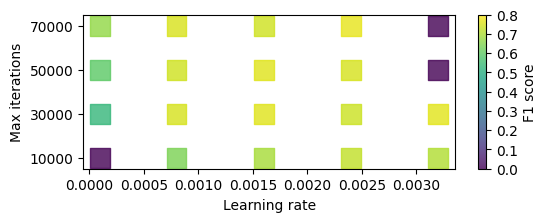

In [11]:
#graph
#base param
import numpy as np
import matplotlib.pyplot as plt

train_name_ori = "syn0_resize2_norm"  # 登録時の名前
val_name = "all_img_resize_norm"
train_folder = "coco_dir_train_syn0_resize2_norm"
test_folder = "coco_dir_all_img2_resize2_norm"
test_folder2 = "coco_dir_test_syn0_resize2_norm"



out_dir_name = "detectron2_trained_model_lr_maxiters_batch_app3"
annotation_file = os.path.join(wsl_pyf, train_folder, "annotations.json")
image_directory = os.path.join(wsl_pyf, train_folder)

# ============================================================
# Parameter grid
# ============================================================

BASE_LR = [0.0001,  0.0008, 0.0016, 0.0024, 0.0032]#[0.007]
MAX_ITER = [10000, 30000, 50000, 70000]

WEIGHT_DECAY = [None]
WARMUP_FACTOR = [None]
WARMUP_ITERS = [None]

IMS_batch = [1]
BATCH_SIZE_PER_IMAGE = [64]

ANCHOR_GENERATOR = [[8, 16, 32, 64, 128, 256, 512, 1024]]

FREEZE_AT = [None]

Gamma = [0.3]
Steps = [None]

ROI_POSITIVE = [0.8]
ROI_SCORE_THRESH = [0.1]

NMS_THRESH = [0.9]
NMS_THRESH_TEST = [0.9]

Model_names = [
    "Misc/cascade_mask_rcnn_X_152_32x8d_FPN_IN5k_gn_dconv.yaml"
]

PRE_TRAIN = [6000]
POST_TRAIN = [3000]
PRE_TEST = [6000]
POST_TEST = [3000]

batch_norm = "FrozenBN"
norm_size = [64]
ROI_Norm = "GN"

PS_Ratios = [None]


if batch_norm == "GN" or ROI_Norm == "GN":
    param_grid = [
        {
            "MODEL": m,
            "SOLVER.BASE_LR": lr,
            "SOLVER.MAX_ITER": max_iter,
            "SOLVER.WEIGHT_DECAY": wd,
            "SOLVER.WARMUP_FACTOR": wf,
            "SOLVER.WARMUP_ITERS": int(max_iter / 20),

            "IMS_PER_BATCH": ims_bs,
            "MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE": bs,
            "MODEL.ANCHOR_GENERATOR.SIZES": anchor,
            "MODEL.BACKBONE.FREEZE_AT": freeze,

            "SOLVER.GAMMA": g,
            "SOLVER.STEPS": (0.7 * max_iter, 0.9 * max_iter),

            "MODEL.ROI_HEADS.POSITIVE_FRACTION": posr,
            "MODEL.ROI_HEADS.SCORE_THRESH_TEST": score_th,
            "MODEL.RPN.NMS_THRESH": nms_th,
            "MODEL.ROI_HEADS.NMS_THRESH_TEST": nms_th_t,

            "MODEL.RPN.PRE_NMS_TOPK_TRAIN": pretr,
            "MODEL.RPN.POST_NMS_TOPK_TRAIN": posttr,
            "MODEL.RPN.PRE_NMS_TOPK_TEST": prete,
            "MODEL.RPN.POST_NMS_TOPK_TEST": postte,

            "MODEL.GROUP_NORM.NUM_GROUPS": nm_size,
            "MODEL.ROI_HEADS.POOLER_SAMPLING_RATIO": psr,
        }
        for (
            m,
            lr,
            max_iter,
            wd,
            wf,
            wi,
            ims_bs,
            bs,
            anchor,
            freeze,
            g,
            step,
            posr,
            score_th,
            nms_th,
            nms_th_t,
            pretr,
            posttr,
            prete,
            postte,
            nm_size,
            psr,
        )
        in itertools.product(
            Model_names,
            BASE_LR,
            MAX_ITER,
            WEIGHT_DECAY,
            WARMUP_FACTOR,
            WARMUP_ITERS,
            IMS_batch,
            BATCH_SIZE_PER_IMAGE,
            ANCHOR_GENERATOR,
            FREEZE_AT,
            Gamma,
            Steps,
            ROI_POSITIVE,
            ROI_SCORE_THRESH,
            NMS_THRESH,
            NMS_THRESH_TEST,
            PRE_TRAIN,
            POST_TRAIN,
            PRE_TEST,
            POST_TEST,
            norm_size,
            PS_Ratios,
        )
    ]

else:
    param_grid = [
        {
            "MODEL": m,
            "SOLVER.BASE_LR": lr,
            "SOLVER.MAX_ITER": max_iter,
            "SOLVER.WEIGHT_DECAY": wd,
            "SOLVER.WARMUP_FACTOR": wf,
            "SOLVER.WARMUP_ITERS": wi,

            "IMS_PER_BATCH": ims_bs,
            "MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE": bs,
            "MODEL.ANCHOR_GENERATOR.SIZES": anchor,
            "MODEL.BACKBONE.FREEZE_AT": freeze,

            "SOLVER.GAMMA": g,
            "SOLVER.STEPS": step,

            "MODEL.RPN.NMS_THRESH": nms_th,
            "MODEL.ROI_HEADS.NMS_THRESH_TEST": nms_th_t,

            "MODEL.ROI_HEADS.POOLER_SAMPLING_RATIO": psr,
        }
        for (
            m,
            lr,
            max_iter,
            wd,
            wf,
            wi,
            ims_bs,
            bs,
            anchor,
            freeze,
            g,
            step,
            nms_th,
            nms_th_t,
            psr,
        )
        in itertools.product(
            Model_names,
            BASE_LR,
            MAX_ITER,
            WEIGHT_DECAY,
            WARMUP_FACTOR,
            WARMUP_ITERS,
            IMS_batch,
            BATCH_SIZE_PER_IMAGE,
            ANCHOR_GENERATOR,
            FREEZE_AT,
            Gamma,
            Steps,
            NMS_THRESH,
            NMS_THRESH_TEST,
            PS_Ratios,
        )
    ]


# ============================================================
# Run grid search
# ============================================================

results = []
lr_li = []
max_iters_li = []
f1_score_li = []
for i, params in enumerate(param_grid):
#     print(params)
    lr_li.append(params['SOLVER.BASE_LR'])
    max_iters_li.append(params['SOLVER.MAX_ITER'])
    
    cfg_tmp = setup_cfg(
        params=params,
        train_dataset_name=train_name_ori,
        output_dir=None
        
#         for_eval=False,
    )

    train_name = build_train_name(train_name_ori, params, cfg_tmp)

    custom_output_dir = os.path.join(
        wsl_pyf,
        out_dir_name,
        train_name,
    )
    
    test_dir =os.path.join(custom_output_dir , test_folder2)
    if os.path.exists(test_dir + "/" + "fscore.csv"):
        f1_score = np.nanmean(np.loadtxt( test_dir + "/" + "fscore.csv",  delimiter=','))
    else:
        f1_score =0
    f1_score_li.append(f1_score)
    

# 念のため numpy 配列に変換
x = np.array(lr_li, dtype=float)
y = np.array(max_iters_li, dtype=float)
c = np.array(f1_score_li, dtype=float)

plt.figure(figsize=(6, 2))

vmin = 0.
vmax = 0.8

sc = plt.scatter(
    x,
    y,
    c=c,
    marker="s",
    s=200,
    alpha=0.8,
    vmin=vmin,
    vmax=vmax,
)

cbar = plt.colorbar(sc)
cbar.set_label("F1 score")
cbar.set_ticks(np.arange(vmin, vmax + 0.001, 0.1))

plt.xlabel("Learning rate")
plt.ylabel("Max iterations")
plt.ylim(5000, 75000)
plt.yticks(np.arange(10000, 71000, 20000))
plt.savefig(fig_dir + "syn_cascade_lr_maxiter_f1.SVG")

plt.show()

In [16]:
lr0.0004_maxiter10000_wd0.0001_wf0.001_wi500_imsbs1_bs64_freeze2_gamma0.3_steps7000.0-9000.0_posr0.8_scoreth0.1_nmsth0.9_nmstht0.9_pretr6000_posttr3000_prete6000_postte3000_RESnormFrozenBN_ROInormGN

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0.])

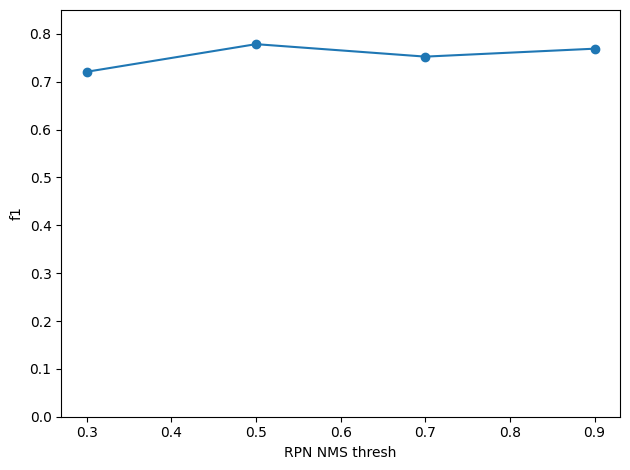

In [43]:
BASE_LR = [0.0024]#[0.007]
MAX_ITER = [70000]

WEIGHT_DECAY = [None]
WARMUP_FACTOR = [None]
WARMUP_ITERS = [None]

IMS_batch = [1]
BATCH_SIZE_PER_IMAGE = [64]

ANCHOR_GENERATOR = [[8, 16, 32, 64, 128, 256, 512, 1024]]

FREEZE_AT = [None]

Gamma = [0.3]
Steps = [None]

ROI_POSITIVE = [0.8]
ROI_SCORE_THRESH = [0.1]#, 0.3, 0.5, 0.7]

NMS_THRESH = [0.3, 0.5, 0.7, 0.9]
NMS_THRESH_TEST = [0.9]

Model_names = [
    "Misc/cascade_mask_rcnn_X_152_32x8d_FPN_IN5k_gn_dconv.yaml"
]

PRE_TRAIN = [6000]
POST_TRAIN = [3000]
PRE_TEST = [6000]
POST_TEST = [3000]

batch_norm = "FrozenBN"
norm_size = [64]
ROI_Norm = "GN"

PS_Ratios = [None]



param_grid = [
    {
        "MODEL": m,
        "SOLVER.BASE_LR": lr,
        "SOLVER.MAX_ITER": max_iter,
        "SOLVER.WEIGHT_DECAY": wd,
        "SOLVER.WARMUP_FACTOR": wf,
        "SOLVER.WARMUP_ITERS": int(max_iter / 20),

        "IMS_PER_BATCH": ims_bs,
        "MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE": bs,
        "MODEL.ANCHOR_GENERATOR.SIZES": anchor,
        "MODEL.BACKBONE.FREEZE_AT": freeze,

        "SOLVER.GAMMA": g,
        "SOLVER.STEPS": (0.7 * max_iter, 0.9 * max_iter),

        "MODEL.ROI_HEADS.POSITIVE_FRACTION": posr,
        "MODEL.ROI_HEADS.SCORE_THRESH_TEST": score_th,
        "MODEL.RPN.NMS_THRESH": nms_th,
        "MODEL.ROI_HEADS.NMS_THRESH_TEST": nms_th_t,

        "MODEL.RPN.PRE_NMS_TOPK_TRAIN": pretr,
        "MODEL.RPN.POST_NMS_TOPK_TRAIN": posttr,
        "MODEL.RPN.PRE_NMS_TOPK_TEST": prete,
        "MODEL.RPN.POST_NMS_TOPK_TEST": postte,

        "MODEL.GROUP_NORM.NUM_GROUPS": nm_size,
        "MODEL.ROI_HEADS.POOLER_SAMPLING_RATIO": psr,
    }
    for (
        m,
        lr,
        max_iter,
        wd,
        wf,
        wi,
        ims_bs,
        bs,
        anchor,
        freeze,
        g,
        step,
        posr,
        score_th,
        nms_th,
        nms_th_t,
        pretr,
        posttr,
        prete,
        postte,
        nm_size,
        psr,
    )
    in itertools.product(
        Model_names,
        BASE_LR,
        MAX_ITER,
        WEIGHT_DECAY,
        WARMUP_FACTOR,
        WARMUP_ITERS,
        IMS_batch,
        BATCH_SIZE_PER_IMAGE,
        ANCHOR_GENERATOR,
        FREEZE_AT,
        Gamma,
        Steps,
        ROI_POSITIVE,
        ROI_SCORE_THRESH,
        NMS_THRESH,
        NMS_THRESH_TEST,
        PRE_TRAIN,
        POST_TRAIN,
        PRE_TEST,
        POST_TEST,
        norm_size,
        PS_Ratios,
    )
]




# ============================================================
# Run grid search
# ============================================================


ROI_scoreth_li = []
# max_iters_li = []
f1_score_li = []
for i, params in enumerate(param_grid):
#     print(params)
    ROI_scoreth_li.append(params['MODEL.RPN.NMS_THRESH'])
    
    
    cfg_tmp = setup_cfg(
        params=params,
        train_dataset_name=train_name_ori,
        output_dir=None,
#         for_eval=False,
    )

    train_name = build_train_name(train_name_ori, params, cfg_tmp)

    custom_output_dir = os.path.join(
        wsl_pyf,
        out_dir_name,
        train_name,
    )
    
    test_dir =os.path.join(custom_output_dir , test_folder2)
    if os.path.exists(test_dir + "/" + "fscore.csv"):
        f1_score = np.nanmean(np.loadtxt( test_dir + "/" + "fscore.csv",  delimiter=','))
    else:
        f1_score =0
    f1_score_li.append(f1_score)
    

# plt.figure(figsize=(6, 2))

plt.plot(
    ROI_scoreth_li,
    f1_score_li,
#     c=c,
#     marker ="s",
#     s=200,       # 点の大きさ
    
#     alpha=0.8
)
plt.scatter(
    ROI_scoreth_li,
    f1_score_li,
#     c=c,
#     marker ="s",
#     s=200,       # 点の大きさ
    
#     alpha=0.8
)

plt.xlabel("RPN NMS thresh")
plt.ylabel("f1")
# plt.ylim(5000, 55000)
# plt.yticks(np.arange(10000, 51000, 20000))
# plt.title("F1 score across hyperparameter settings")

# learning rate は対数軸にすると見やすいことが多い
# plt.xscale("log")
plt.ylim(0, 0.85)
plt.tight_layout()
plt.savefig(fig_dir + "syn_cascade_lr{}_maxiter{}_NMSthresh_f1.SVG".format(BASE_LR[0], MAX_ITER[0]))

plt.show()

In [34]:
ROI_scoreth_li

[0.3, 0.5, 0.7, 0.9]

In [35]:
f1_score_li

[]

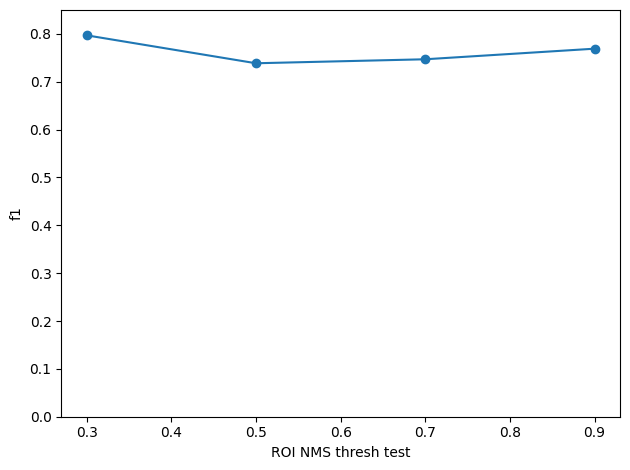

In [18]:
import matplotlib.pyplot as plt
BASE_LR = [0.0024]#[0.007]
MAX_ITER = [70000]

WEIGHT_DECAY = [None]
WARMUP_FACTOR = [None]
WARMUP_ITERS = [None]

IMS_batch = [1]
BATCH_SIZE_PER_IMAGE = [64]

ANCHOR_GENERATOR = [[8, 16, 32, 64, 128, 256, 512]]

FREEZE_AT = [None]

Gamma = [0.3]
Steps = [None]

ROI_POSITIVE = [0.8]
ROI_SCORE_THRESH = [0.1]#, 0.3, 0.5, 0.7]

NMS_THRESH = [0.9]
NMS_THRESH_TEST = [0.3, 0.5, 0.7, 0.9]

Model_names = [
    "Misc/cascade_mask_rcnn_X_152_32x8d_FPN_IN5k_gn_dconv.yaml"
]

PRE_TRAIN = [6000]
POST_TRAIN = [3000]
PRE_TEST = [6000]
POST_TEST = [3000]

batch_norm = "FrozenBN"
norm_size = [64]
ROI_Norm = "GN"

PS_Ratios = [None]



param_grid = [
    {
        "MODEL": m,
        "SOLVER.BASE_LR": lr,
        "SOLVER.MAX_ITER": max_iter,
        "SOLVER.WEIGHT_DECAY": wd,
        "SOLVER.WARMUP_FACTOR": wf,
        "SOLVER.WARMUP_ITERS": int(max_iter / 20),

        "IMS_PER_BATCH": ims_bs,
        "MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE": bs,
        "MODEL.ANCHOR_GENERATOR.SIZES": anchor,
        "MODEL.BACKBONE.FREEZE_AT": freeze,

        "SOLVER.GAMMA": g,
        "SOLVER.STEPS": (0.7 * max_iter, 0.9 * max_iter),

        "MODEL.ROI_HEADS.POSITIVE_FRACTION": posr,
        "MODEL.ROI_HEADS.SCORE_THRESH_TEST": score_th,
        "MODEL.RPN.NMS_THRESH": nms_th,
        "MODEL.ROI_HEADS.NMS_THRESH_TEST": nms_th_t,

        "MODEL.RPN.PRE_NMS_TOPK_TRAIN": pretr,
        "MODEL.RPN.POST_NMS_TOPK_TRAIN": posttr,
        "MODEL.RPN.PRE_NMS_TOPK_TEST": prete,
        "MODEL.RPN.POST_NMS_TOPK_TEST": postte,

        "MODEL.GROUP_NORM.NUM_GROUPS": nm_size,
        "MODEL.ROI_HEADS.POOLER_SAMPLING_RATIO": psr,
    }
    for (
        m,
        lr,
        max_iter,
        wd,
        wf,
        wi,
        ims_bs,
        bs,
        anchor,
        freeze,
        g,
        step,
        posr,
        score_th,
        nms_th,
        nms_th_t,
        pretr,
        posttr,
        prete,
        postte,
        nm_size,
        psr,
    )
    in itertools.product(
        Model_names,
        BASE_LR,
        MAX_ITER,
        WEIGHT_DECAY,
        WARMUP_FACTOR,
        WARMUP_ITERS,
        IMS_batch,
        BATCH_SIZE_PER_IMAGE,
        ANCHOR_GENERATOR,
        FREEZE_AT,
        Gamma,
        Steps,
        ROI_POSITIVE,
        ROI_SCORE_THRESH,
        NMS_THRESH,
        NMS_THRESH_TEST,
        PRE_TRAIN,
        POST_TRAIN,
        PRE_TEST,
        POST_TEST,
        norm_size,
        PS_Ratios,
    )
]




# ============================================================
# Run grid search
# ============================================================


ROI_scoreth_li = []
# max_iters_li = []
f1_score_li = []
for i, params in enumerate(param_grid):
#     print(params)
    ROI_scoreth_li.append(params['MODEL.ROI_HEADS.NMS_THRESH_TEST'])
    
    
    cfg_tmp = setup_cfg(
        params=params,
        train_dataset_name=train_name_ori,
        output_dir=None,
#         for_eval=False,
    )

    train_name = build_train_name(train_name_ori, params, cfg_tmp)

    custom_output_dir = os.path.join(
        wsl_pyf,
        out_dir_name,
        train_name,
    )
    
    test_dir =os.path.join(custom_output_dir , test_folder2)
    if os.path.exists(test_dir + "/" + "fscore.csv"):
        f1_score = np.nanmean(np.loadtxt( test_dir + "/" + "fscore.csv",  delimiter=','))
    else:
        f1_score =0
    f1_score_li.append(f1_score)
    

# plt.figure(figsize=(6, 2))

plt.plot(
    ROI_scoreth_li,
    f1_score_li,
#     c=c,
#     marker ="s",
#     s=200,       # 点の大きさ
    
#     alpha=0.8
)
plt.scatter(
    ROI_scoreth_li,
    f1_score_li,
#     c=c,
#     marker ="s",
#     s=200,       # 点の大きさ
    
#     alpha=0.8
)

plt.xlabel("ROI NMS thresh test")
plt.ylabel("f1")
# plt.ylim(5000, 55000)
# plt.yticks(np.arange(10000, 51000, 20000))
# plt.title("F1 score across hyperparameter settings")

# learning rate は対数軸にすると見やすいことが多い
# plt.xscale("log")
plt.ylim(0, 0.85)
plt.tight_layout()
plt.savefig(fig_dir + "syn_cascade_lr{}_maxiter{}_ROINMStestthresh_f1.SVG".format(BASE_LR[0], MAX_ITER[0]))

plt.show()

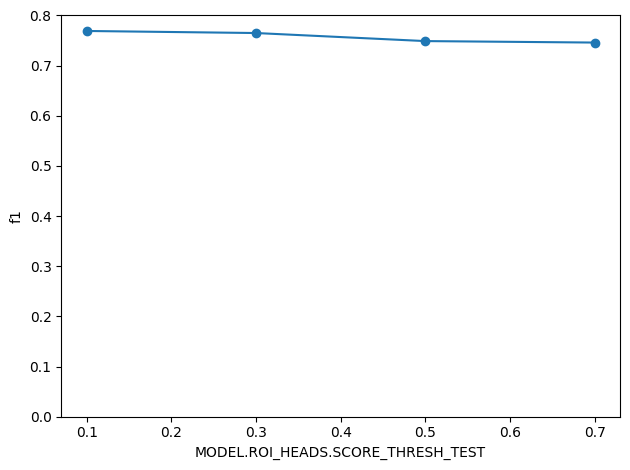

In [41]:
BASE_LR = [0.0024]#[0.007]
MAX_ITER = [70000]

WEIGHT_DECAY = [None]
WARMUP_FACTOR = [None]
WARMUP_ITERS = [None]

IMS_batch = [1]
BATCH_SIZE_PER_IMAGE = [64]

ANCHOR_GENERATOR = [[8, 16, 32, 64, 128, 256, 512]]

FREEZE_AT = [None]

Gamma = [0.3]
Steps = [None]

ROI_POSITIVE = [0.8]
ROI_SCORE_THRESH = [0.1, 0.3, 0.5, 0.7]

NMS_THRESH = [0.9]
NMS_THRESH_TEST = [0.9]

Model_names = [
    "Misc/cascade_mask_rcnn_X_152_32x8d_FPN_IN5k_gn_dconv.yaml"
]

PRE_TRAIN = [6000]
POST_TRAIN = [3000]
PRE_TEST = [6000]
POST_TEST = [3000]

batch_norm = "FrozenBN"
norm_size = [64]
ROI_Norm = "GN"

PS_Ratios = [None]



param_grid = [
    {
        "MODEL": m,
        "SOLVER.BASE_LR": lr,
        "SOLVER.MAX_ITER": max_iter,
        "SOLVER.WEIGHT_DECAY": wd,
        "SOLVER.WARMUP_FACTOR": wf,
        "SOLVER.WARMUP_ITERS": int(max_iter / 20),

        "IMS_PER_BATCH": ims_bs,
        "MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE": bs,
        "MODEL.ANCHOR_GENERATOR.SIZES": anchor,
        "MODEL.BACKBONE.FREEZE_AT": freeze,

        "SOLVER.GAMMA": g,
        "SOLVER.STEPS": (0.7 * max_iter, 0.9 * max_iter),

        "MODEL.ROI_HEADS.POSITIVE_FRACTION": posr,
        "MODEL.ROI_HEADS.SCORE_THRESH_TEST": score_th,
        "MODEL.RPN.NMS_THRESH": nms_th,
        "MODEL.ROI_HEADS.NMS_THRESH_TEST": nms_th_t,

        "MODEL.RPN.PRE_NMS_TOPK_TRAIN": pretr,
        "MODEL.RPN.POST_NMS_TOPK_TRAIN": posttr,
        "MODEL.RPN.PRE_NMS_TOPK_TEST": prete,
        "MODEL.RPN.POST_NMS_TOPK_TEST": postte,

        "MODEL.GROUP_NORM.NUM_GROUPS": nm_size,
        "MODEL.ROI_HEADS.POOLER_SAMPLING_RATIO": psr,
    }
    for (
        m,
        lr,
        max_iter,
        wd,
        wf,
        wi,
        ims_bs,
        bs,
        anchor,
        freeze,
        g,
        step,
        posr,
        score_th,
        nms_th,
        nms_th_t,
        pretr,
        posttr,
        prete,
        postte,
        nm_size,
        psr,
    )
    in itertools.product(
        Model_names,
        BASE_LR,
        MAX_ITER,
        WEIGHT_DECAY,
        WARMUP_FACTOR,
        WARMUP_ITERS,
        IMS_batch,
        BATCH_SIZE_PER_IMAGE,
        ANCHOR_GENERATOR,
        FREEZE_AT,
        Gamma,
        Steps,
        ROI_POSITIVE,
        ROI_SCORE_THRESH,
        NMS_THRESH,
        NMS_THRESH_TEST,
        PRE_TRAIN,
        POST_TRAIN,
        PRE_TEST,
        POST_TEST,
        norm_size,
        PS_Ratios,
    )
]




# ============================================================
# Run grid search
# ============================================================


ROI_scoreth_li = []
# max_iters_li = []
f1_score_li = []
for i, params in enumerate(param_grid):
#     print(params)
    ROI_scoreth_li.append(params['MODEL.ROI_HEADS.SCORE_THRESH_TEST'])
    
    
    cfg_tmp = setup_cfg(
        params=params,
        train_dataset_name=train_name_ori,
        output_dir=None,
#         for_eval=False,
    )

    train_name = build_train_name(train_name_ori, params, cfg_tmp)

    custom_output_dir = os.path.join(
        wsl_pyf,
        out_dir_name,
        train_name,
    )
    
    test_dir =os.path.join(custom_output_dir , test_folder2)
    if os.path.exists(test_dir + "/" + "fscore.csv"):
        f1_score = np.nanmean(np.loadtxt( test_dir + "/" + "fscore.csv",  delimiter=','))
    else:
        f1_score =0
    f1_score_li.append(f1_score)
    

# plt.figure(figsize=(6, 2))

plt.plot(
    ROI_scoreth_li,
    f1_score_li,
#     c=c,
#     marker ="s",
#     s=200,       # 点の大きさ
    
#     alpha=0.8
)
plt.scatter(
    ROI_scoreth_li,
    f1_score_li,
#     c=c,
#     marker ="s",
#     s=200,       # 点の大きさ
    
#     alpha=0.8
)

plt.xlabel("MODEL.ROI_HEADS.SCORE_THRESH_TEST")
plt.ylabel("f1")
# plt.ylim(5000, 55000)
# plt.yticks(np.arange(10000, 51000, 20000))
# plt.title("F1 score across hyperparameter settings")

# learning rate は対数軸にすると見やすいことが多い
# plt.xscale("log")
plt.ylim(0,0.8)
plt.tight_layout()
plt.savefig(fig_dir + "syn_cascade_lr{}_maxiter{}_ROIscoreth_f1.SVG".format(BASE_LR[0], MAX_ITER[0]))

plt.show()

In [ ]:
#conbine results after applying the best model to all images
mix_dir = wsl_pyf + "/"+ out_dir_name + "/" + mix_name + "/" + best_model +"/"
os.makedirs(mix_dir, exist_ok=True)
#filter by vec
# 評価用設定に変更

#applied to test datasets
#     threshold =   #remove masks duplicated %
#     area_th = 300
#                         img_fol_name = test_folder_syn#"coco_dir_test_syn_resize"
img_fol = wsl_pyf + "/"+all_img_fol

data_syn_dir =  syn_dir "/"+ all_img_fol + "/" 
data_vec_dir = vec_dir "/"+ all_img_fol + "/" 
# if overlap_del == True:                           
save_fol_syn = mix_dir + "/"+  all_img_fol +"_syn"  +"/"
os.makedirs(save_fol_syn, exist_ok=True)
save_fol_vec = mix_dir + "/"+  all_img_fol  + "_vec"+"/"
os.makedirs(save_fol_vec, exist_ok=True)


for k, fname in enumerate(img_fol):
    # if n>0:
    #     continue
    print(fname)
    im = cv2.imread(img_fol + "/"+fname) #tifffile.imread(imgPath) #

    # outputs["instances"] 
    with open(data_syn_dir + "/" + fname.replace(".jpg",".pkl"), 'rb') as f:
        syn_instances =  pickle.load(f)

    with open(data_vec_dir + "/" + fname.replace(".jpg",".pkl"), 'rb') as f:
        vec_instances =  pickle.load(f)

    syn_ind= np.where(syn_instances.pred_classes == 0)[0]
    az_ind= np.where(syn_instances.pred_classes == 1)[0] 
    vec_ind= np.where(vec_instances.pred_classes == 0)[0]

    vec_masks = np.array(vec_instances.pred_masks[vec_ind])
    syn_masks = np.array(syn_instances.pred_masks[syn_ind])
    az_masks = np.array(syn_instances.pred_masks[az_ind])

    #select synapses including more than 10 vesicles
    syn_inc_vec_ind = []
    vec_in_syn_ind = []
    for l, syn_mask in enumerate(syn_masks):
        vec_syn_ind, centroids = extract_vec_indices_by_synapse(syn_mask, vec_masks)
        if len(vec_syn_ind) >= 10:
            syn_az_inds = get_candidate_info2(syn_mask, az_masks, distance_threshold)
            if len(syn_az_inds) != 0:
                #add presyn with az to list

                syn_inc_vec_ind.append(syn_ind[l])
                #add candidate az_ind to list
                for o in syn_az_inds:
                    syn_inc_vec_ind.append(az_ind[o])

                vec_in_syn_ind.append(vec_syn_ind)

    vec_in_syn_ind = list(itertools.chain.from_iterable(vec_in_syn_ind))
        # フィルタリング後の Instances を作成
    syn_instances = syn_instances[syn_inc_vec_ind]
    vec_instances = vec_instances[vec_in_syn_ind]

    with open(save_fol_syn + "/" + fname.replace(".jpg",".pkl"), 'wb') as f:
        pickle.dump(syn_instances, f)

    with open(save_fol_vec + "/" + fname.replace(".jpg",".pkl"), 'wb') as f:
        pickle.dump(vec_instances, f)

    # ----- 可視化（filtered syn
    cfg = get_cfg()
    cfg.DATASETS.TRAIN = (train_name_ori_syn,)
    # bounding box の数に合わせた空文字列のリストを作成（ラベルの記述が不要な場合）
    empty_labels = [""] * len(syn_instances)
    # Metadata の取得（学習時のデータセットのメタ情報）
    metadata = MetadataCatalog.get(cfg.DATASETS.TRAIN[0])
    v = Visualizer(im[:, :, ::-1], metadata, scale=0.8)
    # overlay_instances() を呼び出して、bounding box のみ描画（labels は空文字なので何も表示されない）
    v = v.overlay_instances(
        boxes=syn_instances.pred_boxes,
        labels=empty_labels,
        assigned_colors=None  # または None のままでも OK。既定の色が使われる
    )
    result_image = v.get_image()[:, :, ::-1]
    cv2.imwrite(save_fol_syn + "/" + fname, result_image)
    


    # ----- 可視化 filtered vec
    cfg = get_cfg()
    cfg.DATASETS.TRAIN = (train_name_ori_vec,)
    # bounding box の数に合わせた空文字列のリストを作成（ラベルの記述が不要な場合）
    empty_labels = [""] * len(vec_instances)
    # Metadata の取得（学習時のデータセットのメタ情報）
    metadata = MetadataCatalog.get(cfg.DATASETS.TRAIN[0])
    v = Visualizer(im[:, :, ::-1], metadata, scale=0.8)
    # overlay_instances() を呼び出して、bounding box のみ描画（labels は空文字なので何も表示されない）
    v = v.overlay_instances(
        boxes=vec_instances.pred_boxes,
        labels=empty_labels,
        assigned_colors=None  # または None のままでも OK。既定の色が使われる
    )
    result_image = v.get_image()[:, :, ::-1]
    cv2.imwrite(save_fol_vec + "/" + fname, result_image)


In [ ]:
def mask_to_polygons(mask: np.ndarray, 
                     approx_eps: float = 1.0
                    ) -> list[list[tuple[int,int]]]:
    """
    2D の bool/0–1 マスクから輪郭を検出し、
    各輪郭を [(x0,y0), (x1,y1), ...] のリストとして返す。

    approx_eps: 輪郭近似の許容誤差 (ピクセル)。0 にするとそのまま生の輪郭点を返す。
    """
    # uint8 化 + 255
    mask_u8 = (mask.astype(np.uint8)) * 255

    # 外周輪郭のみを取得、点群は簡易化 (CHAIN_APPROX_SIMPLE)
    contours, _ = cv2.findContours(
        mask_u8,
        mode = cv2.RETR_EXTERNAL,
        method = cv2.CHAIN_APPROX_SIMPLE
    )

    polys: list[list[tuple[int,int]]] = []
    for cnt in contours:
        # 輪郭点を近似する (省略可)
        if approx_eps > 0:
            cnt = cv2.approxPolyDP(cnt, epsilon=approx_eps, closed=True)
        # reshape & (x,y) タプル化
        coords = cnt.reshape(-1, 2)
        poly = [(int(x), int(y)) for x, y in coords]
        # (面積が小さすぎる輪郭は破棄する場合などフィルタ可)
        if len(poly) >= 3:
            polys.append(poly)

    return polys

# --- 使い方例 ---
# mask: 2D boolean または 0/1 ndarray
# mask = np.load("your_mask.npy")  # 例

polygons = mask_to_polygons(mask, approx_eps=1.0)

In [28]:
#convert masks -> polygon cords

img_fol = wsl_pyf + "/"+all_img_fol


for k, fname in enumerate(img_fol):
    with open(save_fol_vec + "/" + fname.replace(".jpg",".pkl"), 'wb') as f:
        vec_instances = pickle.load(f)
        vec_masks = vec_instances.pred_masks().cpu().numpy() 
        polygons = []
        for vec_mask in vec_masks:
            polygons.append(mask_to_polygons(vec_mask, approx_eps=1.0))
            
        

Instances(num_instances=71, image_height=656, image_width=1000, fields=[pred_boxes: Boxes(tensor([[390.4451, 358.1807, 397.1867, 364.9704],
        [386.9026, 325.8001, 393.4823, 332.0329],
        [386.8617, 327.0999, 393.4079, 333.3948],
        [379.8443, 344.0096, 386.7499, 350.8461],
        [363.5252, 318.9894, 370.2656, 325.2886],
        [363.7113, 321.0401, 370.6058, 327.7553],
        [360.2538, 331.7746, 366.9236, 337.8736],
        [380.6919, 325.2674, 387.3158, 331.4936],
        [369.9776, 331.2331, 376.6244, 337.4735],
        [381.0793, 355.0741, 387.5010, 361.3031],
        [380.4169, 342.0198, 387.1177, 348.6479],
        [344.3687, 322.1088, 350.8456, 328.0559],
        [350.5384, 311.6678, 356.8313, 317.3353],
        [370.5672, 331.4600, 377.1105, 337.7018],
        [370.2619, 318.7718, 376.9574, 324.8884],
        [380.7947, 357.0227, 387.4709, 363.5472],
        [360.5089, 334.0742, 367.1284, 340.1965],
        [382.8643, 355.0686, 389.2390, 361.1862],
        [3